# MouseLab — ۳۲ درس تکمیلی برای فهم عمیق آمار و دیتا

## هدف و نقشهٔ راه

این مسیر مکملِ دورهٔ ۴۹درسی است؛ تکرار آن نیست. از تعریف کمیت هدف و احتمال شرطی به استنباط بیزی، آزمایش، مدل‌های تعمیم‌یافته، علیت، دادهٔ گمشده، منظم‌سازی، کالیبراسیون، Conformal و کیفیت داده می‌رسیم. هر درس یک پرسش ملموس، مفهوم تخصصی با زبان ساده، فرمول، مثال حل‌شده، کد و نمودار قابل ویرایش، تفسیر محاسبه‌شده، دام رایج و تمرین با پاسخ دارد.

همهٔ داده‌های این ۳۲ درس **ساختگی و با سازوکار صریح** هستند؛ عددهای «حقیقت» فقط پارامترهای معلوم شبیه‌سازی‌اند، نه آمار بازار یا پژوهش واقعی. استفادهٔ آموزشی از دادهٔ مصنوعی کمک می‌کند علت خطای روش را ببینیم؛ برای تصمیم عملی باید داده و طرحِ مسئلهٔ خود را بررسی کنید. هیچ توصیهٔ پزشکی، حقوقی یا مالیِ فردی از مثال‌ها استخراج نمی‌شود.

برای احتمال و نمونه‌گیری، درس‌های۱–۸؛ استنباط و آزمایش۹–۱۶؛ علیت و مدل پایدار۱۷–۲۴؛ اعتماد به پیش‌بینی و مسئولیت۲۵–۳۲ را بخوانید. این مسیر، مبانی و چند موضوع پیشرفتهٔ مهم را پوشش می‌دهد؛ جای دورهٔ تخصصی کامل هر شاخه را نمی‌گیرد.

## آماده‌سازی و اجرا

در Colab روی Runtime → Run all بزنید. CPU کافی است. ورودی خارجی، رمز و GPU لازم نیست؛ نصب بسته‌های گمشده به اینترنت نیاز دارد. هر سلول درس بذر خودش را بازنشانی می‌کند تا تغییر ترتیب آزمایش‌های تصادفی خروجی بقیه را عوض نکند. متن مثال مرجع ثابت است؛ «تفسیر اجرای حاضر» از متغیرهای همان اجرا ساخته می‌شود. محور نمودارها برای سازگاری با محیط‌های Colab انگلیسی و تفسیرها فارسی‌اند.


In [1]:
import os,sys,importlib.util,subprocess
os.environ['OMP_NUM_THREADS']='1'
os.environ['OPENBLAS_NUM_THREADS']='1'
os.environ['MKL_NUM_THREADS']='1'
required={'numpy':'numpy','pandas':'pandas','scipy':'scipy','matplotlib':'matplotlib','sklearn':'scikit-learn','statsmodels':'statsmodels'}
missing=[package for module,package in required.items() if importlib.util.find_spec(module) is None]
if missing: subprocess.check_call([sys.executable,'-m','pip','install','-q',*missing])
import numpy as np,pandas as pd,scipy,sklearn,statsmodels,matplotlib
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from IPython.display import display,Markdown
from sklearn.metrics import mean_squared_error
from sklearn.pipeline import make_pipeline
BLUE,GOLD,TEAL='#277f9f','#c08b2c','#278b80'
plt.rcParams.update({'figure.figsize':(8,4.5),'figure.dpi':110,'font.size':10,'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15,'axes.prop_cycle':matplotlib.cycler(color=[BLUE,GOLD,TEAL]),'savefig.bbox':'tight'})
def show(): plt.show(); plt.close('all')
def say(text): display(Markdown('**تفسیر خروجی اجرای حاضر:** '+text))
print('Python',sys.version.split()[0],'| NumPy',np.__version__,'| pandas',pd.__version__,'| SciPy',scipy.__version__,'| scikit-learn',sklearn.__version__,'| statsmodels',statsmodels.__version__)

Python 3.12.14 | NumPy 2.2.6 | pandas 2.3.3 | SciPy 1.15.3 | scikit-learn 1.7.2 | statsmodels 0.14.5


## فصل ۱ · زبان داده و احتمال

### درس 01. قبل از عدد: سؤال، نوع داده و کمیتی که می‌خواهیم بدانیم

**پرسش شروع:** دو فروشگاه هر دو «۹۰٪ موفقیت» اعلام می‌کنند؛ آیا واقعاً برابرند؟

#### مفهوم، دقیق اما ساده

آمار با انتخاب آزمون شروع نمی‌شود؛ با تعریف کمیت هدف یا estimand شروع می‌شود. می‌خواهیم میانگین زمان انتظار هر فرد را بدانیم، نسبت سفارش‌های موفق را، یا اثر تغییر طراحی را؟ واحد مشاهده، جامعه، بازهٔ زمانی، صورت و مخرج باید روشن باشند. شناسه عددی است اما اندازهٔ کمّی نیست؛ شهر متغیر اسمی است؛ رتبهٔ رضایت ترتیبی است و فاصلهٔ بین رتبه‌ها لزوماً برابر نیست. تعداد خرید گسسته و زمان پاسخ پیوسته است. انتخاب میانگین، میانه یا نسبت باید با این معنا سازگار باشد. اگر یک فرد ده سفارش داشته باشد، میانگین سفارش‌ها همان میانگین افراد نیست. هر دو ممکن است مفید باشند، اما پرسش متفاوتی را پاسخ می‌دهند.

#### فرمول و قرارداد

```text
Overall rate = sum(successes) / sum(eligible trials)
Unweighted average of rates answers a different question.
```

#### مثال حل‌شده

در فروشگاه کوچک، ۹ موفقیت از ۱۰ تلاش و در فروشگاه بزرگ ۵۰ موفقیت از ۱۰۰ تلاش داریم. میانگین سادهٔ نرخ‌ها ۷۰٪ می‌شود؛ ولی نرخ هر تلاش در مجموع ۵۹÷۱۱۰≈۵۳٫۶۴٪ است. عدد اول هر فروشگاه را یک واحد با وزن برابر می‌بیند، عدد دوم هر تلاش را. مثال دوم: درآمدهای ۱۰، ۱۰ و ۱۰۰ میانگین ۴۰ و میانهٔ ۱۰ دارند؛ «کاربر معمولی» با «درآمد به ازای هر کاربر» یک سؤال نیست.

,shop,success,trials,rate
0,Small,9,10,0.9
1,Large,50,100,0.5


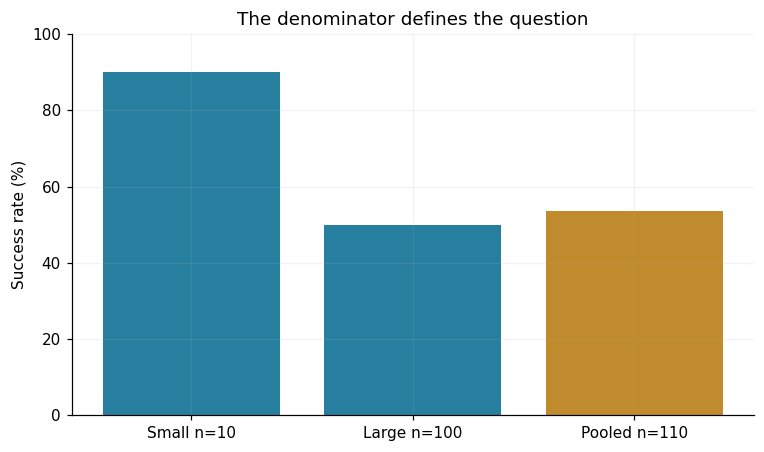

**تفسیر خروجی اجرای حاضر:** میانگین بدون وزن=70.00%؛ نرخ هر تلاش در کل=53.64%. تفاوت، خطای گردکردن نیست؛ کمیت هدف و وزن‌ها متفاوت‌اند.

In [2]:
rng=np.random.default_rng(202601)
success=np.array([9,50]); total=np.array([10,100]); rates=success/total
pooled=success.sum()/total.sum(); unweighted=rates.mean()
display(pd.DataFrame({'shop':['Small','Large'],'success':success,'trials':total,'rate':rates}))
fig,ax=plt.subplots(); ax.bar(['Small n=10','Large n=100','Pooled n=110'],100*np.r_[rates,pooled],color=[BLUE,BLUE,GOLD]); ax.set(ylabel='Success rate (%)',ylim=(0,100),title='The denominator defines the question'); show()
say(f'میانگین بدون وزن={unweighted:.2%}؛ نرخ هر تلاش در کل={pooled:.2%}. تفاوت، خطای گردکردن نیست؛ کمیت هدف و وزن‌ها متفاوت‌اند.')

#### راهنمای خواندن نمودار و نتیجه

در نمودار، ارتفاع ستون نرخ و برچسب n حجم مخرج را نشان می‌دهد. نرخ تجمیعی بین دو نرخ قرار می‌گیرد و به گروه بزرگ‌تر نزدیک‌تر است. در جدول به جای نگاه‌کردن صرف به درصد، موفقیت و تعداد تلاش را با هم بخوانید. هیچ‌کدام از این اعداد علت عملکرد دو فروشگاه را نمی‌گویند.

#### دام رایج

میانگین درصدها بدون وزن، ترکیب جمعیت را پنهان می‌کند. نسبتِ مجموع‌ها را هم وقتی مخرج‌ها هم‌پوشان‌اند یا تعریف متفاوت دارند، کورکورانه نسازید.

#### تمرین

برای «رضایت کاربران»، هر سفارش باید وزن برابر بگیرد یا هر شخص؟

#### پاسخ تشریحی

به هدف بستگی دارد. برای تجربهٔ فرد معمولی، ابتدا خلاصهٔ هر فرد را بسازید و سپس افراد را وزن دهید. برای کیفیت هر تعامل، سفارش واحد تحلیل است؛ وابستگی سفارش‌های یک فرد را در عدم‌قطعیت لحاظ کنید.

### درس 02. احتمال شرطی، استقلال و وابستگی

**پرسش شروع:** احتمال دیررسیدن بسته در روز بارانی با احتمال باران در روزِ دیررسیدن یکی نیست.

#### مفهوم، دقیق اما ساده

احتمال شرطی فضای مرجع را کوچک می‌کند: P(A|B) فقط بین مواردی حساب می‌شود که B برقرار است. استقلال یعنی دانستن B احتمال A را تغییر ندهد؛ صفر بودن همبستگی خطی به‌طور کلی استقلال نیست. رویدادهای ناسازگار با احتمال مثبت مستقل نیستند: اگر رخداد یکی دیگری را ناممکن کند، اطلاعات مهمی منتقل شده است. استقلال شرطی نیز با استقلال حاشیه‌ای فرق دارد؛ دو رفتار ممکن است پس از ثابت‌کردن ساعت روز مستقل شوند یا برعکس با انتخاب یک زیرگروه وابسته شوند. در یک جدول فراوانی، هر بار دقیقاً مشخص کنید کدام سطر، ستون یا کل جدول مخرج است.

#### فرمول و قرارداد

```text
P(A|B)=P(A∩B)/P(B), P(B)>0
Independence: P(A∩B)=P(A)P(B)
```

#### مثال حل‌شده

از ۱۰۰ روز ساخته‌شده، ۲۰ روز بارانی است. در ۱۲ روز بارانی و ۸ روز بدون باران بسته دیر رسیده است. بنابراین P(تأخیر|باران)=۱۲÷۲۰=۶۰٪ و P(تأخیر|بدون باران)=۸÷۸۰=۱۰٪. احتمال تأخیر در کل ۲۰٪ است. در این مثال خاص P(باران|تأخیر) هم ۶۰٪ می‌شود، فقط چون دو مخرج اتفاقاً برابرند؛ چنین تقارنی یک قانون نیست.

,Late,On time
Rain,12,8
No rain,8,72


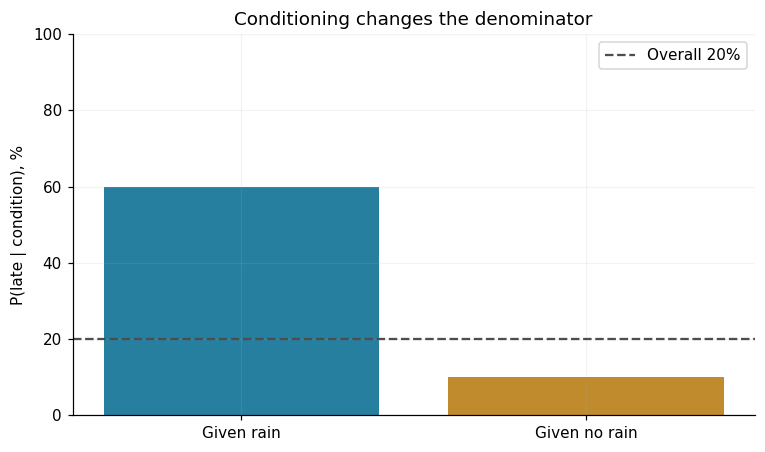

**تفسیر خروجی اجرای حاضر:** تأخیر مشروط به باران=60%، بدون باران=10%؛ چون با هم برابر نیستند، تأخیر و باران در این جدول مستقل نیستند.

In [3]:
rng=np.random.default_rng(202602)
table=np.array([[12,8],[8,72]])
conditional=table[:,0]/table.sum(axis=1)
display(pd.DataFrame(table,index=['Rain','No rain'],columns=['Late','On time']))
fig,ax=plt.subplots(); ax.bar(['Given rain','Given no rain'],100*conditional,color=[BLUE,GOLD]); ax.axhline(20,color='0.3',ls='--',label='Overall 20%'); ax.set(ylabel='P(late | condition), %',ylim=(0,100),title='Conditioning changes the denominator'); ax.legend(); show()
say(f'تأخیر مشروط به باران={conditional[0]:.0%}، بدون باران={conditional[1]:.0%}؛ چون با هم برابر نیستند، تأخیر و باران در این جدول مستقل نیستند.')

#### راهنمای خواندن نمودار و نتیجه

دو ستونِ شرطی هر کدام بر تعداد روزهای همان وضعیت تقسیم شده‌اند. اگر جدول شمارش را به نرخ تبدیل می‌کنید، جمع هر سطر باید با تعریف آن سازگار باشد. اختلاف ۶۰٪ و ۱۰٪ نشان‌دهندهٔ وابستگی در سناریوست، نه اندازهٔ اثر علّی باران؛ مسیرها و زمان ارسال هم می‌توانند تغییر کرده باشند.

#### دام رایج

جابه‌جاکردن P(A|B) و P(B|A)، یا شمردن موارد خالی به‌عنوان «خیر»، نتیجه را عوض می‌کند.

#### تمرین

اگر ۴۰ روز بارانی بود ولی همچنان ۱۲ تأخیر بارانی داشتیم، P(تأخیر|باران) چقدر می‌شد؟

#### پاسخ تشریحی

۱۲÷۴۰=۳۰٪. تعداد تأخیر ثابت مانده، ولی جامعهٔ شرطی و مخرج دو برابر شده است. احتمال جهت معکوس را باید با تعداد همهٔ تأخیرها جدا حساب کرد.

### درس 03. قضیهٔ بیز و تلهٔ نرخ پایه

**پرسش شروع:** هشدار یک سامانهٔ کشف تقلب با دقت حساسیت ۹۰٪؛ آیا هر هشدار تقریباً تقلب است؟

#### مفهوم، دقیق اما ساده

بیز احتمال پیشین را با اطلاعات تازه به‌روزرسانی می‌کند. حساسیت P(هشدار|تقلب) است، ولی چیزی که تصمیم‌گیر می‌خواهد P(تقلب|هشدار) است. برای رسیدن از اولی به دومی، نرخ پایه و هشدار اشتباه لازم‌اند. جدول تعدادهای طبیعی اغلب از فرمول قابل‌فهم‌تر است. اگر رویداد بسیار نادر باشد، حتی درصد کمی هشدار کاذب می‌تواند از هشدارهای درست بیشتر شود. این مسئله به معنی بی‌فایده‌بودن سامانه نیست؛ آستانهٔ اقدام و هزینهٔ بررسی باید متناسب انتخاب شود. نرخ پایه در جمعیت آموزش و استفاده ممکن است متفاوت باشد، پس یک precision را برای همهٔ بازارها کپی نکنید.

#### فرمول و قرارداد

```text
P(Fraud|Alert)=sensitivity×prevalence / [sensitivity×prevalence + false_positive_rate×(1−prevalence)]
```

#### مثال حل‌شده

در ۱۰٬۰۰۰ تراکنش با نرخ تقلب ۱٪، ۱۰۰ تقلب داریم. حساسیت ۹۰٪ یعنی ۹۰ هشدار درست. از ۹٬۹۰۰ تراکنش سالم، نرخ هشدار کاذب ۵٪ یعنی ۴۹۵ هشدار اشتباه. پس فقط ۹۰ از ۵۸۵ هشدار، حدود ۱۵٫۳۸٪، تقلب واقعی‌اند. این تعدادها انتظار مدل‌اند؛ در یک نمونهٔ تصادفی دقیقاً همین شمارش تضمین نمی‌شود. با نرخ پایهٔ ۱۰٪ و همان کیفیت آشکارساز، precision به حدود ۶۶٫۷٪ می‌رسد.

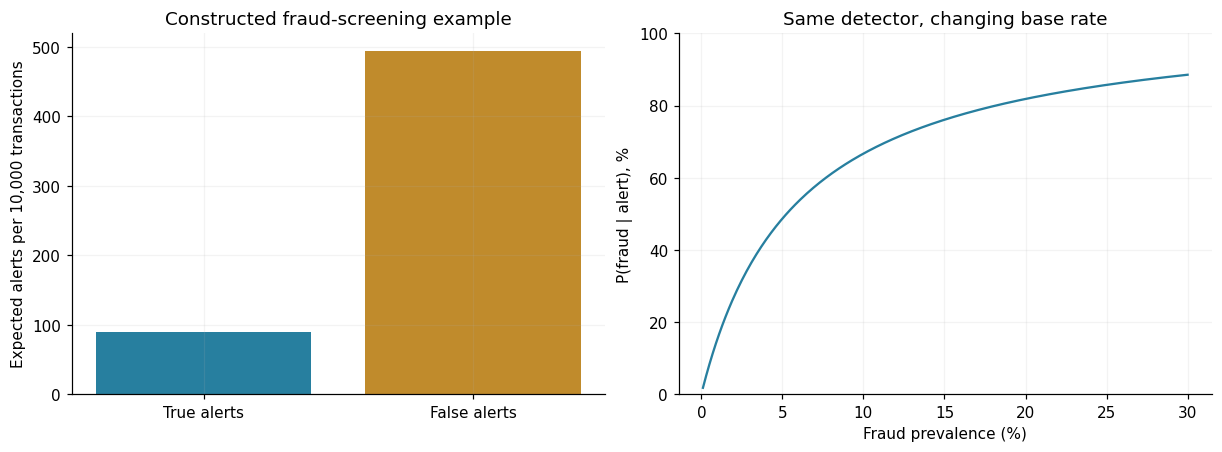

**تفسیر خروجی اجرای حاضر:** از 585 هشدارِ مورد انتظار، 90 درست‌اند؛ precision=15.38%. حساسیت ۹۰٪ به معنای درست‌بودن ۹۰٪ هشدارها نیست.

In [4]:
rng=np.random.default_rng(202603)
prev=.01; sensitivity=.9; fpr=.05; population=10000
tp=population*prev*sensitivity; fp=population*(1-prev)*fpr; ppv=tp/(tp+fp)
fig,axes=plt.subplots(1,2,figsize=(11,4),layout='constrained'); axes[0].bar(['True alerts','False alerts'],[tp,fp],color=[BLUE,GOLD]); axes[0].set(ylabel='Expected alerts per 10,000 transactions',title='Constructed fraud-screening example')
grid=np.linspace(.001,.3,300); axes[1].plot(100*grid,100*sensitivity*grid/(sensitivity*grid+fpr*(1-grid)),color=BLUE); axes[1].set(xlabel='Fraud prevalence (%)',ylabel='P(fraud | alert), %',ylim=(0,100),title='Same detector, changing base rate'); show()
say(f'از {tp+fp:.0f} هشدارِ مورد انتظار، {tp:.0f} درست‌اند؛ precision={ppv:.2%}. حساسیت ۹۰٪ به معنای درست‌بودن ۹۰٪ هشدارها نیست.')

#### راهنمای خواندن نمودار و نتیجه

دو بخش ستونِ هشدار را با هم بخوانید: بخش بزرگ هشدار اشتباه حاصل تعداد بسیار زیاد تراکنش سالم است. منحنی دوم نشان می‌دهد ثابت نگه‌داشتن حساسیت و نرخ خطای مثبت، precision را ثابت نگه نمی‌دارد. در این درس تصمیم اتهام‌زدن خودکار به فرد مطرح نیست؛ هشدار باید به بازبینی مناسب منتهی شود.

#### دام رایج

گزارش حساسیت به جای احتمال صحت هشدار، نرخ پایه را نادیده می‌گیرد. Accuracy هم در دادهٔ نادر می‌تواند فریبنده باشد.

#### تمرین

اگر همهٔ تراکنش‌ها را سالم اعلام کنیم، در نرخ تقلب ۱٪ دقت چند است؟ آیا سامانه خوب است؟

#### پاسخ تشریحی

دقت ۹۹٪ ولی حساسیت صفر است؛ هیچ تقلبی کشف نمی‌شود. معیار باید با هزینهٔ خطا، حجم بررسی و نرخ پایه سازگار باشد.

### درس 04. توزیع‌ها: برنولی، دوجمله‌ای، پواسون و نرمال

**پرسش شروع:** برای تعداد کلیک یک مدل می‌خواهیم؛ برای زمان پاسخ مدلی دیگر. چرا یک منحنی نرمال کافی نیست؟

#### مفهوم، دقیق اما ساده

توزیع، احتمال مقدارهای ممکن را مشخص می‌کند. برنولی یک موفقیت/شکست، دوجمله‌ای تعداد موفقیت در n تلاش مستقل با p ثابت، پواسون تعداد رخداد در یک بازه با ساختار نرخ مناسب و نرمال یک توزیع پیوستهٔ متقارن است. در مدل پواسون ساده میانگین و واریانس برابرند؛ در دوجمله‌ای واریانس np(1−p) است. برای متغیر پیوسته، احتمال یک نقطهٔ دقیق معمولاً صفر است و مساحت بازه معنا دارد؛ برای متغیر گسسته ارتفاع هر میله خود احتمال است. تابع توزیع تجمعی در هر دو حالت احتمال کمتر یا مساوی آستانه را می‌دهد. مدل را به دامنه و فرایند تولید داده وصل کنید؛ شباهت ظاهری یک هیستوگرام به‌تنهایی کافی نیست.

#### فرمول و قرارداد

```text
Bernoulli: E[X]=p, Var[X]=p(1−p)
Binomial: E[X]=np, Var[X]=np(1−p)
Poisson: E[X]=Var[X]=λ
```

#### مثال حل‌شده

در ۱۰ نمایش مستقل با احتمال کلیک ۲۰٪، تعداد کلیک دوجمله‌ای با میانگین ۲ و واریانس ۱٫۶ است. در مدل پواسون با λ=۲، میانگین همان ۲ ولی واریانس ۲ است و برخلاف دوجمله‌ای سقف ۱۰ ندارد. برای ساعت‌های شلوغ و خلوتِ مخلوط، یک پواسون با نرخ ثابت معمولاً توصیف کاملی نیست. مثال نرمالِ وزن قطعه هم مقدارهای منفی را از نظر ریاضی مجاز می‌داند؛ اگر آن احتمال مهم باشد باید مدل دیگری بررسی کرد.

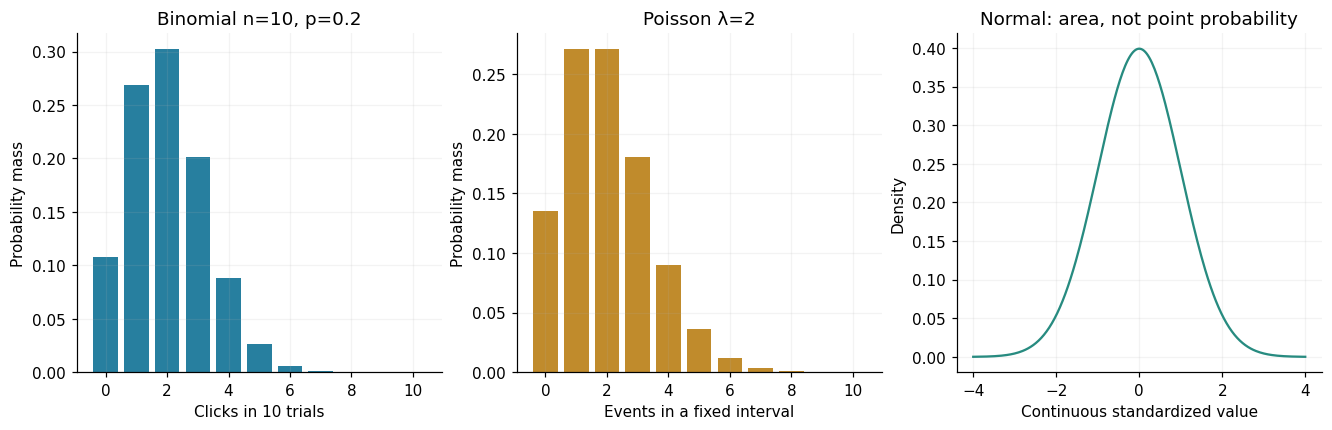

**تفسیر خروجی اجرای حاضر:** دوجمله‌ای: میانگین=۲، واریانس=۱٫۶ و احتمال حداقل یک کلیک=89.26%. پواسون با میانگین ۲ واریانس ۲ دارد؛ برابر بودن میانگین‌ها به معنی برابر بودن توزیع‌ها نیست.

In [5]:
rng=np.random.default_rng(202604)
k=np.arange(0,11); binprob=stats.binom.pmf(k,10,.2); poisprob=stats.poisson.pmf(k,2)
fig,axes=plt.subplots(1,3,figsize=(12,3.8),layout='constrained'); axes[0].bar(k,binprob,color=BLUE); axes[1].bar(k,poisprob,color=GOLD)
axes[0].set(xlabel='Clicks in 10 trials',ylabel='Probability mass',title='Binomial n=10, p=0.2'); axes[1].set(xlabel='Events in a fixed interval',ylabel='Probability mass',title='Poisson λ=2')
g=np.linspace(-4,4,250); axes[2].plot(g,stats.norm.pdf(g),color=TEAL); axes[2].set(xlabel='Continuous standardized value',ylabel='Density',title='Normal: area, not point probability'); show()
say(f'دوجمله‌ای: میانگین=۲، واریانس=۱٫۶ و احتمال حداقل یک کلیک={1-stats.binom.pmf(0,10,.2):.2%}. پواسون با میانگین ۲ واریانس ۲ دارد؛ برابر بودن میانگین‌ها به معنی برابر بودن توزیع‌ها نیست.')

#### راهنمای خواندن نمودار و نتیجه

محور عمودی دو پنل اول احتمال جرم و در پنل نرمال چگالی است؛ ارتفاع‌ها را میان این نوع‌ها یکسان تفسیر نکنید. احتمال حداقل یک کلیک از ۱−P(X=0) محاسبه می‌شود. مجموع احتمالات دوجمله‌ای دقیقاً یک است؛ نمایش محدود پواسون ممکن است بخش بسیار کوچکی از انتها را بیرون محور بگذارد.

#### دام رایج

قرار دادن توزیع نرمال روی هر داده، محدودیت شمارش، صفرها، چولگی و کران‌ها را نادیده می‌گیرد.

#### تمرین

اگر نتیجهٔ تلاش‌ها مستقل نباشد، آیا فرمول واریانس np(1−p) همچنان کافی است؟

#### پاسخ تشریحی

نه لزوماً؛ کوواریانس تلاش‌ها هم وارد واریانس مجموع می‌شود. خوشه‌بندی رفتار کاربران می‌تواند پراکندگی تعداد کلیک‌ها را بیشتر کند.

## فصل ۲ · نمونه‌گیری و عدم‌قطعیت

### درس 05. قانون اعداد بزرگ و قضیهٔ حد مرکزی

**پرسش شروع:** داده‌ها بسیار چوله‌اند؛ پس چگونه میانگین آن‌ها می‌تواند تقریباً نرمال شود؟

#### مفهوم، دقیق اما ساده

قانون اعداد بزرگ دربارهٔ نزدیک‌شدن میانگین نمونه به امیدریاضی در شرایط مناسب است؛ قضیهٔ حد مرکزی دربارهٔ شکل توزیع میانگین‌های استانداردشده در تکرار نمونه‌گیری است. هیچ‌کدام نمی‌گویند با زیادشدن n، خود داده‌های افراد نرمال می‌شوند. در نسخهٔ کلاسیکِ مستقل و هم‌توزیع با واریانس متناهی، SD میانگین برابر σ/√n است. برای وابستگی زمانی، دنباله‌های بسیار سنگین یا نمونه‌گیری سوگیرانه، این نتیجهٔ ساده را مستقیم به کار نبرید. عدد ۳۰ مرز جادویی نیست؛ شکل توزیع، انتهاها و هدف تقریب مهم‌اند. شبیه‌سازی با یک توزیع معلوم کمک می‌کند سطح «افراد» و «میانگینِ نمونه‌ها» را جدا ببینیم.

#### فرمول و قرارداد

```text
SE(mean)=σ/√n under i.i.d. finite variance
CLT standardizes the mean, not each observation.
```

#### مثال حل‌شده

زمان انتظار را از نمایی با میانگین و SD برابر ۲ واحد بسازید. انتظار فرد بسیار راست‌چوله است. اکنون ۴٬۰۰۰ بار نمونه‌های ۱، ۵، ۳۰ و ۱۰۰تایی بگیرید. میانگین‌های نمونهٔ بزرگ‌تر نزدیک ۲ جمع می‌شوند و شکلشان متقارن‌تر می‌شود؛ اما انتظارهای تکی هنوز همان توزیع چوله را دارند. دو برابرکردن دقت یعنی نصف‌کردن SE، تقریباً چهار برابر حجم نمونه می‌خواهد، نه دو برابر.

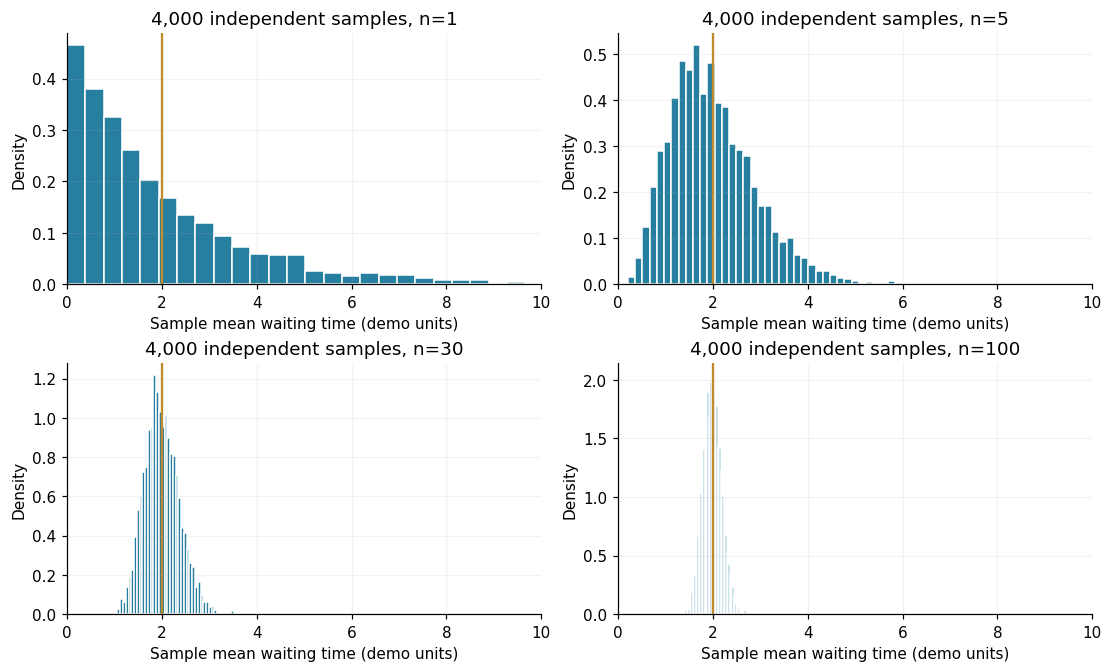

,n,mean of means,simulation SE,theoretical SE
0,1,1.959707,1.999275,2.000000
1,5,1.998917,0.887787,0.894427
2,30,1.999036,0.372476,0.365148
3,100,1.996431,0.201369,0.200000


**تفسیر خروجی اجرای حاضر:** هر پنل توزیع ۴٬۰۰۰ میانگین است، نه توزیع یک نمونهٔ فردی. کاهش SD میانگین‌ها با ۱/√n سازگار است؛ نرمال‌شدن تقریبیِ میانگین، چولگی زمان انتظار افراد را حذف نکرده است.

In [6]:
rng=np.random.default_rng(202605)
fig,axes=plt.subplots(2,2,figsize=(10,6),layout='constrained'); rows=[]
for ax,n in zip(axes.flat,[1,5,30,100]):
    means=rng.exponential(2,size=(4000,n)).mean(axis=1); rows.append([n,means.mean(),means.std(ddof=1),2/np.sqrt(n)])
    ax.hist(means,bins=45,density=True,color=BLUE,edgecolor='white'); ax.axvline(2,color=GOLD); ax.set(xlim=(0,10),xlabel='Sample mean waiting time (demo units)',ylabel='Density',title=f'4,000 independent samples, n={n}')
show(); display(pd.DataFrame(rows,columns=['n','mean of means','simulation SE','theoretical SE']))
say('هر پنل توزیع ۴٬۰۰۰ میانگین است، نه توزیع یک نمونهٔ فردی. کاهش SD میانگین‌ها با ۱/√n سازگار است؛ نرمال‌شدن تقریبیِ میانگین، چولگی زمان انتظار افراد را حذف نکرده است.')

#### راهنمای خواندن نمودار و نتیجه

همهٔ پنل‌ها محور افقی مشترک دارند تا کاهش پراکندگی دیده شود. خط عمودی ۲ امیدریاضیِ سناریوی ساخته‌شده است، نه عددی که از دادهٔ واقعی کشف شده باشد. در خروجی SD میانگین‌های شبیه‌سازی را با ۲/√n مقایسه کنید؛ اختلاف کوچک حاصل شبیه‌سازی محدود است.

#### دام رایج

نمونهٔ بزرگ، سوگیری انتخاب را درمان نمی‌کند. میانگین هزاران داوطلبِ نامرتبط ممکن است با دقت بالا کمیتِ اشتباه را تخمین بزند.

#### تمرین

اگر n از ۲۵ به ۱۰۰ برسد، SE در شرایط همین مدل چه تغییری می‌کند؟

#### پاسخ تشریحی

σ/√۲۵=σ/۵ و σ/√۱۰۰=σ/۱۰؛ SE نصف می‌شود. این رابطه به فرض استقلال و واریانس متناهی وابسته است.

### درس 06. سوگیری نمونه‌گیری، انتخاب و وزن‌دهی

**پرسش شروع:** اگر نظرسنجی را فقط در انجمن حرفه‌ای گیمرها بگذاریم، آیا یک میلیون پاسخ مشکل را حل می‌کند؟

#### مفهوم، دقیق اما ساده

خطای تصادفی از نمونه‌ای به نمونهٔ دیگر عوض می‌شود؛ سوگیری یک انحراف نظام‌مند نسبت به کمیت هدف است. چارچوب نمونه‌گیری، عدم پاسخ، نمونهٔ در دسترس و بازماندگان می‌توانند ترکیب داده را تغییر دهند. وزن‌دهی پس‌طبقه‌ای وقتی مفید است که سهم طبقه‌ها در جامعه معلوم باشد، همهٔ طبقه‌های مهم پوشش داشته باشند و پاسخ‌دهندگان درون طبقه‌ها برای کمیت موردنظر مناسب باشند. وزن‌دهی جادو نیست: ویژگیِ مشاهده‌نشده یا گروهی با احتمال انتخاب صفر را از هیچ نمی‌سازد. وزن‌های بسیار بزرگ هم واریانس را بالا می‌برند. باید هم برآورد وزنی و هم محدودیتِ فرایند انتخاب را گزارش کرد.

#### فرمول و قرارداد

```text
Post-stratified mean = Σ population_share[g] × sample_mean[g]
Large n reduces noise, not necessarily selection bias.
```

#### مثال حل‌شده

فرض ساخته‌شده: ۸۰٪ جامعه کاربر عادی با میانگین راحتی ۶ و ۲۰٪ حرفه‌ای با میانگین ۹ هستند؛ میانگین هدف ۶٫۶ است. در نظرسنجی، سهم‌ها برعکس ۲۰٪ و ۸۰٪ شده‌اند و میانگین خام ۸٫۴ به دست می‌آید. اگر میانگین درون هر گروه نماینده باشد و سهم واقعی را بدانیم، وزن‌دهی به ۶٫۶ برمی‌گردد. اگر حرفه‌ای‌های ناراضی اصلاً پاسخ نداده باشند، دانستن سهم حرفه‌ای‌ها به‌تنهایی آن سوگیری درون‌گروهی را رفع نمی‌کند.

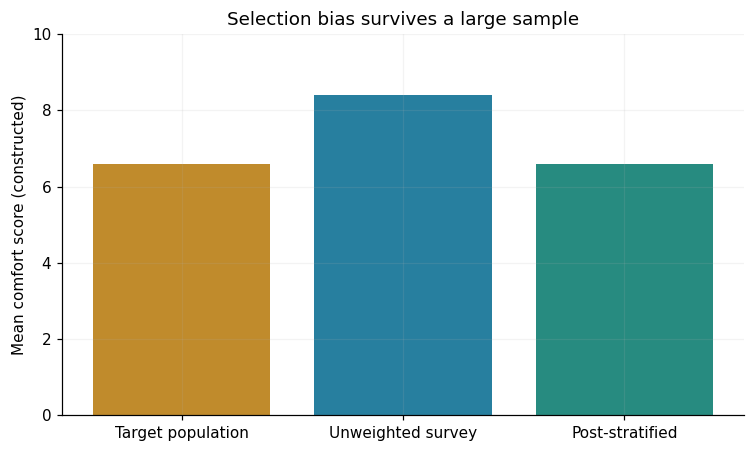

**تفسیر خروجی اجرای حاضر:** میانگین جامعهٔ ساختگی=6.6، نمونهٔ خام=8.4 و وزن‌دهی با فرض نمایندگی درون طبقه=6.6. نتیجهٔ آخر به فرض‌ها وابسته است؛ نمونهٔ بزرگ به‌خودی‌خود پاسخ را معتبر نمی‌کند.

In [7]:
rng=np.random.default_rng(202606)
population_share=np.array([.8,.2]); survey_share=np.array([.2,.8]); group_mean=np.array([6.,9.])
target=population_share@group_mean; raw=survey_share@group_mean; weighted=population_share@group_mean
fig,ax=plt.subplots(); ax.bar(['Target population','Unweighted survey','Post-stratified'],[target,raw,weighted],color=[GOLD,BLUE,TEAL]); ax.set(ylabel='Mean comfort score (constructed)',ylim=(0,10),title='Selection bias survives a large sample'); show()
say(f'میانگین جامعهٔ ساختگی={target:.1f}، نمونهٔ خام={raw:.1f} و وزن‌دهی با فرض نمایندگی درون طبقه={weighted:.1f}. نتیجهٔ آخر به فرض‌ها وابسته است؛ نمونهٔ بزرگ به‌خودی‌خود پاسخ را معتبر نمی‌کند.')

#### راهنمای خواندن نمودار و نتیجه

نمودار، سه برآورد از ترکیب‌های مختلفِ یک سناریوی معلوم است؛ اختلاف اعداد ناشی از تغییر ترکیب است. مقدار هدف را فقط در شبیه‌سازی می‌دانیم؛ در مطالعهٔ واقعی معمولاً باید جامعه و اطلاعات بیرونیِ وزن‌ها را مستند کنیم. فاصلهٔ میانگین خام از هدف با افزایش تکرار همین طرح انتخاب لزوماً کم نمی‌شود.

#### دام رایج

وزن‌های ساخته‌شده از خود پیامد یا اصلاح‌های انتخاب‌شده بعد از دیدن نتیجه، ممکن است سوگیری تازه بسازند.

#### تمرین

اگر هیچ کاربر چپ‌دست وارد نمونه نشده، آیا می‌توان با افزایش وزن راست‌دست‌ها دربارهٔ چپ‌دست‌ها نتیجه گرفت؟

#### پاسخ تشریحی

خیر. پوشش و مثبت‌بودن احتمال ورود لازم است. برای گروه غایب باید داده یا مدلِ انتقال‌پذیری با فرض روشن داشت؛ وزن‌دهی صرف اطلاعات مشاهده‌نشده را ایجاد نمی‌کند.

### درس 07. استقلال، اندازهٔ نمونهٔ مؤثر و شبه‌تکرار

**پرسش شروع:** ۱۰ نفر را هر کدام ۱۰۰ بار اندازه می‌گیریم؛ آیا ۱٬۰۰۰ نفر داده داریم؟

#### مفهوم، دقیق اما ساده

تعداد سطر با تعداد واحد مستقل فرق دارد. تکرارهای یک فرد معمولاً ویژگی مشترک دارند. اگر آن‌ها را مستقل فرض کنیم، SE بیش از حد کوچک و نتیجه بیش از حد مطمئن می‌شود؛ این شبه‌تکرار است. در طرح سادهٔ خوشه‌های هم‌اندازه با همبستگی درون‌خوشه‌ای ρ، اثر طرح تقریباً ۱+(m−۱)ρ و اندازهٔ نمونهٔ مؤثر برای میانگین کلی تقریباً n/اثرطرح است. این فرمول یک تقریب برای طرح و ساختار خاص است، نه قانون عمومی برای هر مدل. مدل چندسطحی، GEE، SE خوشه‌ای و بازنمونه‌گیری در سطح فرد از گزینه‌های متناسب‌اند؛ انتخاب به سؤال و تعداد خوشه‌ها هم بستگی دارد.

#### فرمول و قرارداد

```text
DEFF ≈ 1+(m−1)ρ; n_eff ≈ n/DEFF
Resample independent clusters, not repeated rows.
```

#### مثال حل‌شده

۲۰ فرد، هر کدام ۱۰ تکرار، در مجموع ۲۰۰ سطر داریم. اگر ρ=۰٫۶ باشد، اثر طرح ۶٫۴ و n مؤثرِ تقریبی ۳۱٫۲۵ می‌شود. این به معنی وجود ۳۱ فرد واقعی نیست؛ فقط دقت میانگینِ این طرح را با یک نمونهٔ مستقل مقایسه می‌کند. در شبیه‌سازی، اثر مشترک فرد و نویز تکرار جدا تولید می‌شوند. میانگین هر فرد را حساب کرده و SE میانگینِ ۲۰ میانگین فردی را با SE سادهٔ ۲۰۰ سطر مقایسه می‌کنیم.

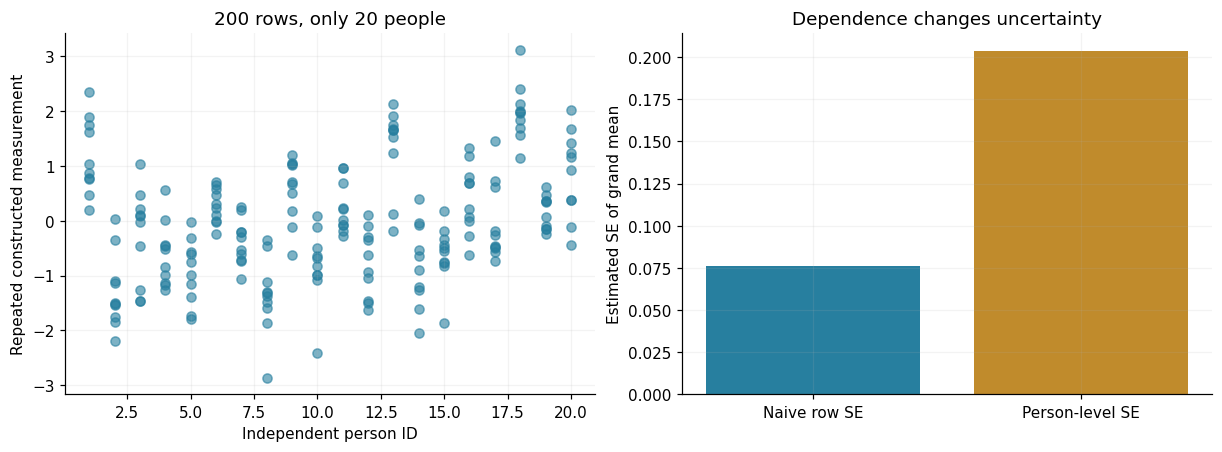

**تفسیر خروجی اجرای حاضر:** با ρ=0.6 و m=10، اثر طرح تقریبی=6.40 و n مؤثر≈31.25. در اجرای حاضر SE سطری=0.076 و SE بر مبنای فرد=0.204 است.

In [8]:
rng=np.random.default_rng(202607)
rho=.6; people=20; repeats=10
measure=rng.normal(0,np.sqrt(rho),size=(people,1))+rng.normal(0,np.sqrt(1-rho),size=(people,repeats))
naive=measure.std(ddof=1)/np.sqrt(measure.size); clustered=measure.mean(axis=1).std(ddof=1)/np.sqrt(people)
fig,axes=plt.subplots(1,2,figsize=(11,4),layout='constrained'); axes[0].scatter(np.repeat(np.arange(1,people+1),repeats),measure.ravel(),color=BLUE,alpha=.6); axes[0].set(xlabel='Independent person ID',ylabel='Repeated constructed measurement',title='200 rows, only 20 people')
axes[1].bar(['Naive row SE','Person-level SE'],[naive,clustered],color=[BLUE,GOLD]); axes[1].set(ylabel='Estimated SE of grand mean',title='Dependence changes uncertainty'); show()
say(f'با ρ={rho} و m={repeats}، اثر طرح تقریبی={1+(repeats-1)*rho:.2f} و n مؤثر≈{measure.size/(1+(repeats-1)*rho):.2f}. در اجرای حاضر SE سطری={naive:.3f} و SE بر مبنای فرد={clustered:.3f} است.')

#### راهنمای خواندن نمودار و نتیجه

نقاط ستون اول تکرارهای نزدیک یک شخص را نشان می‌دهند؛ تغییرات بین اشخاص مهم‌اند. پنل دوم SE ساده و SE در سطح افراد را مقایسه می‌کند، نه دو نوع پراکندگی دست. نمونهٔ محدود ممکن است دقیقاً نسبت نظری را نسازد. اگر اثر یادگیری یا زمان هم وجود داشته باشد، مدل تبادلیِ ساده کافی نیست.

#### دام رایج

دادن همان شخص به آموزش و آزمون، علاوه بر SE نادرست، ارزیابی مدل روی شخص جدید را خوش‌بینانه می‌کند.

#### تمرین

برای Bootstrap دادهٔ ۲۰ فرد با ۱۰ تکرار، کدام واحد را بازنمونه‌گیری می‌کنید؟

#### پاسخ تشریحی

برای تعمیم به افراد جدید، اشخاص را با همهٔ تکرارهایشان بازنمونه‌گیری می‌کنیم. اگر سؤال دربارهٔ تکرار در یک فرد مشخص باشد، طرح و واحد بازنمونه‌گیری باید دوباره تعریف شوند.

### درس 08. بازهٔ اطمینان، بازهٔ پیش‌بینی و پوشش در تکرار

**پرسش شروع:** «۹۵٪ اطمینان» یعنی ۹۵٪ داده‌ها داخل بازه‌اند یا ۹۵٪ احتمال برای میانگین؟

#### مفهوم، دقیق اما ساده

بازهٔ اطمینان فراوانی‌گرا یک روش تصادفیِ ساخت بازه است. اگر طرح و فرض‌ها درست باشند، در تکرارهای طولانی مثلاً ۹۵٪ بازه‌های ساخته‌شده پارامتر ثابت را می‌پوشانند. بعد از دیدن یک بازه، این تفسیر به معنای اختصاص احتمال بیزی ۹۵٪ به پارامتر نیست. بازهٔ پیش‌بینی برای مشاهدهٔ تازه است و پراکندگی افراد را هم در خود دارد؛ پس معمولاً از CI میانگین پهن‌تر است. یک بازهٔ جمعیتی هم موضوع دیگری است. وابستگی، انتخاب پس از نگاه به داده یا مدل نامناسب می‌تواند پوشش اسمی را خراب کند. سطح ۹۵٪ را از روش و فرض‌ها جدا گزارش نکنید.

#### فرمول و قرارداد

```text
Normal known σ: mean CI = x̄ ± 1.96σ/√n
New observation prediction interval = x̄ ± 1.96σ√(1+1/n)
```

#### مثال حل‌شده

در سناریوی معلوم μ=۱۰ و σ=۲، ۱۰۰ نمونهٔ مستقل ۲۵تایی می‌سازیم و برای هر کدام CI میانگین می‌کشیم. بعضی بازه‌ها ۱۰ را نمی‌پوشانند؛ این «اشتباه بودن آن نمونه» نیست، بلکه رفتار روش است. در اولین نمونه، بازهٔ پیش‌بینی یک مشاهدهٔ تازه حدود √۲۶ برابر CI میانگین پهنا دارد. برای σ نامعلوم باید از SE برآوردی و ضریب t متناسب استفاده کرد؛ این مثال عمداً σ را معلوم فرض می‌کند.

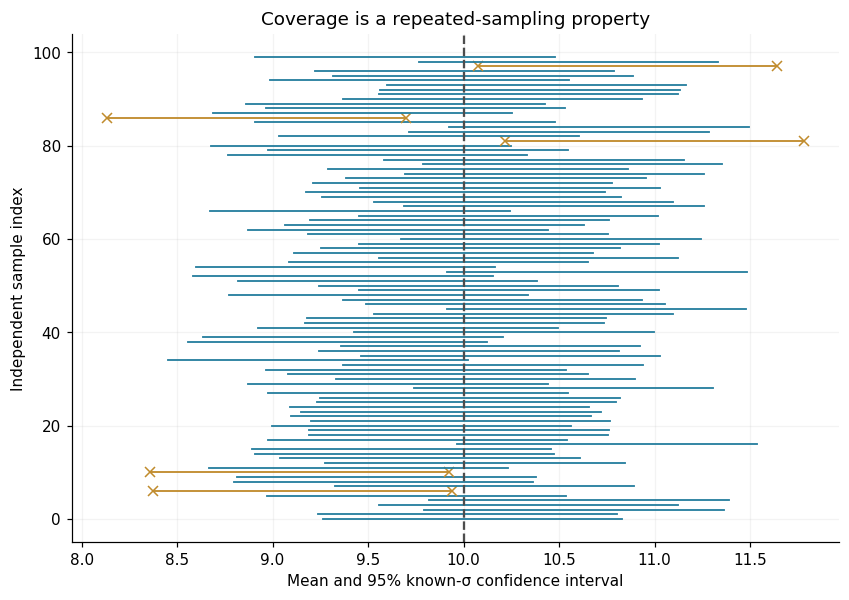

**تفسیر خروجی اجرای حاضر:** 95 از ۱۰۰ CI این اجرا μ=۱۰ را پوشاندند. نیم‌عرض CI=0.784 و نیم‌عرض پیش‌بینی فرد تازه=3.998 است؛ این دو دربارهٔ کمیت‌های متفاوت‌اند.

In [9]:
rng=np.random.default_rng(202608)
mu=10; sigma=2; n=25; samples=rng.normal(mu,sigma,size=(100,n)); means=samples.mean(axis=1); half=stats.norm.ppf(.975)*sigma/np.sqrt(n); covered=np.abs(means-mu)<=half
fig,ax=plt.subplots(figsize=(9,6))
for i,(m,hit) in enumerate(zip(means,covered)): ax.plot([m-half,m+half],[i,i],color=BLUE if hit else GOLD,lw=1.2,marker=None if hit else 'x')
ax.axvline(mu,color='0.3',ls='--'); ax.set(xlabel='Mean and 95% known-σ confidence interval',ylabel='Independent sample index',title='Coverage is a repeated-sampling property'); show()
prediction_half=stats.norm.ppf(.975)*sigma*np.sqrt(1+1/n)
say(f'{covered.sum()} از ۱۰۰ CI این اجرا μ=۱۰ را پوشاندند. نیم‌عرض CI={half:.3f} و نیم‌عرض پیش‌بینی فرد تازه={prediction_half:.3f} است؛ این دو دربارهٔ کمیت‌های متفاوت‌اند.')

#### راهنمای خواندن نمودار و نتیجه

هر خط افقی متعلق به یک نمونهٔ جداست؛ خط عمودی پارامتر واقعیِ شبیه‌سازی است. رنگ و علامت متفاوت، بازه‌های ناپوشاننده را مشخص می‌کنند. نرخ پوششِ ۱۰۰ بار ممکن است دقیقاً ۹۵٪ نباشد؛ خود این نرخ نیز نوسان دارد. پوشش هر زیرگروه یا پس از انتخاب مدل، خودکار از پوشش اسمی نتیجه نمی‌شود.

#### دام رایج

CI میانگین را به‌جای دامنهٔ قابل‌قبول افراد یا تضمین پیش‌بینی یک کاربر به کار نبرید.

#### تمرین

اگر n چهار برابر شود، CI میانگین و بازهٔ پیش‌بینی هر دو نصف می‌شوند؟

#### پاسخ تشریحی

CI میانگین با σ معلوم نصف می‌شود؛ اما عرض پیش‌بینی به کف پراکندگی فردی σ نزدیک می‌شود و نصف‌شدن آن تضمین نیست.

## فصل ۳ · استنباط عمیق با مثال ساده

### درس 09. درست‌نمایی، برآورد بیشینه و تابع زیان

**پرسش شروع:** کدام مقدار احتمال کلیک، دادهٔ دیده‌شده را بهتر توضیح می‌دهد؟

#### مفهوم، دقیق اما ساده

احتمال، با پارامتر معلوم دربارهٔ دادهٔ ممکن حرف می‌زند؛ درست‌نمایی، دادهٔ دیده‌شده را ثابت می‌گیرد و پارامترهای پیشنهادی را مقایسه می‌کند. بیشینهٔ درست‌نمایی یا MLE مقدار پارامتر با بیشترین سازگاری در همان مدل است. درست‌نمایی به‌تنهایی توزیع احتمال پارامتر نیست و لازم نیست مساحتش بر محور پارامتر یک باشد. لگاریتم حاصل‌ضرب احتمالات را به جمع تبدیل می‌کند و برای محاسبه پایدارتر است. تابع زیان نیز فقط یک انتخاب مهندسی نیست: کمترین مربعات با فرض‌های خطای گاوسی مرتبط است و خطای مطلق مرکز میانه‌ای را هدف می‌گیرد. مدل نادرست ممکن است با دقت بسیار خوب یک پارامتر نامناسب را برآورد کند.

#### فرمول و قرارداد

```text
L(p|k,n) ∝ p^k(1−p)^(n−k); p_MLE=k/n
Negative log-likelihood is a loss to minimize.
```

#### مثال حل‌شده

از ۲۰ تلاش، ۱۴ کلیک دیده‌ایم؛ MLE دوجمله‌ای ۰٫۷ است. حالا ۱۴۰ کلیک از ۲۰۰ تلاش را با همان نسبت تصور کنید. قله در هر دو ۰٫۷ است ولی منحنی درست‌نمایی نسبیِ نمونهٔ بزرگ‌تر باریک‌تر می‌شود. یک مثال دیگر: برای داده‌های ۱،۲،۳،۲۰، میانگین ۶٫۵ کمترین مربعات و هر عددی بین ۲ و۳ کمترین مجموع فاصلهٔ مطلق را می‌دهد؛ انتخاب زیان، هدف بهینه‌سازی را تغییر می‌دهد.

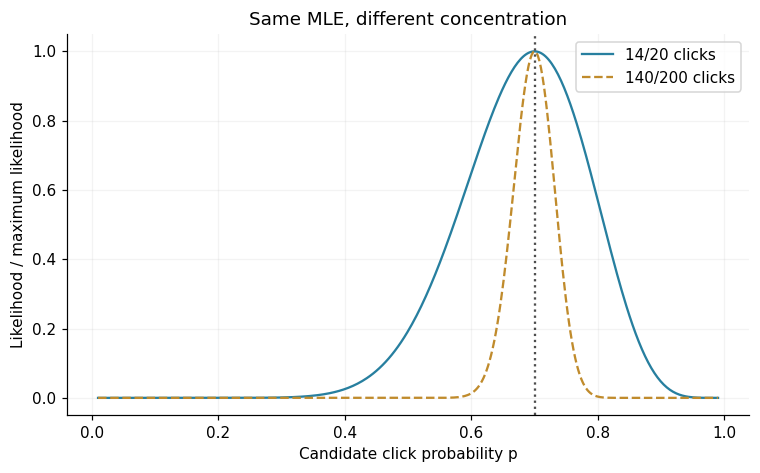

**تفسیر خروجی اجرای حاضر:** هر دو نمونه MLE=۰٫۷ دارند؛ منحنیِ ۲۰۰ تلاش باریک‌تر است. ارتفاع نسبیِ یک را نباید احتمال یک‌بودن برآورد یا posterior قطعی تعبیر کرد.

In [10]:
rng=np.random.default_rng(202609)
pgrid=np.linspace(.01,.99,400); fig,ax=plt.subplots()
for k,n,style in [(14,20,'-'),(140,200,'--')]:
    ll=stats.binom.logpmf(k,n,pgrid); ax.plot(pgrid,np.exp(ll-ll.max()),ls=style,label=f'{k}/{n} clicks')
ax.axvline(.7,color='0.3',ls=':'); ax.set(xlabel='Candidate click probability p',ylabel='Likelihood / maximum likelihood',title='Same MLE, different concentration'); ax.legend(); show()
say('هر دو نمونه MLE=۰٫۷ دارند؛ منحنیِ ۲۰۰ تلاش باریک‌تر است. ارتفاع نسبیِ یک را نباید احتمال یک‌بودن برآورد یا posterior قطعی تعبیر کرد.')

#### راهنمای خواندن نمودار و نتیجه

منحنی‌ها بر بیشینهٔ خود تقسیم شده‌اند تا قلهٔ هر دو یک باشد؛ این نرمال‌سازی، آن‌ها را posterior یا چگالی احتمال پارامتر نمی‌کند. عرض قله دربارهٔ حساسیت برازش به پارامتر سرنخ می‌دهد؛ برای CI باید روش و فرض مربوط جدا به کار رود. در مرزهای p=۰ یا۱، تقریب‌های معمول می‌توانند نامناسب باشند.

#### دام رایج

Likelihood را به‌عنوان P(پارامتر|داده) گزارش نکنید؛ برای posterior، پیشین و نرمال‌سازی بیزی لازم است.

#### تمرین

چرا با زیادشدن تعداد داده ولی ثابت‌ماندن نسبت کلیک، برآورد نقطه‌ای تغییر نمی‌کند اما عدم‌قطعیت کم می‌شود؟

#### پاسخ تشریحی

نسبت k/n همان است، ولی دادهٔ بیشتری دربارهٔ همان فرایند جمع شده است. انحنای لگاریتم درست‌نمایی بیشتر و دامنهٔ پارامترهای تقریباً هم‌ساز محدودتر می‌شود، با فرض صحت مدل و طرح نمونه‌گیری.

### درس 10. بیزِ عملی: پیشین، پسین و پیش‌بینی آینده

**پرسش شروع:** یک فروشگاه تازه از دو سفارش، دو موفقیت دارد؛ آیا نرخ موفقیتش حتماً ۱۰۰٪ است؟

#### مفهوم، دقیق اما ساده

در استنباط بیزی، عدم‌قطعیت پارامتر با توزیع پیشین توصیف و با درست‌نمایی به پسین تبدیل می‌شود. در مدل برنولی با پیشین Beta(a,b)، پس از s موفقیت و f شکست، پسین Beta(a+s,b+f) است. میانگین پسین، ترکیبی از میانگین پیشین و نسبت نمونه است. فاصلهٔ اعتباری بیزی با فرض همین مدل و پیشین، احتمال پسین مشخصی را در خود دارد؛ با تفسیر تکرار نمونه‌گیریِ CI یکی نیست. پیش‌بینی آینده علاوه بر پارامتر نامعلوم، تصادفی‌بودن مشاهدهٔ آینده را هم در نظر می‌گیرد. پیشین باید با دانش و حساسیت‌سنجی توجیه شود، نه برای رساندن نتیجه به پاسخ دلخواه.

#### فرمول و قرارداد

```text
Prior: p~Beta(a,b)
Posterior: p|data~Beta(a+s,b+f)
Predictive P(next success)=E[p|data]=(a+s)/(a+b+s+f)
```

#### مثال حل‌شده

با پیشین یکنواخت Beta(1,1) و دو موفقیت از دو تلاش، پسین Beta(3,1) و میانگین ۰٫۷۵ است، نه یک. با پیشین متمرکزتر Beta(10,10)، میانگین پسین ۱۲÷۲۲≈۰٫۵۴۵ می‌شود. این اختلاف بزرگ نشان می‌دهد دو مشاهده برای غلبه بر اطلاعات پیشین کافی نیست. برای ۱۴ موفقیت از۲۰ تلاش، پیشین یکنواخت به Beta(15,7) و میانگین حدود ۰٫۶۸۲ می‌رسد؛ با افزایش داده، سهم نسبی پیشین معمولاً کمتر می‌شود، مشروط به اینکه مدل مناسب باشد.

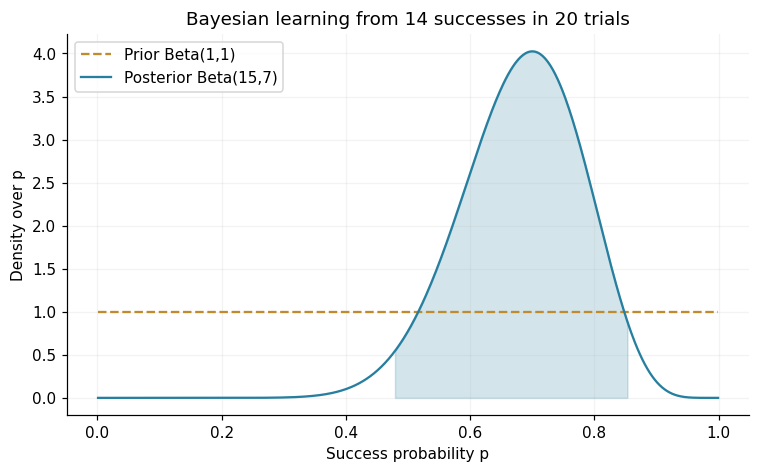

**تفسیر خروجی اجرای حاضر:** میانگین پسین و احتمال پیش‌بینی موفقیت بعدی=0.682؛ بازهٔ اعتباری صدکی ۹۵٪=[0.478,0.854]. این تفسیر به پیشین Beta(1,1) و مدل تلاش‌های مستقل با p ثابت مشروط است.

In [11]:
rng=np.random.default_rng(202610)
a,b=1,1; successes,failures=14,6; pa,pb=a+successes,b+failures; g=np.linspace(.001,.999,500); ci=stats.beta.ppf([.025,.975],pa,pb)
fig,ax=plt.subplots(); ax.plot(g,stats.beta.pdf(g,a,b),ls='--',color=GOLD,label='Prior Beta(1,1)'); ax.plot(g,stats.beta.pdf(g,pa,pb),color=BLUE,label='Posterior Beta(15,7)'); mask=(g>=ci[0])&(g<=ci[1]); ax.fill_between(g,0,stats.beta.pdf(g,pa,pb),where=mask,color=BLUE,alpha=.2); ax.set(xlabel='Success probability p',ylabel='Density over p',title='Bayesian learning from 14 successes in 20 trials'); ax.legend(); show()
say(f'میانگین پسین و احتمال پیش‌بینی موفقیت بعدی={pa/(pa+pb):.3f}؛ بازهٔ اعتباری صدکی ۹۵٪=[{ci[0]:.3f},{ci[1]:.3f}]. این تفسیر به پیشین Beta(1,1) و مدل تلاش‌های مستقل با p ثابت مشروط است.')

#### راهنمای خواندن نمودار و نتیجه

منحنی پیشین و پسین از نظر مساحت هر کدام یک‌اند؛ برخلاف درست‌نمایی نسبی درس قبل، این‌ها چگالی p هستند. بازهٔ سایه‌خورده صدکیِ ۹۵٪ پسین است. این بازه، دامنهٔ ۹۵٪ پیامدهای صفر و یک آینده نیست؛ دربارهٔ خود احتمال موفقیت است. احتمال موفقیت بعدی فقط یک عدد است، ولی تعداد موفقیت در چند تلاش آینده توزیع پیش‌بینی جدا دارد.

#### دام رایج

پیشین قوی را پنهان نکنید. «احتمال بیزی» فقط به اندازهٔ داده، مدل و پیشین قابل دفاع است.

#### تمرین

چرا مشاهدهٔ دو موفقیت، احتمال شکست آینده را صفر نمی‌کند؟

#### پاسخ تشریحی

دادهٔ محدود همهٔ pهای کمتر از یک را ناممکن نکرده است. پسین هنوز عدم‌قطعیت دارد و احتمال پیش‌بینی با میانگین‌گیری روی این عدم‌قطعیت به دست می‌آید.

### درس 11. اندازهٔ اثر، اهمیت عملی و آزمون هم‌ارزی

**پرسش شروع:** دو رابط تفاوت معناداری ندارند؛ پس می‌توانیم بگوییم تجربه‌شان یکسان است؟

#### مفهوم، دقیق اما ساده

عدم ردِ اختلاف صفر، اثبات هم‌ارزی نیست. مطالعهٔ کم‌توان ممکن است اختلاف مهمی را تشخیص ندهد. برای هم‌ارزی، حاشیهٔ عملی Δ را پیش از دیدن نتیجه تعریف می‌کنیم و می‌پرسیم آیا اثر با اطمینان کافی داخل (−Δ,+Δ) قرار دارد. در TOST دو فرض یک‌طرفه دربارهٔ مرزهای بد بودن بررسی می‌شوند. با سطح هر آزمون ۰٫۰۵، معادلِ متناظر بر مبنای مدل t این است که CI دوطرفهٔ ۹۰٪ کاملاً در حاشیه باشد؛ CI نوددرصدی برای این تصمیم به معنی شل‌کردن خودسرانهٔ استاندارد نیست. اندازهٔ اثر استانداردشده برای مقایسهٔ مقیاس‌ها مفید است اما واحد عملی، هزینه و دامنهٔ اثر را جایگزین نمی‌کند.

#### فرمول و قرارداد

```text
Equivalence: −Δ < effect < +Δ
TOST α=.05 ↔ model-based 90% two-sided CI fully inside the equivalence margin.
```

#### مثال حل‌شده

هشت اختلافِ امتیاز راحتیِ «جدید منهای قدیم» برابر ۰٫۱،۰٫۲،۰،−۰٫۱،۰٫۱،۰٫۲،−۰٫۲،۰٫۱ بسازید. حاشیهٔ مهم را از پیش ±۰٫۵ امتیاز قرار می‌دهیم. میانگین، CI نوددرصدی، دو p یک‌طرفه و d_z زوجی محاسبه می‌شوند. اگر حاشیه ±۰٫۰۵ انتخاب شده بود، نتیجه می‌توانست متفاوت شود؛ حاشیه تصمیم طراحی است نه چیزی که از p استخراج شود. این مثال اندازه‌گیری تکراریِ هشت فرد مستقل با فرض مدل t برای اختلاف‌هاست.

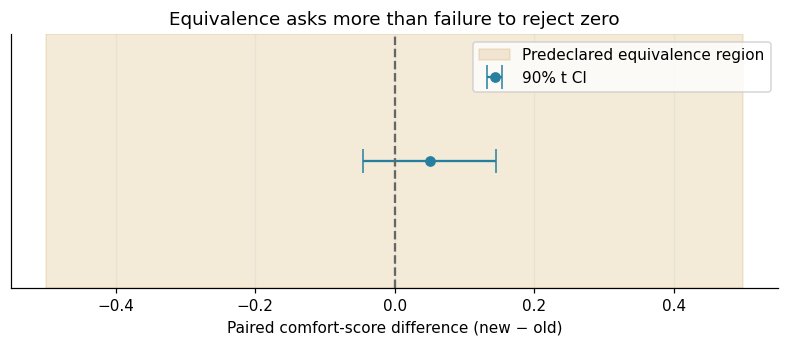

**تفسیر خروجی اجرای حاضر:** اثر میانگین=0.050، CI نوددرصدی=[-0.045,0.145]؛ pهای TOST=0.00001 و 0.00002. هم‌ارزی در Δ=۰٫۵؟ True. d_z=0.354 واحد استاندارد اختلاف‌هاست، نه امتیاز راحتی.

In [12]:
rng=np.random.default_rng(202611)
diff=np.array([.1,.2,0,-.1,.1,.2,-.2,.1]); margin=.5; avg=diff.mean(); se=stats.sem(diff); ci=stats.t.interval(.9,len(diff)-1,loc=avg,scale=se)
p_lower=stats.ttest_1samp(diff,-margin,alternative='greater').pvalue; p_upper=stats.ttest_1samp(diff,margin,alternative='less').pvalue
fig,ax=plt.subplots(figsize=(9,3)); ax.axvspan(-margin,margin,color=GOLD,alpha=.18,label='Predeclared equivalence region'); ax.errorbar(avg,0,xerr=[[avg-ci[0]],[ci[1]-avg]],fmt='o',color=BLUE,capsize=8,label='90% t CI'); ax.axvline(0,color='0.4',ls='--'); ax.set(yticks=[],xlabel='Paired comfort-score difference (new − old)',title='Equivalence asks more than failure to reject zero'); ax.legend(); show()
say(f'اثر میانگین={avg:.3f}، CI نوددرصدی=[{ci[0]:.3f},{ci[1]:.3f}]؛ pهای TOST={p_lower:.5f} و {p_upper:.5f}. هم‌ارزی در Δ=۰٫۵؟ {max(p_lower,p_upper)<.05}. d_z={avg/diff.std(ddof=1):.3f} واحد استاندارد اختلاف‌هاست، نه امتیاز راحتی.')

#### راهنمای خواندن نمودار و نتیجه

در نمودار، ناحیهٔ طلایی محدودهٔ هم‌ارزی عملی و خط آبی CI نوددرصدی اثر میانگین است. داخل‌بودن کل بازه، نه فقط نقطهٔ مرکزی، اهمیت دارد. اگر بازه از مرز بیرون برود و آزمون اختلاف هم رد نشود، نتیجه «نامطمئن» است؛ نه برابر و نه حتماً متفاوت. برای تحلیل واقعی، حاشیه را با کاربر و معیار عملکرد مستند کنید.

#### دام رایج

کوچک‌کردن حاشیه بعد از دیدن داده یا تبدیل p>۰٫۰۵ به «دو روش یکسان‌اند» نتیجهٔ معتبر نمی‌دهد.

#### تمرین

اگر CI از −۱ تا۱ و Δ=۰٫۵ باشد، آیا عدم معناداری، هم‌ارزی را تأیید می‌کند؟

#### پاسخ تشریحی

خیر؛ بازه اثرهای مهم خارج حاشیه را هم مجاز می‌داند. داده برای ادعای هم‌ارزی کافی نیست و افزایش اطلاعات یا بازبینی طرح لازم است.

### درس 12. چندآزمونی، Bonferroni و نرخ کشف کاذب

**پرسش شروع:** از میان هزار ویژگی، چند مورد p کوچک دارند؛ آیا کشف تازه‌ای کرده‌ایم؟

#### مفهوم، دقیق اما ساده

هر بار آزمون‌کردن فرصتی برای رد اشتباه می‌سازد. کنترل خطای خانواده‌ای یا FWER احتمال حداقل یک رد کاذب در کل خانواده را محدود می‌کند؛ Bonferroni با آستانهٔ α/m بدون نیاز به استقلال، محافظه‌کارانه این هدف را دنبال می‌کند. FDR به امیدِ نسبتِ کشف‌های کاذب به کل کشف‌ها مربوط است، با قرارداد صفر در نبود کشف. روش Benjamini–Hochberg با فرض استقلال یا برخی وابستگی‌های مثبت، FDR را کنترل می‌کند؛ برای وابستگی عمومی روش‌هایی مثل BY محافظه‌کارترند. FDR=۵٪ تضمین نمی‌کند در هر اجرای خاص دقیقاً ۵٪ یافته‌ها غلط‌اند، و هر p تعدیل‌شده احتمال نادرستی فرضیه نیست.

#### فرمول و قرارداد

```text
Bonferroni: reject p≤α/m
BH: sort p_(i); find largest k with p_(k)≤(k/m)q; reject ranks 1..k.
```

#### مثال حل‌شده

هشت p آموزشی برابر ۰٫۰۰۱،۰٫۰۱۲،۰٫۰۱۸،۰٫۰۴،۰٫۲،۰٫۳،۰٫۶ و۰٫۹ داریم. بدون اصلاح چهار مورد زیر۰٫۰۵ هستند. Bonferroni فقط اولی و BH با q=۰٫۰۵ سه مورد اول را نگه می‌دارد. این pها فهرست ساخته‌شده‌اند؛ چون حقیقت هر فرضیه را در این فهرست تعیین نکرده‌ایم، تعداد واقعی خطاهای کاذب را از روی آن‌ها نمی‌دانیم. برای هزار سنجهٔ اکتشافی، تعریف خانواده باید از سؤال تحلیل بیاید، نه بعد از دیدن اینکه کدام اصلاح مطلوب‌تر است.

,raw p,Bonferroni adjusted,BH adjusted,BH reject
0,0.001,0.008,0.008000,True
1,0.012,0.096,0.048000,True
2,0.018,0.144,0.048000,True
3,0.040,0.320,0.080000,False
4,0.200,1.000,0.320000,False
5,0.300,1.000,0.400000,False
6,0.600,1.000,0.685714,False
7,0.900,1.000,0.900000,False


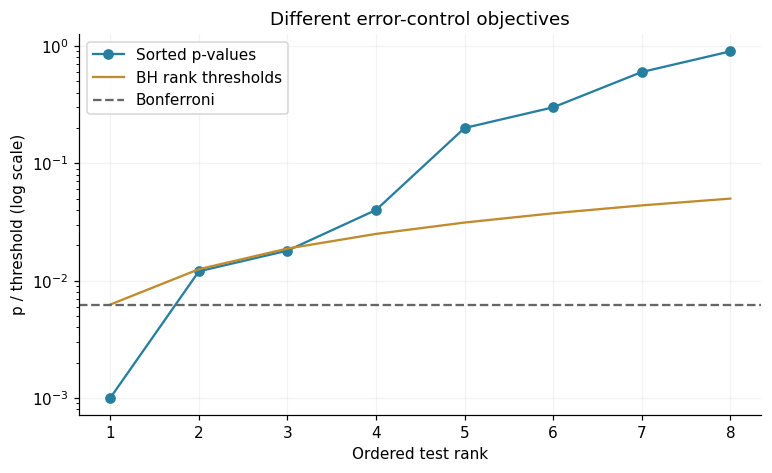

**تفسیر خروجی اجرای حاضر:** کشف خام=4، Bonferroni=1 و BH=3. بدون دانستن حقیقت فرضیه‌های این فهرستِ آموزشی، تعداد کشف کاذب مشاهده‌شده را نمی‌توان اعلام کرد.

In [13]:
rng=np.random.default_rng(202612)
from statsmodels.stats.multitest import multipletests
ps=np.array([.001,.012,.018,.04,.2,.3,.6,.9]); bonf=multipletests(ps,method='bonferroni'); bh=multipletests(ps,method='fdr_bh')
display(pd.DataFrame({'raw p':ps,'Bonferroni adjusted':bonf[1],'BH adjusted':bh[1],'BH reject':bh[0]}))
rank=np.arange(1,len(ps)+1); fig,ax=plt.subplots(); ax.plot(rank,ps,marker='o',color=BLUE,label='Sorted p-values'); ax.plot(rank,.05*rank/len(ps),color=GOLD,label='BH rank thresholds'); ax.axhline(.05/len(ps),color='0.4',ls='--',label='Bonferroni'); ax.set(xlabel='Ordered test rank',ylabel='p / threshold (log scale)',yscale='log',title='Different error-control objectives'); ax.legend(); show()
say(f'کشف خام={sum(ps<.05)}، Bonferroni={bonf[0].sum()} و BH={bh[0].sum()}. بدون دانستن حقیقت فرضیه‌های این فهرستِ آموزشی، تعداد کشف کاذب مشاهده‌شده را نمی‌توان اعلام کرد.')

#### راهنمای خواندن نمودار و نتیجه

در نمودار، نقاط pهای مرتب و خط BH آستانهٔ وابسته به رتبه است. فقط مقایسهٔ جداگانهٔ هر نقطه با خط کافی نیست؛ ابتدا بزرگ‌ترین رتبهٔ قابل‌قبول را بیابید و همهٔ رتبه‌های پیش از آن را در نظر بگیرید. جدول کنار شکل، p تعدیل‌شده و تصمیم هر روش را نشان می‌دهد. کشف آماری باید با اندازهٔ اثر، کیفیت داده و تکرار مستقل همراه شود.

#### دام رایج

فقط pهای معنادار را وارد اصلاح نکنید؛ این کار تعداد آزمون‌های واقعاً انجام‌شده را پنهان می‌کند.

#### تمرین

آیا با BH در q=۰٫۰۵ می‌توان گفت احتمال درست‌بودن هر یافته ۹۵٪ است؟

#### پاسخ تشریحی

خیر؛ این روش دربارهٔ نرخ مورد انتظارِ کشف‌های کاذب در یک فرایند تکرارشونده تحت فرض‌هاست، نه احتمال پسین یک فرضیهٔ مشخص.

## فصل ۴ · آزمایش و مدل‌سازی پیامد

### درس 13. آزمایش A/B، تصادفی‌سازی، زوج‌سازی و آزمون جایگشتی

**پرسش شروع:** هر شخص هر دو رابط را امتحان کرده؛ چرا دادهٔ زوجی را مثل دو جمعیت مستقل تحلیل نکنیم؟

#### مفهوم، دقیق اما ساده

تصادفی‌سازی کمک می‌کند تخصیص درمان یا طراحی، در انتظار با عوامل پیشین مستقل باشد؛ اما اجرای بد، ریزش متفاوت و سرایت اثر بین افراد همچنان خطرند. در طرح زوجی، اختلاف درون فرد اغلب بخشی از تنوع بین افراد را حذف می‌کند. ترتیب استفاده باید متوازن یا تصادفی شود تا اثر یادگیری با طراحی قاطی نشود. آزمون تصادفی‌سازی از سازوکار تخصیص استفاده می‌کند؛ آزمون جایگشتیِ برچسب‌های دلخواه بدون فرض تبادل‌پذیری همیشه معتبر نیست. برای زوج‌های تصادفی با فرض صفر تیز، تغییر علامت اختلاف هر زوج تخصیص ممکن دیگری را نشان می‌دهد. دادهٔ مشاهده‌ای صرف را با جابه‌جاکردن برچسب‌ها به آزمایش علّی تبدیل نمی‌کنیم.

#### فرمول و قرارداد

```text
Paired effect = mean(new_i−old_i)
Randomization null: compare observed statistic to allowed assignment statistics.
```

#### مثال حل‌شده

هشت اختلاف زمانی ۲،۱،۳،۲،۰،۱،−۱،۲ میلی‌ثانیه را برای «قدیم منهای جدید» بسازید؛ مثبت یعنی رابط جدید سریع‌تر است. تحت تخصیص زوجی تصادفی و فرض صفر مناسب، ۲^۸=۲۵۶ الگوی علامت ممکن را کامل می‌شماریم. p دوطرفه سهم الگوهایی است که قدر مطلق میانگینشان حداقل میانگین مشاهده‌شده است. چون همهٔ حالت‌ها شمرده شده‌اند، خطای شبیه‌سازی مونت‌کارلو نداریم؛ ولی انتخاب آماره و مفروضات طرح هنوز مهم‌اند.

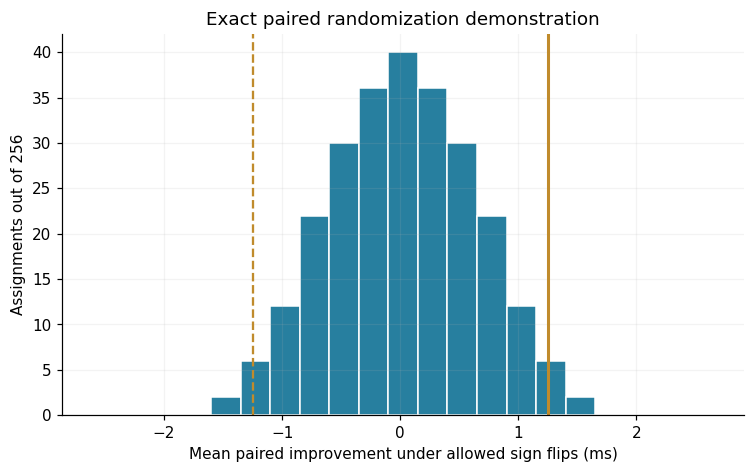

**تفسیر خروجی اجرای حاضر:** میانگین بهبود=1.250 میلی‌ثانیه و p دقیق دوطرفه=0.06250 در 256 حالت است. تفسیر آزمون به تصادفی‌سازی زوج‌ها/فرض صفر متناسب وابسته است؛ این داده‌ها ساخته‌شده‌اند.

In [14]:
rng=np.random.default_rng(202613)
from itertools import product
delta=np.array([2,1,3,2,0,1,-1,2],dtype=float); signs=np.array(list(product([-1,1],repeat=len(delta)))); null_stats=(signs*delta).mean(axis=1); obs=delta.mean(); exact_p=np.mean(np.abs(null_stats)>=abs(obs)-1e-12)
fig,ax=plt.subplots(); ax.hist(null_stats,bins=np.arange(-2.6,2.8,.25),color=BLUE,edgecolor='white'); ax.axvline(obs,color=GOLD,lw=2); ax.axvline(-obs,color=GOLD,ls='--'); ax.set(xlabel='Mean paired improvement under allowed sign flips (ms)',ylabel='Assignments out of 256',title='Exact paired randomization demonstration'); show()
say(f'میانگین بهبود={obs:.3f} میلی‌ثانیه و p دقیق دوطرفه={exact_p:.5f} در {len(signs)} حالت است. تفسیر آزمون به تصادفی‌سازی زوج‌ها/فرض صفر متناسب وابسته است؛ این داده‌ها ساخته‌شده‌اند.')

#### راهنمای خواندن نمودار و نتیجه

هیستوگرام، توزیع آماره تحت تخصیص‌های مجازِ فرض صفر است، نه توزیع اثر واقعی در جامعه. دو خط مرزهای ±قدر مطلق اثر مشاهده‌شده‌اند. ستون‌های بیرون این مرزها در صورت p شمرده می‌شوند. با n کم، p گسسته است؛ اضافه‌کردن رقم اعشار به معنای دقت علمی بیشتر نیست. در مطالعهٔ واقعی، CI و هزینهٔ عملی چند میلی‌ثانیه را هم گزارش کنید.

#### دام رایج

اگر یک شخص در هر دو گروه باشد، دو گروه مستقل نداریم. اگر همیشه طرح جدید دوم اجرا شود، اثر طراحی و یادگیری ممکن است تفکیک‌ناپذیر شوند.

#### تمرین

چرا ترتیب استفاده از دو رابط باید تصادفی یا متوازن باشد؟

#### پاسخ تشریحی

خستگی و تمرین می‌توانند در مرحلهٔ دوم نتیجه را عوض کنند. ترتیب متوازن این عامل را با طراحی یکی نمی‌کند و باید در طرح و تحلیل لحاظ شود.

### درس 14. نگاه‌کردن مکرر به p و توقف زودهنگام

**پرسش شروع:** آزمایش را هر روز نگاه می‌کنیم و اولین روز p<۰٫۰۵ شد متوقف می‌کنیم؛ چه چیزی خراب می‌شود؟

#### مفهوم، دقیق اما ساده

آزمون با حجم ثابت برای یک برنامهٔ نمونه‌گیری مشخص کالیبره شده است. اگر در هر نگاه فرصت تازه‌ای برای اعلام موفقیت داشته باشیم، خطای کل فرایند می‌تواند از پنج درصد بیشتر شود، حتی وقتی هر مقایسه ظاهراً با α=۰٫۰۵ انجام شده است. نگاه‌های تجمعی مستقل نیستند، پس فرمول ۱−۰٫۹۵^m را مستقیم برای آن‌ها به کار نمی‌بریم. در برنامهٔ از پیش مشخصِ m نگاه، Bonferroni یک اصلاح ساده و محافظه‌کارانه است؛ طراحی‌های گروه‌متوالی، تخصیص α و روش‌های always-valid ابزارهای دقیق‌ترند. قاعدهٔ توقف، معیار اصلی و تحلیل ریزش باید قبل از اجرای واقعی مشخص شوند.

#### فرمول و قرارداد

```text
Planned m looks: a conservative boundary is p≤α/m at each look.
Dependent cumulative looks do not satisfy 1−(1−α)^m.
```

#### مثال حل‌شده

در ۳٬۰۰۰ آزمایش ساختگی، هر دو گروه نرخ موفقیت واقعی ۰٫۵ دارند. از ۵۰ تا۱٬۰۰۰ نفر در هر گروه، هر۵۰ نفر یک بار z تقریبی اختلاف نرخ‌ها را نگاه می‌کنیم. سه قاعده را مقایسه می‌کنیم: فقط نگاه آخر، حداقل یکی از۲۰ نگاه با p<۰٫۰۵، و حداقل یکی با p<۰٫۰۰۲۵. این یک شبیه‌سازی آموزشی با آزمون نرمال تقریبی است؛ خطای نوع اولِ اصلاح‌شده نیز به معتبر بودن pهای هر نگاه وابسته است.

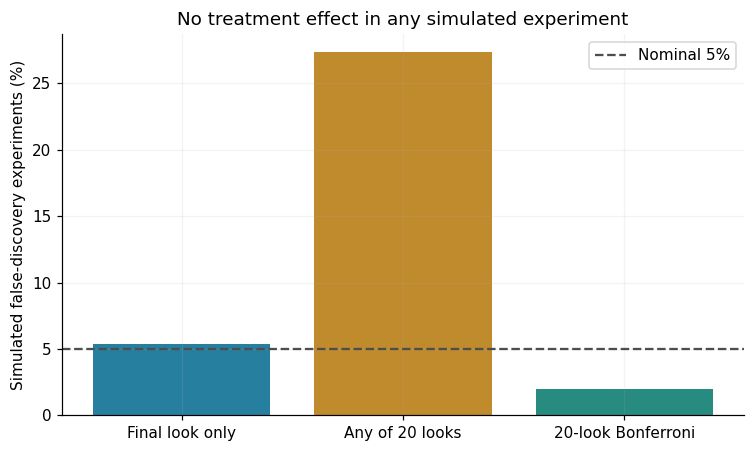

**تفسیر خروجی اجرای حاضر:** نرخ رد کاذب تجربی: فقط پایان=5.33%؛ نگاه مکرر خام=27.33%؛ اصلاح ۲۰نگاهی=2.00%. این برآورد از ۳٬۰۰۰ تکرارِ سناریوی بدون اثر است، نه نرخ قطعی هر آزمایش واقعی.

In [15]:
rng=np.random.default_rng(202614)
trials=3000; max_n=1000; looks=np.arange(50,max_n+1,50)
aa=rng.binomial(1,.5,size=(trials,max_n)).cumsum(axis=1)[:,looks-1]/looks
bb=rng.binomial(1,.5,size=(trials,max_n)).cumsum(axis=1)[:,looks-1]/looks
z=(bb-aa)/np.sqrt(.5/looks); pv=2*stats.norm.sf(np.abs(z))
false_rates=np.array([(pv[:,-1]<.05).mean(),(pv<.05).any(axis=1).mean(),(pv<.05/len(looks)).any(axis=1).mean()])
fig,ax=plt.subplots(); ax.bar(['Final look only','Any of 20 looks','20-look Bonferroni'],100*false_rates,color=[BLUE,GOLD,TEAL]); ax.axhline(5,color='0.3',ls='--',label='Nominal 5%'); ax.set(ylabel='Simulated false-discovery experiments (%)',title='No treatment effect in any simulated experiment'); ax.legend(); show()
say(f'نرخ رد کاذب تجربی: فقط پایان={false_rates[0]:.2%}؛ نگاه مکرر خام={false_rates[1]:.2%}؛ اصلاح ۲۰نگاهی={false_rates[2]:.2%}. این برآورد از ۳٬۰۰۰ تکرارِ سناریوی بدون اثر است، نه نرخ قطعی هر آزمایش واقعی.')

#### راهنمای خواندن نمودار و نتیجه

میله‌ها سهم آزمایش‌های بدون اثرند که اشتباهاً «کشف» اعلام کرده‌اند؛ این سهم توان نیست. قاعدهٔ نگاه مکرر معمولاً میلهٔ بلندتری دارد. اعداد دقیق با بذر و تعداد تکرار تغییر می‌کنند. Bonferroni برای آموزش هزینهٔ چندفرصتی است، نه پیشنهاد خودکار برای همهٔ پلتفرم‌های A/B؛ طراحی متوالی حرفه‌ای باید متناسب با هزینه و اطلاعات هر مرحله باشد.

#### دام رایج

توقف پس از نخستین p کوچک و گزارش همان p به‌عنوان آزمونِ ازپیش‌طراحی‌شده، فرایند انتخاب را پنهان می‌کند.

#### تمرین

آیا چون نگاه‌ها به دادهٔ تجمعی وابسته‌اند، دیگر خطای چندبار نگاه‌کردن وجود ندارد؟

#### پاسخ تشریحی

نه. وابستگی فقط مقدار تورم خطا را عوض می‌کند و فرمول استقلال را نامناسب می‌سازد؛ کالیبراسیونِ قاعدهٔ توقف همچنان لازم است.

### درس 15. رگرسیون لجستیک: احتمال، Odds و نسبت شانس

**پرسش شروع:** یک ساعت آموزش بیشتر، احتمال موفقیت را «دو برابر» می‌کند یا شانس موفقیت را؟

#### مفهوم، دقیق اما ساده

رگرسیون خطی برای پیامد صفر و یک ممکن است پیش‌بینی زیر صفر یا بالای یک بدهد. مدل لجستیک ترکیب خطی ویژگی‌ها را به log-odds پیوند می‌دهد و سپس آن را با تابع sigmoid به احتمال تبدیل می‌کند. Odds برابر p/(1−p) است؛ odds ratio با risk ratio یکی نیست. افزایش یک واحد X، با ثابت‌بودن بقیهٔ پیش‌بین‌ها، odds را در exp(β) ضرب می‌کند؛ تغییر احتمال به احتمال اولیه وابسته است. ضرایب مشاهده‌ای اثر علّی محسوب نمی‌شوند. نمونهٔ ناکافی، جدایی کامل کلاس‌ها و هم‌خطی می‌توانند برازش و عدم‌قطعیت را مشکل‌دار کنند؛ منظم‌سازی و طرح داده مهم‌اند.

#### فرمول و قرارداد

```text
log(p/(1−p))=β0+β1x
p=1/(1+exp(−η)); OR=exp(β1)
```

#### مثال حل‌شده

اگر p ابتدا ۰٫۲ باشد، odds برابر۰٫۲۵ است. دو برابرشدن odds آن را به۰٫۵ می‌رساند و احتمال تازه۰٫۳۳۳ می‌شود، نه۰٫۴. اگر p ابتدا۰٫۸ باشد، odds=۴ و odds تازه۸ است؛ احتمال۰٫۸۸۹ می‌شود. در شبیه‌سازی، ۵۰۰ مقدار ساعت تمرین و موفقیت ساخته و مدل GLM دوجمله‌ای برازش می‌کنیم؛ ضریب برآوردشده الزاماً دقیقاً ضریب سازنده نیست، چون داده تصادفی‌اند.

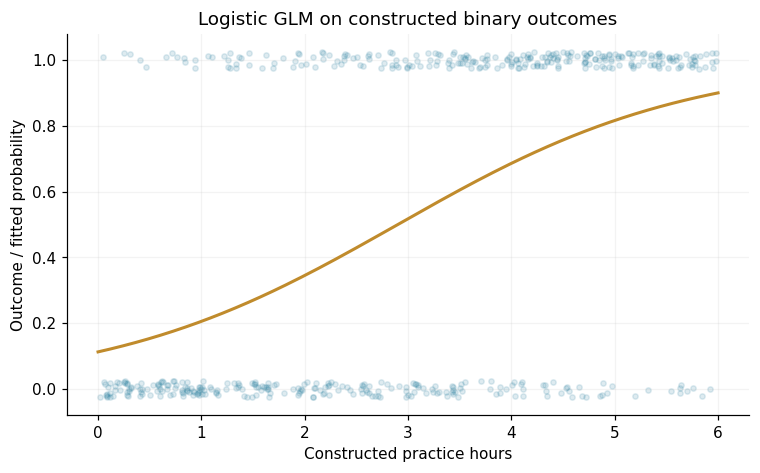

,coefficient,exp(coefficient)
Intercept,-2.063542,0.127003
Hours,0.711824,2.037704


**تفسیر خروجی اجرای حاضر:** ضریب ساعت=0.712 و OR=2.038 است؛ تغییر احتمال به مقدار آغازین وابسته است. برای OR=۲، احتمال ۰٫۲ به 0.333 می‌رسد، نه۰٫۴.

In [16]:
rng=np.random.default_rng(202615)
hours=rng.uniform(0,6,500); true_prob=1/(1+np.exp(-(-2+.7*hours))); outcome=rng.binomial(1,true_prob)
logit_fit=sm.GLM(outcome,sm.add_constant(hours),family=sm.families.Binomial()).fit()
grid=np.linspace(0,6,150); fitted_prob=logit_fit.predict(sm.add_constant(grid))
fig,ax=plt.subplots(); ax.scatter(hours,outcome+rng.uniform(-.025,.025,len(outcome)),alpha=.15,s=12,color=BLUE); ax.plot(grid,fitted_prob,color=GOLD,lw=2); ax.set(xlabel='Constructed practice hours',ylabel='Outcome / fitted probability',ylim=(-.08,1.08),title='Logistic GLM on constructed binary outcomes'); show()
display(pd.DataFrame({'coefficient':logit_fit.params,'exp(coefficient)':np.exp(logit_fit.params)},index=['Intercept','Hours']))
say(f'ضریب ساعت={logit_fit.params[1]:.3f} و OR={np.exp(logit_fit.params[1]):.3f} است؛ تغییر احتمال به مقدار آغازین وابسته است. برای OR=۲، احتمال ۰٫۲ به {(.2/.8*2)/(1+.2/.8*2):.3f} می‌رسد، نه۰٫۴.')

#### راهنمای خواندن نمودار و نتیجه

منحنی آبی احتمال برازش‌شده بین صفر ویک است. نقاطِ موفقیت و شکست کمی برای خوانایی در راستای عمودی جابه‌جا شده‌اند؛ این jitter پیامد جدیدی نساخته است. جدول ضریب و exp(ضریب) را با واحد ورودی بخوانید. برای کیفیت پیش‌بینیِ فرد تازه باید جداگانه از آموزش ارزیابی شود؛ این شکل برازش درون‌نمونه است.

#### دام رایج

عبارت «OR=۲ یعنی احتمال دو برابر» به‌خصوص برای پیامد رایج اشتباه است. همچنین ضریب با کنترل متغیر نامناسب می‌تواند سوگیر شود.

#### تمرین

با p=۰٫۵ و OR=۳، احتمال جدید چقدر است؟

#### پاسخ تشریحی

odds اولیه۱ و جدید۳ است؛ p=۳/(۱+۳)=۰٫۷۵. افزایش احتمال۲۵ واحد درصد و نسبت احتمال۱٫۵ است، نه۳.

### درس 16. پواسون، بیش‌پراکندگی و مدل شمارشی با Exposure

**پرسش شروع:** دو شعبه هر کدام ۱۰ شکایت دارند؛ یکی صد مشتری داشته و دیگری ده‌هزار مشتری.

#### مفهوم، دقیق اما ساده

شمارش را بدون اندازهٔ فرصت وقوع مقایسه نکنید. در مدل پواسون با exposure، لگاریتم فرصت مانند مدت یا تعداد مشتری می‌تواند offset با ضریب ثابت یک باشد؛ مدل، نرخ را با پاسخ شمارشی مرتبط می‌کند. مدل پواسون ساده واریانس شرطی برابر میانگین شرطی دارد. اگر واریانسِ شرطی خیلی بیشتر باشد، بیش‌پراکندگی ممکن است از ناهمگنی، وابستگی، صفر اضافی یا مدل میانگین نامناسب بیاید. توزیع نگاتیو بینوم با پارامتر پراکندگی یکی از راه‌هاست، نه تنها راه. برابری واریانس و میانگین در کل فایل جای بررسی شرطی بعد از کنترل ویژگی‌ها را نمی‌گیرد.

#### فرمول و قرارداد

```text
log(E[count|X,exposure])=Xβ+log(exposure)
Poisson Var(Y|X)=μ; NB2 Var(Y|X)=μ+αμ².
```

#### مثال حل‌شده

۱۰ شکایت در۱۰۰ مشتری نرخ۱۰٪ و در۱۰٬۰۰۰ مشتری نرخ۰٫۱٪ است؛ شمارش برابر، نرخ صدبرابر متفاوت دارد. در مثال کد، ۶۰۰ شمارش با میانگینِ وابسته به ساعات کار و exposure تصادفی از NB2 با α=۰٫۸ می‌سازیم. سپس پواسون و NB را برازش می‌کنیم. برای NB، α در این نمایش همان پارامترِ معلومِ سازنده است؛ آن را برآوردشده از داده جا نمی‌زنیم. در کار واقعی باید پراکندگی را با روش معتبر تخمین یا حساسیت‌سنجی کرد.

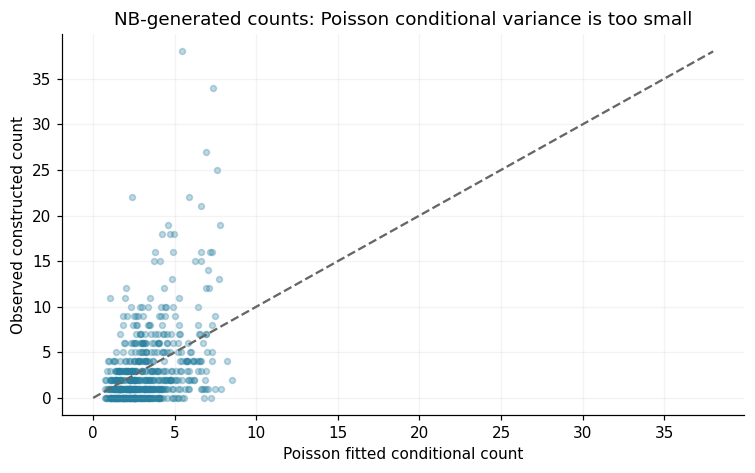

**تفسیر خروجی اجرای حاضر:** نسبت تشخیصی χ²/df پواسون=4.07 است. ضریب x در پواسون=0.394 و NB با α معلوم ۰٫۸ برابر 0.372 است؛ این سناریو دادهٔ واقعی شکایت نیست و ارزیابی پیش‌بینی مستقل انجام نشده است.

In [17]:
rng=np.random.default_rng(202616)
cx=rng.uniform(0,3,600); exposure=rng.uniform(.5,2,600); mu=exposure*np.exp(.3+.4*cx); alpha=.8
counts=rng.negative_binomial(1/alpha,(1/alpha)/(1/alpha+mu)); design_x=sm.add_constant(cx)
poisson=sm.GLM(counts,design_x,family=sm.families.Poisson(),offset=np.log(exposure)).fit()
nb_demo=sm.GLM(counts,design_x,family=sm.families.NegativeBinomial(alpha=alpha),offset=np.log(exposure)).fit()
dispersion=poisson.pearson_chi2/poisson.df_resid
fig,ax=plt.subplots(); ax.scatter(poisson.fittedvalues,counts,color=BLUE,alpha=.3,s=15); lim=max(counts.max(),poisson.fittedvalues.max()); ax.plot([0,lim],[0,lim],color='0.4',ls='--'); ax.set(xlabel='Poisson fitted conditional count',ylabel='Observed constructed count',title='NB-generated counts: Poisson conditional variance is too small'); show()
say(f'نسبت تشخیصی χ²/df پواسون={dispersion:.2f} است. ضریب x در پواسون={poisson.params[1]:.3f} و NB با α معلوم ۰٫۸ برابر {nb_demo.params[1]:.3f} است؛ این سناریو دادهٔ واقعی شکایت نیست و ارزیابی پیش‌بینی مستقل انجام نشده است.')

#### راهنمای خواندن نمودار و نتیجه

در ابر نقاط، محور افقی میانگین شرطیِ پیش‌بینی‌شدهٔ پواسون و عمودی شمارش دیده‌شده است؛ پراکندگی زیاد اطراف خط y=x با توضیح بیش‌پراکندگی سازگار است. نسبت Pearson χ²/df فقط یک تشخیص تقریبی با مدل و حجم نمونهٔ مناسب است. مقدار بزرگ هشدار است، ولی علت نهایی مشکل را تعیین نمی‌کند.

#### دام رایج

افزودن offset اشتباه، مانند مدتِ حاصل از خود پیامد، می‌تواند سوگیری بسازد. زیادبودن صفرها هم به‌تنهایی اثبات یک مدل zero-inflated نیست.

#### تمرین

اگر exposure دو برابر و نرخ ثابت باشد، شمارش مورد انتظار چه می‌شود؟

#### پاسخ تشریحی

دو برابر می‌شود؛ offset لگاریتم exposure این تناسب را به مدل تحمیل می‌کند. اگر تناسب در واقعیت درست نباشد، باید مدل فرصت و ساختار سؤال بازبینی شود.

## فصل ۵ · علیت و دادهٔ ناقص

### درس 17. پارادوکس سیمپسون: وقتی جمع‌بندی جهت را برمی‌گرداند

**پرسش شروع:** روش B در کارهای آسان و سخت بهتر است، اما در کل بدتر دیده می‌شود. تناقض کجاست؟

#### مفهوم، دقیق اما ساده

نرخ کل میانگین وزنی نرخ‌های زیرگروه است؛ اگر وزن زیرگروه‌ها بین دو روش متفاوت باشد، رابطهٔ تجمیعی ممکن است جهت متفاوتی از رابطهٔ درون گروه‌ها داشته باشد. این پدیده تناقض حساب نیست؛ مخرج‌های متفاوت را مخلوط کرده‌ایم. اگر سختی کار هم بر انتخاب روش و هم بر موفقیت اثر بگذارد، یک مخدوش‌کنندهٔ محتمل است. اما «همیشه زیرگروه‌بندی کن» راه‌حل عمومی نیست؛ اگر متغیر انتخابی collider یا پیامدِ درمان باشد، شرطی‌کردن می‌تواند سوگیری ایجاد کند. برای تصمیم علّی، ساختار زمانی و فرض دربارهٔ روابط لازم است. برای توصیف نیز باید وزن‌های جامعهٔ هدف را روشن کرد.

#### فرمول و قرارداد

```text
Rate(A)=Σ P(group|A)×Rate(A,group)
Standardized rate uses the same declared group weights for both methods.
```

#### مثال حل‌شده

در کار آسان A برابر۸۱/۹۰=۹۰٪ و B برابر۱۹/۲۰=۹۵٪ موفق است. در کار سخت A برابر۱/۱۰=۱۰٪ و B برابر۱۶/۸۰=۲۰٪ است. با وجود برتری B در هر دو، کل A برابر۸۲٪ و کل B برابر۳۵٪ می‌شود، چون بیشتر کارهای B سخت‌اند. با وزن هدفِ برابرِ آسان/سخت، A=۵۰٪ و B=۵۷٫۵٪ است. این وزن۵۰/۵۰ صرفاً هدف فرضی ماست، نه ترکیب واقعی هر بازار.

,method,easy success,easy n,hard success,hard n,pooled rate,50:50 standardized
0,A,81,90,1,10,0.82,0.500
1,B,19,20,16,80,0.35,0.575


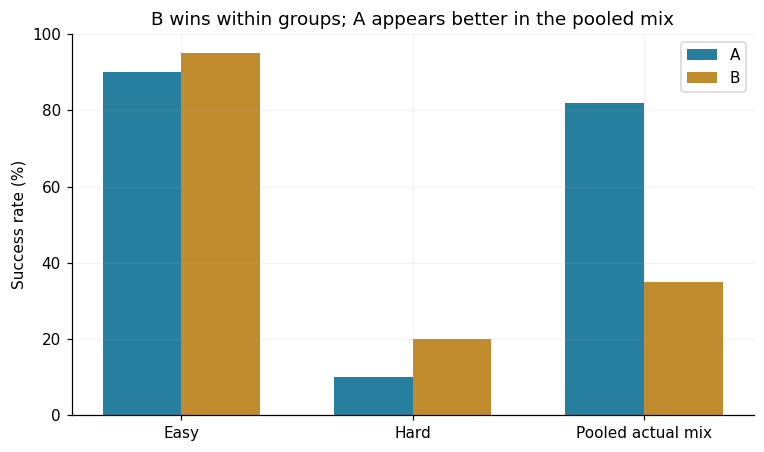

**تفسیر خروجی اجرای حاضر:** تجمیع خام: A=82% و B=35%. با وزن مشترک ۵۰/۵۰: A=50.0% و B=57.5%. تغییر جهت از وزن‌های متفاوت می‌آید؛ اثر علّی بدون طرح و فرض تعیین نمی‌شود.

In [18]:
rng=np.random.default_rng(202617)
success=np.array([[81,1],[19,16]]); trials=np.array([[90,10],[20,80]]); group_rates=success/trials; overall=success.sum(axis=1)/trials.sum(axis=1); standard=group_rates@np.array([.5,.5])
display(pd.DataFrame({'method':['A','B'],'easy success':success[:,0],'easy n':trials[:,0],'hard success':success[:,1],'hard n':trials[:,1],'pooled rate':overall,'50:50 standardized':standard}))
fig,ax=plt.subplots(); positions=np.arange(3); ax.bar(positions-.17,100*np.r_[group_rates[0],overall[0]],width=.34,color=BLUE,label='A'); ax.bar(positions+.17,100*np.r_[group_rates[1],overall[1]],width=.34,color=GOLD,label='B'); ax.set(xticks=positions,xticklabels=['Easy','Hard','Pooled actual mix'],ylabel='Success rate (%)',ylim=(0,100),title='B wins within groups; A appears better in the pooled mix'); ax.legend(); show()
say(f'تجمیع خام: A={overall[0]:.0%} و B={overall[1]:.0%}. با وزن مشترک ۵۰/۵۰: A={standard[0]:.1%} و B={standard[1]:.1%}. تغییر جهت از وزن‌های متفاوت می‌آید؛ اثر علّی بدون طرح و فرض تعیین نمی‌شود.')

#### راهنمای خواندن نمودار و نتیجه

سه خوشهٔ ستون را جدا بخوانید: آسان، سخت و تجمیع واقعی. برچسب n در جدول نشان می‌دهد چرا ستون آخر از نظر ترکیب همسان نیست. برآورد استانداردشده پاسخ یک جامعهٔ هدف مشترک است؛ بدون فرض عدم مخدوش‌سازیِ باقیمانده، آن را اثر علّی روش ننامید.

#### دام رایج

یک میانگین کل ممکن است تفاوت ترکیب را بازتاب دهد. از طرف دیگر، تنظیم برای هر ستون موجود هم الزاماً درست نیست؛ رابطهٔ علّی متغیر مهم است.

#### تمرین

اگر فقط نرخ کل ۸۲٪ و۳۵٪ را ببینیم، چه اطلاعاتی پیش از تصمیم لازم داریم؟

#### پاسخ تشریحی

تعداد و موفقیت در سطح سختی، منطق تخصیص روش، تعریف موفقیت و ترکیب هدف. سپس می‌توان توصیف همسان‌شده و محدودیت علّی آن را گزارش کرد.

### درس 18. نمودار علّی: مخدوش‌کننده، میانجی و Collider

**پرسش شروع:** چرا اضافه‌کردن یک متغیر کنترلی گاهی نتیجه را خراب می‌کند؟

#### مفهوم، دقیق اما ساده

در DAG پیکان، فرض جهت اثر علّی است و صرفاً از همبستگی یاد گرفته نمی‌شود. مخدوش‌کنندهٔ پیشین C می‌تواند علت مشترک X وY باشد؛ کنترل مناسب آن مسیر پشت‌در را می‌بندد. میانجی M روی مسیر X→M→Y بخشی از اثر کل را منتقل می‌کند؛ کنترل M سؤال را به اثر مستقیم و فرض‌های تازه تغییر می‌دهد. Collider در ساختار X→S←Y معلول مشترک است؛ شرطی‌کردن روی S یا برخی فرزندانش می‌تواند بین X وY رابطه بسازد، حتی اگر قبلاً مستقل باشند. انتخاب افراد پذیرفته‌شده یا سفارش‌های رسیدگی‌شده می‌تواند چنین سازوکاری داشته باشد. کنترل بیشتر، مترادف سوگیری کمتر نیست.

#### فرمول و قرارداد

```text
Confounder: X←C→Y
Mediator: X→M→Y
Collider: X→S←Y; conditioning on S can open a path.
```

#### مثال حل‌شده

دو توانایی مستقل X وY را نرمال بسازید. پذیرش به مجموع آن‌ها با نویز کم وابسته باشد: S=X+Y+ε. اگر فقط افراد با S نزدیک صفر را ببینیم، فردی با X بالا معمولاً Y پایین دارد تا جمع نزدیک صفر بماند. در کل جامعه همبستگی نزدیک صفر و در این انتخاب همبستگی منفی قوی ظاهر می‌شود. این یک سازوکار انتخاب ساخته‌شده است؛ ثابت نمی‌کند پذیرش واقعی دانشگاه یا استخدام خاصی همین ساختار را دارد.

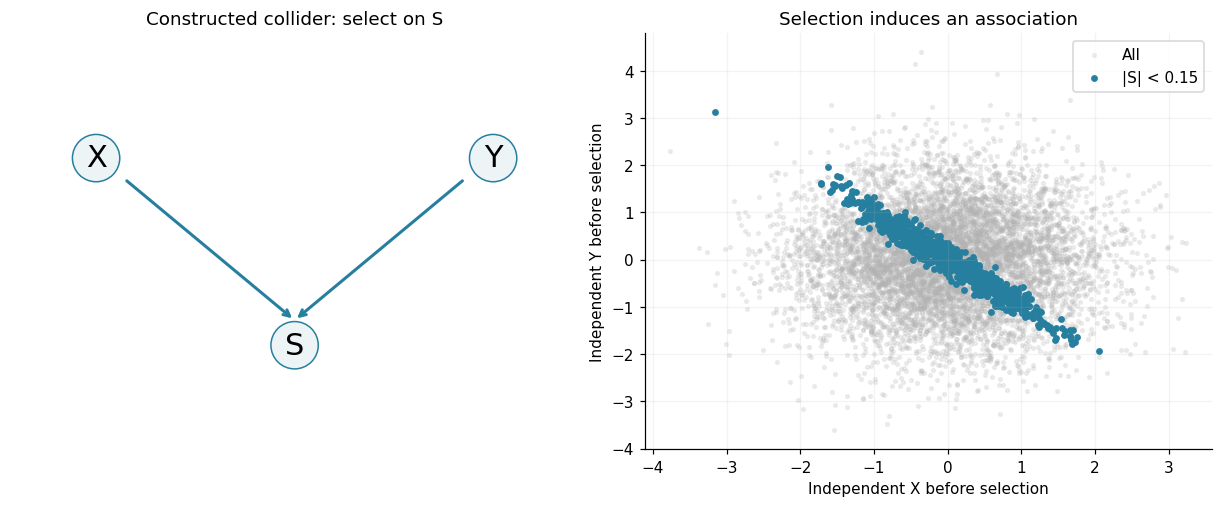

**تفسیر خروجی اجرای حاضر:** r در کل=-0.011؛ در 725 مورد انتخاب‌شده=-0.971. این مثال نشان می‌دهد چرا شرطی‌کردن بر collider می‌تواند رابطه بسازد.

In [19]:
rng=np.random.default_rng(202618)
xx=rng.normal(size=8000); yy=rng.normal(size=8000); selection=xx+yy+rng.normal(scale=.15,size=8000); chosen=np.abs(selection)<.15
fig,axes=plt.subplots(1,2,figsize=(11,4.5),layout='constrained'); axes[0].axis('off')
for name,pos in [('X',(.15,.7)),('Y',(.85,.7)),('S',(.5,.25))]: axes[0].text(*pos,name,ha='center',va='center',fontsize=20,bbox=dict(boxstyle='circle',facecolor='#edf4f6',edgecolor=BLUE),transform=axes[0].transAxes)
for start in [(.2,.65),(.8,.65)]: axes[0].annotate('',xy=(.5,.31),xytext=start,xycoords='axes fraction',arrowprops=dict(arrowstyle='->',color=BLUE,lw=2))
axes[0].set_title('Constructed collider: select on S')
axes[1].scatter(xx,yy,s=6,color='0.7',alpha=.2,label='All'); axes[1].scatter(xx[chosen],yy[chosen],s=12,color=BLUE,label='|S| < 0.15'); axes[1].set(xlabel='Independent X before selection',ylabel='Independent Y before selection',title='Selection induces an association'); axes[1].legend(); show()
say(f'r در کل={np.corrcoef(xx,yy)[0,1]:.3f}؛ در {chosen.sum()} مورد انتخاب‌شده={np.corrcoef(xx[chosen],yy[chosen])[0,1]:.3f}. این مثال نشان می‌دهد چرا شرطی‌کردن بر collider می‌تواند رابطه بسازد.')

#### راهنمای خواندن نمودار و نتیجه

در پنل چپ دو پیکان به S می‌رسند؛ این یک ادعای سازندهٔ سناریوست. در پنل راست نقاط خاکستری کل نمونه و نقاط آبی زیرگروه انتخاب‌شده‌اند. جهت منفی در انتخاب، رابطهٔ تازه‌ای است که از شرط بر معلول مشترک ایجاد شده؛ آن را به جامعهٔ کامل تعمیم ندهید. حذف اثر انتخاب نیز بدون دانستن سازوکار انتخاب همیشه ممکن نیست.

#### دام رایج

کنترل متغیرِ پس از درمان می‌تواند بخشی از اثر را حذف یا مسیر سوگیری باز کند. فهرست بلند کنترل‌ها جای دانش مسئله را نمی‌گیرد.

#### تمرین

برای اثر کل طراحی بر خستگی، آیا باید زمان استفاده‌ای را که خود طراحی تغییر داده همیشه کنترل کنیم؟

#### پاسخ تشریحی

نه لزوماً. اگر زمان استفاده میانجی باشد، کنترل آن اثر کل را حذف می‌کند و کمیت هدف عوض می‌شود. باید اثر کل/مستقیم، ترتیب زمانی و فرض‌ها پیش از تحلیل روشن شوند.

### درس 19. اثر علّی، پیامد بالقوه و وزن‌دهی Propensity

**پرسش شروع:** کاربران حرفه‌ای بیشتر طرح جدید را انتخاب کرده‌اند؛ اختلاف عملکرد واقعاً اثر طرح است؟

#### مفهوم، دقیق اما ساده

برای هر فرد، پیامد بالقوه Y(1) وY(0) را تصور می‌کنیم؛ اثر متوسط ATE میانگین تفاوت آن‌هاست، اما برای یک فرد معمولاً فقط یکی مشاهده می‌شود. آزمایش تصادفی کمک می‌کند گروه‌ها قابل‌مقایسه شوند. در دادهٔ مشاهده‌ای، شناسایی با وزن propensity به فرض‌هایی مانند سازگاریِ تعریف درمان، عدم مخدوش‌سازی اندازه‌گیری‌نشده، مثبت‌بودن احتمال هر درمان در سطح ویژگی‌ها و نبود تداخلِ نامتناسب متکی است. نمره propensity احتمال دریافت درمان با توجه به متغیرهای پیش از درمان است، نه احتمال موفقیت پیامد. وزن‌های معکوس گروه‌ها را به یک توزیع هدف نزدیک می‌کنند؛ اما فرض‌های شناسایی را از داده اثبات نمی‌کنند.

#### فرمول و قرارداد

```text
ATE=E[Y(1)−Y(0)]
e(X)=P(T=1|X); weights=T/e(X)+(1−T)/(1−e(X)).
```

#### مثال حل‌شده

C را ویژگیِ مهارت بسازید؛ احتمال انتخاب طرح جدید در C=۰ برابر۰٫۲ و در C=۱ برابر۰٫۸ است. پیامد از Y=۲T+۳C+ε تولید شود، پس اثر علّیِ معلومِ سازنده ۲ است. اختلاف خام، تفاوت مهارت را هم جذب می‌کند. با propensity معلومِ همین سناریو، میانگین‌های وزنیِ خودنرمال‌شده را محاسبه می‌کنیم. در پژوهش واقعی e(X) معلوم نیست و باید مناسب برآورد و تعادل بررسی شود؛ در اینجا مسئلهٔ برآورد propensity را عمداً جدا گذاشته‌ایم.

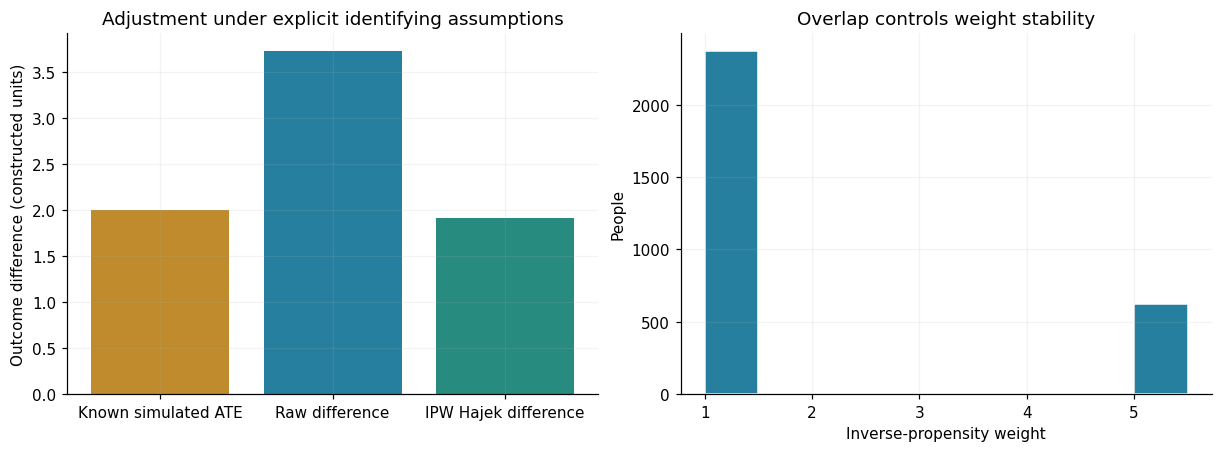

**تفسیر خروجی اجرای حاضر:** اثر سازنده=۲، اختلاف خام=3.734 و برآورد IPW خودنرمال‌شده=1.911. propensity در این مثال از سازوکار معلوم آمده است؛ روی دادهٔ واقعی نبود مخدوش‌کنندهٔ پنهان را از این تطابق نمی‌توان نتیجه گرفت.

In [20]:
rng=np.random.default_rng(202619)
cc=rng.binomial(1,.5,3000); propensity=.2+.6*cc; treatment=rng.binomial(1,propensity); outcome=2*treatment+3*cc+rng.normal(size=len(cc))
naive=outcome[treatment==1].mean()-outcome[treatment==0].mean(); w1=treatment/propensity; w0=(1-treatment)/(1-propensity); ipw=(w1@outcome)/w1.sum()-(w0@outcome)/w0.sum(); weight=w1+w0
fig,axes=plt.subplots(1,2,figsize=(11,4),layout='constrained'); axes[0].bar(['Known simulated ATE','Raw difference','IPW Hajek difference'],[2,naive,ipw],color=[GOLD,BLUE,TEAL]); axes[0].set(ylabel='Outcome difference (constructed units)',title='Adjustment under explicit identifying assumptions'); axes[1].hist(weight,bins=np.linspace(1,5.5,10),color=BLUE,edgecolor='white'); axes[1].set(xlabel='Inverse-propensity weight',ylabel='People',title='Overlap controls weight stability'); show()
say(f'اثر سازنده=۲، اختلاف خام={naive:.3f} و برآورد IPW خودنرمال‌شده={ipw:.3f}. propensity در این مثال از سازوکار معلوم آمده است؛ روی دادهٔ واقعی نبود مخدوش‌کنندهٔ پنهان را از این تطابق نمی‌توان نتیجه گرفت.')

#### راهنمای خواندن نمودار و نتیجه

سه ستون اثر واقعیِ سناریو، اختلاف خام و اختلاف وزنی را نشان می‌دهند. وزن‌دهی ممکن است نزدیک‌تر شود، نه اینکه در هر نمونه دقیقاً ۲ بدهد. هیستوگرام وزن‌ها دربارهٔ ناپایداری سرنخ می‌دهد. وزن بسیار بزرگ معمولاً علامت هم‌پوشانی کم و دقت پایین است؛ حذف یا برش وزن نیز کمیت هدف و سوگیری را تغییر می‌دهد.

#### دام رایج

نتیجهٔ وزن‌دهی را بدون فرض «همهٔ مخدوش‌کننده‌های لازم اندازه‌گیری شده‌اند» علّی اعلام نکنید. ستون‌های پس از درمان را بی‌منطق وارد propensity نکنید.

#### تمرین

اگر گروهی از کاربران هرگز طرح قدیم را نمی‌گیرند، چه فرضی مشکل دارد؟

#### پاسخ تشریحی

مثبت‌بودن/هم‌پوشانی؛ در آن ناحیه پیامد ضدواقعِ طرح قدیم از داده شناسایی نمی‌شود. جمعیت هدف باید محدود یا اطلاعات و فرض‌های اضافی روشن شوند.

### درس 20. دادهٔ گمشده: MCAR، MAR، MNAR و جایگذاری

**پرسش شروع:** افرادی که امتیاز پایین‌تری دارند، کمتر فرم رضایت را پر می‌کنند؛ میانگین پاسخ‌ها چه معنایی دارد؟

#### مفهوم، دقیق اما ساده

MCAR یعنی احتمال گم‌شدن مستقل از دادهٔ کامل است. MAR یعنی پس از شرطی‌کردن بر اطلاعات مشاهده‌شدهٔ مناسب، گم‌شدن به مقدارِ مشاهده‌نشده وابسته نیست. MNAR وابستگیِ باقی‌مانده به مقدارِ ندیده یا سازوکار نامشاهده را توصیف می‌کند. MAR یک فرض دربارهٔ فرایند است و عموماً فقط از جدولِ ناقص قابل اثبات نیست. حذف سطر، پرکردن با میانگین، مدل‌سازی و multiple imputation اهداف و فرض‌های متفاوت دارند. میانگین‌گذاری، پراکندگی را مصنوعی کم و رابطه‌ها را خراب می‌کند؛ «دیگر خانهٔ خالی نداریم» به معنی بازگرداندن اطلاعات نیست. برای پیش‌بینی، جایگذاری باید داخل هر fold و با آموزش همان fold انجام شود.

#### فرمول و قرارداد

```text
Observed data + missingness mechanism + assumptions → valid analysis
Single mean imputation treats guessed values as if known unless uncertainty is handled separately.
```

#### مثال حل‌شده

متغیر x را برای همه ببینید و y=۵۰+۱۰x+ε بسازید. هرچه x بزرگ‌تر باشد، احتمال ثبت y کمتر شود؛ چون x مشاهده شده و سازوکار فقط به آن وابسته است، این سناریو MAR است. میانگین yهای ثبت‌شده با میانگین کاملِ معلومِ شبیه‌سازی فرق می‌کند. پرکردن همهٔ yهای غایب با میانگین مشاهده‌شده، همان میانگین سوگیر را حفظ و SD را کم می‌کند. اگر ناپاسخ‌دهی به خود y حتی بعد از دانستن x وابسته بود، MNAR و حساسیت‌سنجی مهم می‌شد.

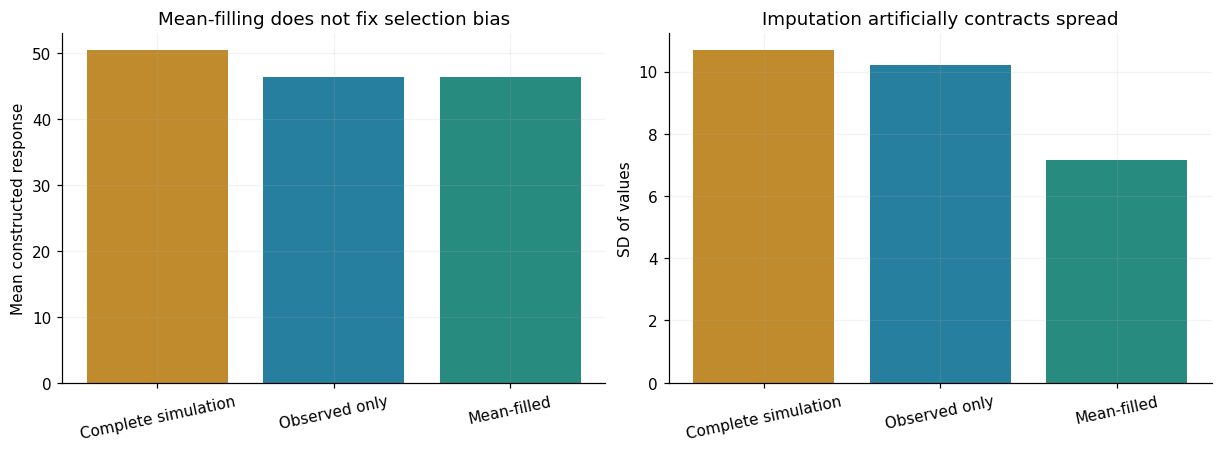

**تفسیر خروجی اجرای حاضر:** 51.1% مقدار y غایب است. میانگین کامل=50.44، مشاهده‌شده=46.31؛ پرکردن با میانگین آن را به 46.31 می‌رساند، نه لزوماً حقیقت. SD از 10.22 به 7.15 می‌رسد.

In [21]:
rng=np.random.default_rng(202620)
xx=rng.normal(size=3000); complete=50+10*xx+rng.normal(scale=4,size=len(xx)); observed=rng.random(len(xx))<1/(1+np.exp(xx)); seen=complete[observed]; filled=np.where(observed,complete,seen.mean())
fig,axes=plt.subplots(1,2,figsize=(11,4),layout='constrained'); labels=['Complete simulation','Observed only','Mean-filled']
axes[0].bar(labels,[complete.mean(),seen.mean(),filled.mean()],color=[GOLD,BLUE,TEAL]); axes[0].set(ylabel='Mean constructed response',title='Mean-filling does not fix selection bias'); axes[1].bar(labels,[complete.std(ddof=1),seen.std(ddof=1),filled.std(ddof=1)],color=[GOLD,BLUE,TEAL]); axes[1].set(ylabel='SD of values',title='Imputation artificially contracts spread');
for ax in axes: ax.tick_params(axis='x',labelrotation=12)
show(); say(f'{(~observed).mean():.1%} مقدار y غایب است. میانگین کامل={complete.mean():.2f}، مشاهده‌شده={seen.mean():.2f}؛ پرکردن با میانگین آن را به {filled.mean():.2f} می‌رساند، نه لزوماً حقیقت. SD از {seen.std(ddof=1):.2f} به {filled.std(ddof=1):.2f} می‌رسد.')

#### راهنمای خواندن نمودار و نتیجه

پنل اول میانگین کاملِ قابل‌دانستن فقط در شبیه‌سازی را با میانگین مشاهده‌شده و پرشده مقایسه می‌کند. پنل دوم نشان می‌دهد SD دادهٔ پرشده کوچک شده است. این کاهش، بهبود دقت واقعیِ برآورد نیست؛ یک اثر مکانیکی از تکرار عدد میانگین است. در کار واقعی y کامل را نداریم تا به این سادگی خطا را بسنجیم.

#### دام رایج

پرکردن مقدار گمشده با صفر بدون معنای واقعیِ صفر، یا fitکردن imputer روی کل داده قبل از CV، از خطاهای پرتکرارند.

#### تمرین

اگر همهٔ مقادیر خالی را با میانگین پر کنیم، آیا می‌توان CI را با n کامل و SD جدید محاسبه کرد؟

#### پاسخ تشریحی

آن CI معمولاً بیش از حد مطمئن است؛ مقدارهای جایگذاری‌شده مشاهدهٔ مستقل تازه نیستند و عدم‌قطعیتِ گم‌شدن و جایگذاری باید در روش مناسب لحاظ شود.

## فصل ۶ · مدل پایدار و اطلاعات

### درس 21. آمار مقاوم، MAD، میانگین بریده و نفوذ مشاهده

**پرسش شروع:** درآمد یا زمان پاسخ یک نفر هزار برابر دیگران است؛ حذفش کنیم یا مدل را عوض کنیم؟

#### مفهوم، دقیق اما ساده

مقاومت یعنی حساسیت محدودترِ یک برآوردگر به آلودگی یا مقدارهای بسیار دور، نه نادیده‌گرفتن هر مشاهدهٔ نامطلوب. میانه با جابه‌جایی یک مقدار دور معمولاً کمتر از میانگین تغییر می‌کند. MAD میانهٔ قدر مطلق فاصله از میانه است؛ ضرب در حدود۱٫۴۸۲۶ آن را تحت نرمال به مقیاس SD سازگار می‌کند، نه اینکه برای هر توزیع همان SD شود. میانگین بریده بخشی از دو انتها را حذف می‌کند و عملاً کمیت خلاصهٔ متفاوتی هدف می‌گیرد. برآوردهای Huber برای خطاهای کوچک شبیه مربع و برای خطاهای بزرگ شبیه قدرمطلق‌اند. انتخاب روش به هدف، اصالت مقدار و هزینهٔ حساسیت بستگی دارد؛ پرت بودن آماری با خطای اندازه‌گیری یکی نیست.

#### فرمول و قرارداد

```text
MAD=median(|x−median(x)|)
Normal-consistent scale ≈1.4826×MAD
Mean has unbounded sensitivity to a single value.
```

#### مثال حل‌شده

۹ زمان ۹،۱۰،۱۰،۱۱،۱۱،۱۲،۱۲،۱۳،۱۴ بسازید و مقدار دهم را از۱۴ تا۲۰۰ تغییر دهید. میانگین رشد می‌کند، میانه به یک دامنهٔ محدود می‌چسبد و میانگین بریدهٔ۱۰٪ اثر بزرگ‌ترین و کوچک‌ترین مقدار را حذف می‌کند. اگر سؤال هزینهٔ کلِ انتظار کاربران باشد، همان مقدار خیلی بزرگ ممکن است واقعی و از نظر کسب‌وکار بسیار مهم باشد؛ میانه به‌تنهایی آن هزینه را پنهان می‌کند. پس «روش مقاوم» را همراه نمودار انتهاها و پرسش گزارش کنید.

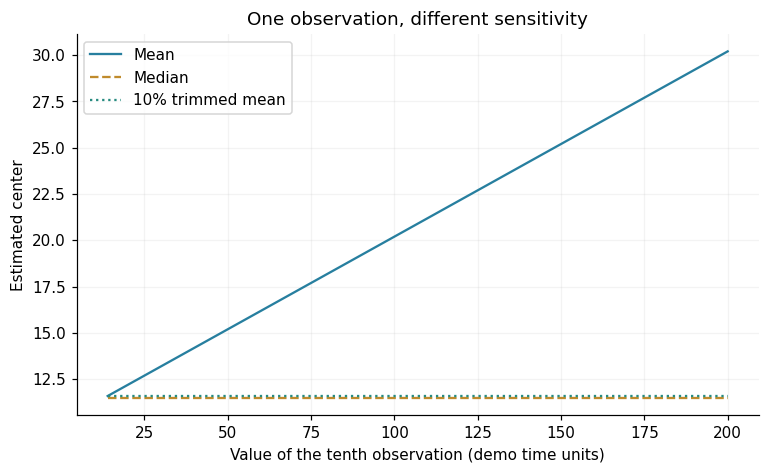

**تفسیر خروجی اجرای حاضر:** با مقدار دهم=۲۰۰، میانگین=30.20، میانه=11.50 و MAD مقیاس‌شدهٔ نرمال=2.22 است. میانه و میانگین کمیت‌های متفاوتی‌اند؛ مقاوم‌تر بودن، اعتبار خودکارِ حذف انتها را نمی‌دهد.

In [22]:
rng=np.random.default_rng(202621)
base=np.array([9,10,10,11,11,12,12,13,14]); extremes=np.linspace(14,200,100); methods=[]
for value in extremes:
    vals=np.r_[base,value]; methods.append([vals.mean(),np.median(vals),stats.trim_mean(vals,.1)])
fig,ax=plt.subplots(); arr=np.array(methods)
for j,name,style in [(0,'Mean','-'),(1,'Median','--'),(2,'10% trimmed mean',':')]: ax.plot(extremes,arr[:,j],label=name,ls=style)
ax.set(xlabel='Value of the tenth observation (demo time units)',ylabel='Estimated center',title='One observation, different sensitivity'); ax.legend(); show()
vals=np.r_[base,200]; mad=stats.median_abs_deviation(vals,scale='normal')
say(f'با مقدار دهم=۲۰۰، میانگین={vals.mean():.2f}، میانه={np.median(vals):.2f} و MAD مقیاس‌شدهٔ نرمال={mad:.2f} است. میانه و میانگین کمیت‌های متفاوتی‌اند؛ مقاوم‌تر بودن، اعتبار خودکارِ حذف انتها را نمی‌دهد.')

#### راهنمای خواندن نمودار و نتیجه

محور افقی مقدار دهم و عمودی برآورد مرکز است؛ این نمودار تغییرِ برآورد به ازای یک مشاهده است، نه توزیع نمونه‌گیری. خطِ میانه صاف‌تر است اما الزاماً برای همهٔ تصمیم‌ها بهتر نیست. مقدار MAD را همراه قرارداد مقیاس‌بندی و وجود ties بخوانید؛ اگر بیش از نیمی از مقادیر یکسان باشند، MAD می‌تواند صفر شود.

#### دام رایج

حذف خودکار هر مقدار بیرون ۱٫۵IQR می‌تواند گروه‌های واقعی را حذف و واریانس/اثر را منحرف کند. ابتدا منبع و واحد را بررسی کنید.

#### تمرین

برای پایش زمان پاسخ، چرا هم میانه و هم صدک۹۹ مفیدند؟

#### پاسخ تشریحی

میانه تجربهٔ معمول و صدک۹۹ بخش کند انتهایی را توصیف می‌کند. یکی جای دیگری نیست؛ تعریف صدک، حجم نمونه و عدم‌قطعیت انتهاها نیز باید گزارش شود.

### درس 22. بایاس–واریانس، منظم‌سازی و Ridge

**پرسش شروع:** مدلی که از همهٔ نقاط آموزش می‌گذرد چرا روی دادهٔ جدید بد عمل می‌کند؟

#### مفهوم، دقیق اما ساده

مدل بسیار انعطاف‌پذیر می‌تواند نویزِ نمونه را هم یاد بگیرد. بایاس–واریانس راهی برای فکرکردن به خطای مورد انتظار مدل در تکرار آموزش است، نه اینکه برای هر دادهٔ واقعی به سادگی دو عدد قابل مشاهده داشته باشیم. منظم‌سازی با جریمه‌کردن پیچیدگی، بخشی از انعطاف را کم می‌کند؛ معمولاً بایاس را بالا و واریانس را پایین می‌آورد، ولی مقدار نهایی خطا به مسئله وابسته است. Ridge ضرایب را با جریمهٔ L2 جمع می‌کند و برای هم‌خطی مفید است؛ مقدار α و مقیاس ویژگی‌ها مهم‌اند. استانداردسازی و انتخاب α باید فقط در آموزش و foldهای داخلی انجام شوند. آزمون نهایی برای انتخاب درجه و α دوباره مصرف نمی‌شود.

#### فرمول و قرارداد

```text
Ridge minimizes ||y−Xβ||² + α||β||²
The intercept is generally not penalized; scaling changes what a unit penalty means.
```

#### مثال حل‌شده

۳۰ نقطه از sin(x) با نویز بسازید. درجهٔ۱۲ِ چندجمله‌ای را یک بار بدون جریمه و یک بار با Ridge مقایسه کنید. جست‌وجوی شبکه‌ایِ Pipeline کامل مقدار α را در CV داخلیِ همین۳۰ نقطه انتخاب می‌کند. هزار نقطهٔ آزمون مستقلِ همان فرایند ساخته می‌شوند و فقط برای گزارش خطای نهایی استفاده می‌شوند. نتیجهٔ یک بذر تضمین نمی‌کند Ridge همیشه برنده باشد؛ طراحی مثال برای دیدن سازوکار نوسان و کنترل آن است، نه مسابقهٔ عمومی الگوریتم‌ها.

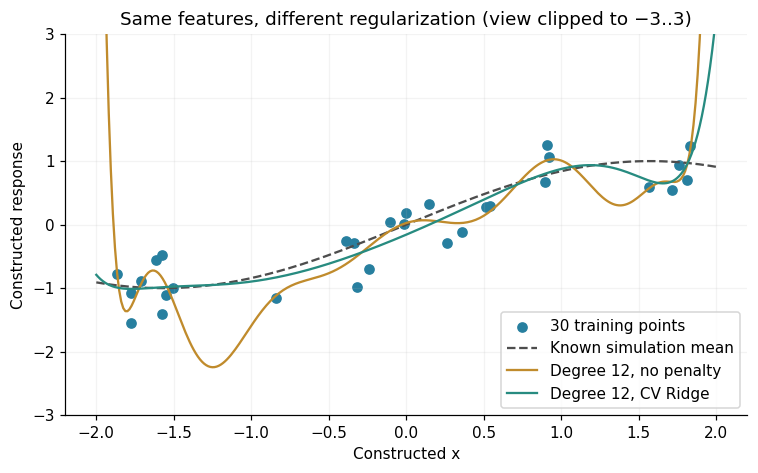

**تفسیر خروجی اجرای حاضر:** α منتخبِ CV داخلی=0.1. MSE آزمون مستقل: بدون جریمه=3.2737، Ridge=0.1706. این مقایسه یک اجرای ساختگی است، نه تضمین برتری همیشگی.

In [23]:
rng=np.random.default_rng(202622)
from sklearn.preprocessing import PolynomialFeatures,StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression,RidgeCV
train_x=rng.uniform(-2,2,(30,1)); train_y=np.sin(train_x[:,0])+rng.normal(scale=.3,size=30); test_x=rng.uniform(-2,2,(1000,1)); test_y=np.sin(test_x[:,0])+rng.normal(scale=.3,size=1000)
ols=make_pipeline(PolynomialFeatures(12,include_bias=False),StandardScaler(),LinearRegression()).fit(train_x,train_y)
# Scaling must be fit inside each CV fold: use GridSearchCV around the entire pipeline.
from sklearn.model_selection import GridSearchCV,KFold
from sklearn.linear_model import Ridge
search=GridSearchCV(make_pipeline(PolynomialFeatures(12,include_bias=False),StandardScaler(),Ridge()),{'ridge__alpha':np.logspace(-3,3,13)},cv=KFold(5,shuffle=True,random_state=42),scoring='neg_mean_squared_error').fit(train_x,train_y)
gg=np.linspace(-2,2,300)[:,None]; fig,ax=plt.subplots(); ax.scatter(train_x[:,0],train_y,color=BLUE,label='30 training points'); ax.plot(gg[:,0],np.sin(gg[:,0]),color='0.3',ls='--',label='Known simulation mean'); ax.plot(gg[:,0],ols.predict(gg),color=GOLD,label='Degree 12, no penalty'); ax.plot(gg[:,0],search.predict(gg),color=TEAL,label='Degree 12, CV Ridge'); ax.set(xlabel='Constructed x',ylabel='Constructed response',ylim=(-3,3),title='Same features, different regularization (view clipped to −3..3)'); ax.legend(); show()
say(f'α منتخبِ CV داخلی={search.best_params_["ridge__alpha"]:.4g}. MSE آزمون مستقل: بدون جریمه={mean_squared_error(test_y,ols.predict(test_x)):.4f}، Ridge={mean_squared_error(test_y,search.predict(test_x)):.4f}. این مقایسه یک اجرای ساختگی است، نه تضمین برتری همیشگی.')

#### راهنمای خواندن نمودار و نتیجه

ابر نقاط، آموزشِ نویزی است؛ خط تیره حقیقتِ معلومِ شبیه‌سازی و دو منحنی برازش‌اند. خطای کمِ آموزش با نزدیک‌بودن به حقیقت یا خطای آزمون یکی نیست. حاشیهٔ دامنه معمولاً محل نوسان شدیدتر چندجمله‌ای است. عنوان «بهترین α» فقط به شبکهٔ مقادیر و CV داخلیِ همین طرح مربوط است.

#### دام رایج

استفاده از آزمون برای انتخاب α، حتی اگر فقط یک پارامتر باشد، ارزیابی نهایی را خوش‌بینانه می‌کند. Pipeline همهٔ نشت‌ها را خودکار حل نمی‌کند؛ جداسازی فرد و زمان هم لازم است.

#### تمرین

اگر همهٔ ویژگی‌ها را در عدد۱۰۰ ضرب کنیم، همان α الزاماً همان مدل Ridge را می‌دهد؟

#### پاسخ تشریحی

خیر؛ جریمه به مقیاس ضرایب وابسته است. استانداردسازی مناسب و انتخاب α در فرایند آموزش لازم است.

### درس 23. تبدیل لگاریتم، نابرابری Jensen و بازگشت به واحد اصلی

**پرسش شروع:** میانگین لگاریتم قیمت را exp می‌کنیم؛ چرا میانگین قیمت واقعی به دست نمی‌آید؟

#### مفهوم، دقیق اما ساده

تبدیل لگاریتم فاصله‌های ضربی را به جمعی می‌برد و می‌تواند پراکندگی وابسته به سطح را کمتر کند. اما هدف آماری هم تغییر می‌کند: exp(mean(log X)) میانگین هندسی است، نه میانگین حسابی. طبق Jensen برای متغیر مثبت، میانگین هندسی از حسابی بزرگ‌تر نیست. در مدل لگ‌نرمال با log X نرمالِ میانگین μ و واریانس σ²، میانه exp(μ) و میانگین exp(μ+σ²/2) است. این تصحیح فقط تحت همان مدل معتبر است؛ در مدل‌های دیگر تصحیح بازتبدیل، smearing و ناهمسانی واریانس باید متناسب بررسی شوند. log برای صفر و منفی تعریف حقیقی ندارد؛ log1p هم معنای هدف را متفاوت می‌کند.

#### فرمول و قرارداد

```text
Geometric mean=exp(mean(log X))≤mean(X)
If log X~Normal(μ,σ²): median(X)=exp(μ); mean(X)=exp(μ+σ²/2).
```

#### مثال حل‌شده

اعداد۱،۱۰،۱۰۰ میانگین حسابی۳۷ دارند؛ میانگین هندسی۱۰ است. در سناریوی لگ‌نرمال μ=۲ وσ=۱، میانهٔ نظری حدود۷٫۳۹ و میانگین حدود۱۲٫۱۸ می‌شود. ۵٬۰۰۰ داده می‌سازیم، هیستوگرام در مقیاس خام و لگ را کنار هم می‌بینیم و تخمین بازتبدیل ساده و تصحیح‌شده را مقایسه می‌کنیم. واحد پول یا زمان در این مثال قراردادی است؛ توصیهٔ قیمت‌گذاری یا سرمایه‌گذاری ارائه نمی‌شود.

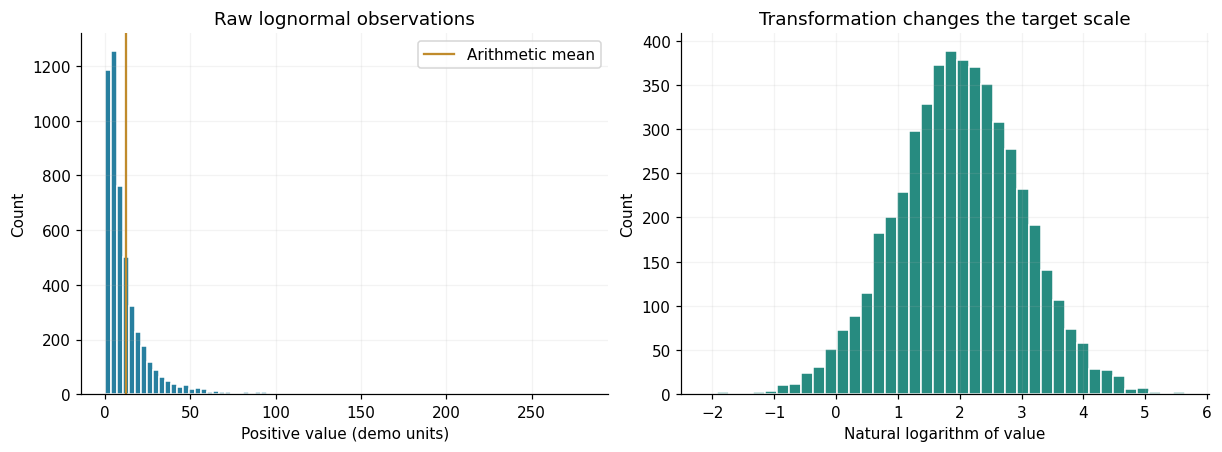

**تفسیر خروجی اجرای حاضر:** میانگین خام=12.270؛ exp میانگین لگ=7.354؛ تصحیح لگ‌نرمال=12.338. مقدار آخر به فرض نرمال‌بودن لگ و ساختار واریانس وابسته است؛ فرمول عمومیِ بی‌فرض نیست.

In [24]:
rng=np.random.default_rng(202623)
values=rng.lognormal(mean=2,sigma=1,size=5000); logs=np.log(values); naive_back=np.exp(logs.mean()); corrected=np.exp(logs.mean()+logs.var(ddof=1)/2)
fig,axes=plt.subplots(1,2,figsize=(11,4),layout='constrained'); axes[0].hist(values,bins=80,color=BLUE,edgecolor='white'); axes[0].axvline(values.mean(),color=GOLD,label='Arithmetic mean'); axes[0].set(xlabel='Positive value (demo units)',ylabel='Count',title='Raw lognormal observations'); axes[0].legend(); axes[1].hist(logs,bins=40,color=TEAL,edgecolor='white'); axes[1].set(xlabel='Natural logarithm of value',ylabel='Count',title='Transformation changes the target scale'); show()
say(f'میانگین خام={values.mean():.3f}؛ exp میانگین لگ={naive_back:.3f}؛ تصحیح لگ‌نرمال={corrected:.3f}. مقدار آخر به فرض نرمال‌بودن لگ و ساختار واریانس وابسته است؛ فرمول عمومیِ بی‌فرض نیست.')

#### راهنمای خواندن نمودار و نتیجه

پنل خام، انتهای راست را نشان می‌دهد؛ پنل لگ، شکل داده در واحدِ log را. خط میانگین روی نمودار لگ را نباید با میانگین در واحد خام یکی دانست. اگر پیش‌بینی هزینهٔ کل هدف باشد، پیش‌بینی میانه ممکن است هزینه را کم‌برآورد کند؛ اگر تجربهٔ معمول هدف باشد، میانه می‌تواند مناسب‌تر باشد.

#### دام رایج

برای زیباترشدن نمودار، log بگیرید ولی محور و واحد تازه را پنهان نکنید. exp کردن CI ضرایب نیز نوع پارامتر را تغییر می‌دهد؛ عنوان دقیق لازم است.

#### تمرین

در مدل log(y)=a+bx، افزایش یک واحد x چه تفسیر تقریبی دارد؟

#### پاسخ تشریحی

با فرض ساختار همان مدل، exp(b) نسبت میانه‌های شرطی در مدل لگ‌نرمالِ هم‌واریانس است؛ تقریب ۱۰۰b٪ برای b کوچک. نسبت میانگین‌ها با ناهمسانی واریانس ممکن است متفاوت باشد.

### درس 24. تجمیع جزئی، Shrinkage و شهود مدل چندسطحی

**پرسش شروع:** یک شعبه از دو سفارش دو موفقیت دارد و شعبه‌ای از هزار سفارش۹۰۰ موفقیت؛ کدام مطمئن‌تر است؟

#### مفهوم، دقیق اما ساده

برآورد جداگانهٔ هر گروه در گروه‌های کم‌داده ناپایدار است؛ ادغام کامل هم اختلاف واقعی گروه‌ها را حذف می‌کند. تجمیع جزئی اطلاعات مشترک را با اطلاعات اختصاصی ترکیب می‌کند. در مدل چندسطحی واقعی، پارامترهای گروه‌ها از یک توزیع جمعیتی می‌آیند و پارامترهای آن نیز برآورد یا دارای پیشین‌اند. برای دیدن سازوکار، می‌توان از پیشین Beta مشترکِ ثابت استفاده کرد: گروه کوچک بیشتر و گروه بزرگ کمتر به میانگین پیشین جمع می‌شود. این نمایش، برازش کامل سلسله‌مراتبی نیست. اگر گروه‌ها واقعاً قابل‌تبادل نباشند یا تفاوت ساختاری مهم داشته باشند، جمع‌کردن مشترک می‌تواند مسئله را پنهان کند.

#### فرمول و قرارداد

```text
Posterior mean=(s+a)/(n+a+b)
= [n/(n+a+b)]×(s/n) + [(a+b)/(n+a+b)]×[a/(a+b)].
```

#### مثال حل‌شده

شعبه‌ها با (موفقیت،n) برابر (۲،۲)،(۸،۱۰)،(۷۰،۱۰۰)،(۹۰۰،۱۰۰۰) بسازید. پیشینِ آموزشیِ ثابت Beta(7,3) میانگین۰٫۷ و قدرت معادل۱۰ تلاش دارد. برآورد۲/۲ از۱ به۹/۱۲=۰٫۷۵ می‌رسد، ولی۹۰۰/۱۰۰۰ فقط اندکی به۰٫۷ نزدیک می‌شود. این «تنبیه شعبهٔ کوچک» نیست؛ عدم‌قطعیت بیشتر دادهٔ کمتر را منعکس می‌کند. اما انتخاب پیشین۷،۳ باید توجیه یا حساسیت‌سنجی شود؛ از خود این مثال، نرخ واقعی یک شرکت به دست نیامده است.

,n,raw rate,fixed-prior posterior mean,95% lower,95% upper
0,2,1.0,0.75000,0.482244,0.939782
1,10,0.8,0.75000,0.544347,0.908534
2,100,0.7,0.70000,0.611523,0.781589
3,1000,0.9,0.89802,0.878635,0.915913


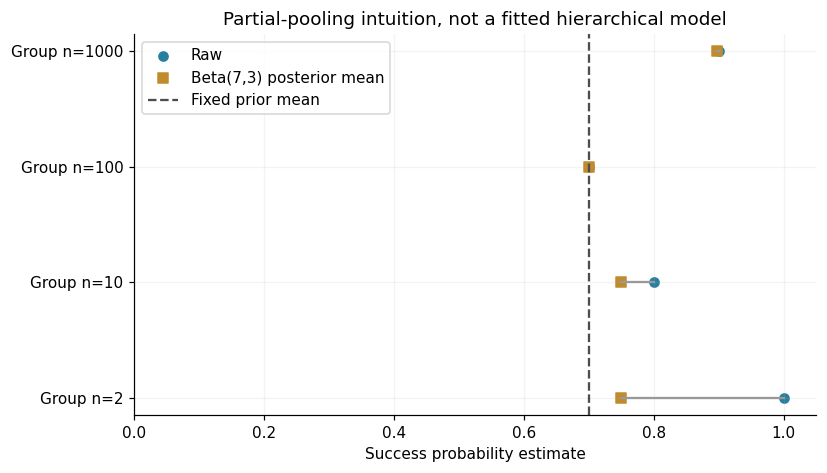

**تفسیر خروجی اجرای حاضر:** گروه n=۲ از 1.00 به 0.75 جمع شد؛ گروه n=۱۰۰۰ از 0.900 به 0.898. بازهٔ اعتباری گروه کوچک [0.482,0.940] است؛ عدم‌قطعیت رتبه‌بندی را نادیده نگیرید.

In [25]:
rng=np.random.default_rng(202624)
s=np.array([2,8,70,900]); n=np.array([2,10,100,1000]); a,b=7,3; raw=s/n; partial=(s+a)/(n+a+b); intervals=np.array([stats.beta.ppf([.025,.975],a+si,b+ni-si) for si,ni in zip(s,n)])
display(pd.DataFrame({'n':n,'raw rate':raw,'fixed-prior posterior mean':partial,'95% lower':intervals[:,0],'95% upper':intervals[:,1]}))
fig,ax=plt.subplots()
for i in range(4): ax.plot([raw[i],partial[i]],[i,i],color='0.6')
ax.scatter(raw,np.arange(4),color=BLUE,label='Raw'); ax.scatter(partial,np.arange(4),color=GOLD,marker='s',label='Beta(7,3) posterior mean'); ax.axvline(.7,color='0.3',ls='--',label='Fixed prior mean'); ax.set(yticks=np.arange(4),yticklabels=[f'Group n={v}' for v in n],xlabel='Success probability estimate',xlim=(0,1.05),title='Partial-pooling intuition, not a fitted hierarchical model'); ax.legend(); show()
say(f'گروه n=۲ از {raw[0]:.2f} به {partial[0]:.2f} جمع شد؛ گروه n=۱۰۰۰ از {raw[-1]:.3f} به {partial[-1]:.3f}. بازهٔ اعتباری گروه کوچک [{intervals[0,0]:.3f},{intervals[0,1]:.3f}] است؛ عدم‌قطعیت رتبه‌بندی را نادیده نگیرید.')

#### راهنمای خواندن نمودار و نتیجه

نقاط خام و جمع‌شده را با n بخوانید. خطوط بین دو نقطه مقدار جمع‌شدن را نشان می‌دهند؛ خط‌چین۰٫۷ میانگین پیشین است. این خطوط CI نیستند. بازهٔ اعتباری گروه کوچک معمولاً پهن‌تر است و رتبه‌بندی قطعی شعبه‌ها از یک برآورد نقطه‌ای توصیه نمی‌شود. برای مدل کامل، ناهمگنی و ارتباط گروه‌ها باید بررسی شود.

#### دام رایج

نام «چندسطحی» را روی هر میانگین وزنی نگذارید؛ اینجا پیشین مشترک ثابت است، نه مدل سلسله‌مراتبی با فراپارامترهای آموخته‌شده.

#### تمرین

اگر a+b را بیشتر کنیم، برای یک شعبه با n ثابت چه رخ می‌دهد؟

#### پاسخ تشریحی

قدرت پیشین بیشتر و جمع‌شدن به میانگین a/(a+b) قوی‌تر می‌شود، اگر آن میانگین ثابت نگه داشته شود. این باید با دانش و تحلیل حساسیت همراه باشد.

## فصل ۷ · اعتماد به پیش‌بینی

### درس 25. نشت داده، Pipeline و اعتبارسنجی گروهی و تو‌در‌تو

**پرسش شروع:** مدلی روی دادهٔ کاملاً تصادفی دقت خوب دارد؛ احتمالاً کشف نکرده، نشت کرده است.

#### مفهوم، دقیق اما ساده

آزمون باید اطلاعاتی باشد که در زمان یادگیری و انتخاب مدل دیده نشده است. نشت فقط ورود مستقیم y نیست؛ انتخاب ویژگی با کل داده، جایگذاری قبل از جداسازی، استانداردسازی خارج fold، تکرار یک فرد در آموزش و آزمون و استفاده از آینده هم نمونه‌های آن‌اند. Pipeline کمک می‌کند تبدیل‌های قابل‌آموزش در fold مناسب fit شوند. برای انتخاب پارامتر، CV داخلی و برای ارزیابی فرایند انتخاب، CV بیرونی یا آزمون نهاییِ مستقل لازم است. GroupKFold برای افراد/دستگاه‌های تکراری و طرح زمانی برای پیش‌بینی آینده به‌کار می‌روند؛ انتخاب تصادفی سطرها همیشه کافی نیست. هیچ ابزار خودکاری بدون تعریف زمان دسترسی ویژگی‌ها، نشت مفهومی را حل نمی‌کند.

#### فرمول و قرارداد

```text
Train-only fitting applies to preprocessing, feature selection and tuning.
Nested CV: inner folds select; outer folds estimate the selected workflow.
```

#### مثال حل‌شده

۱۸۰ ردیف، ۲٬۰۰۰ ویژگیِ نویز و یک برچسب تصادفی می‌سازیم. در روش غلط، بهترین۲۰ ویژگی با استفاده از همهٔ yها انتخاب می‌شوند و سپس CV انجام می‌شود؛ برچسب آزمون قبلاً در انتخاب ویژگی مصرف شده است. در روش درست SelectKBest داخل Pipeline است و هر fold انتخاب خودش را فقط با آموزش انجام می‌دهد. اگر دقت روش غلط بالاتر شد، این شاهد قابل‌تعمیم از رابطهٔ واقعی نیست؛ خودِ سازوکار داده هیچ رابطه‌ای ندارد. روش درست هم در یک نمونه دقیقاً۰٫۵ نمی‌شود.

,fold,leaked accuracy,pipeline accuracy
0,1,0.861111,0.527778
1,2,0.666667,0.583333
2,3,0.750000,0.416667
3,4,0.777778,0.555556
4,5,0.833333,0.472222


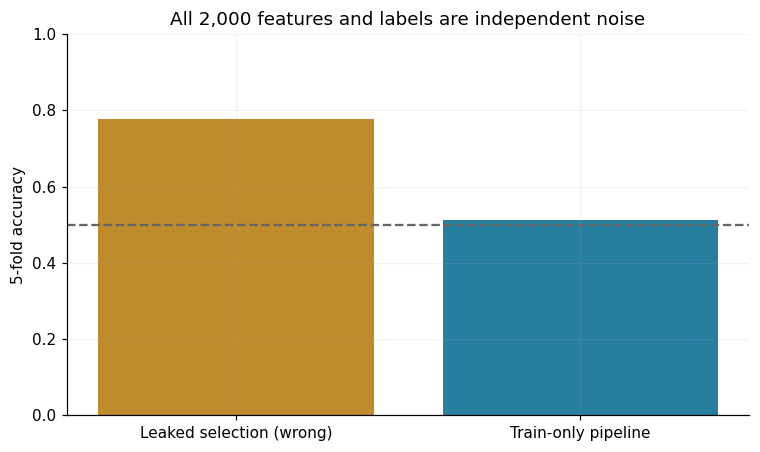

**تفسیر خروجی اجرای حاضر:** دقت با نشت=0.778، با Pipeline=0.511. داده هیچ سیگنالِ سازنده‌ای ندارد؛ اختلاف، اثر فرایند انتخاب است و نه اعتبار یک مدل واقعی.

In [26]:
rng=np.random.default_rng(202625)
from sklearn.feature_selection import SelectKBest,f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold,cross_val_score
noise_x=rng.normal(size=(180,2000)); random_y=rng.integers(0,2,180); cv=StratifiedKFold(5,shuffle=True,random_state=42)
leaked=SelectKBest(f_classif,k=20).fit_transform(noise_x,random_y)
wrong=cross_val_score(LogisticRegression(max_iter=3000),leaked,random_y,cv=cv)
proper=make_pipeline(SelectKBest(f_classif,k=20),StandardScaler(),LogisticRegression(max_iter=3000))
right=cross_val_score(proper,noise_x,random_y,cv=cv)
display(pd.DataFrame({'fold':np.arange(1,6),'leaked accuracy':wrong,'pipeline accuracy':right}))
fig,ax=plt.subplots(); ax.bar(['Leaked selection (wrong)','Train-only pipeline'],[wrong.mean(),right.mean()],color=[GOLD,BLUE]); ax.axhline(.5,color='0.4',ls='--'); ax.set(ylabel='5-fold accuracy',ylim=(0,1),title='All 2,000 features and labels are independent noise'); show()
say(f'دقت با نشت={wrong.mean():.3f}، با Pipeline={right.mean():.3f}. داده هیچ سیگنالِ سازنده‌ای ندارد؛ اختلاف، اثر فرایند انتخاب است و نه اعتبار یک مدل واقعی.')

#### راهنمای خواندن نمودار و نتیجه

میله‌ها میانگین دقت پنج fold در یک اجرای ثابت‌اند؛ خط۰٫۵ مرجعِ کلاس متوازنِ تقریبی است، نه CI یا تضمین دقت تصادفی. توزیع foldها و خط پایهٔ اکثریت را هم در جدول ببینید. شکل تفاوتِ فرایند را نشان می‌دهد؛ جست‌وجوی بذر برای بیشینه‌کردن اختلاف، خودش نمونه‌ای از انتخاب پس از مشاهده است.

#### دام رایج

استفادهٔ تکراری از همان مجموعهٔ آزمون برای انتخاب مدل، آزمون را عملاً به validation تبدیل می‌کند. نام‌گذاری «test» جلوی این مشکل را نمی‌گیرد.

#### تمرین

آیا وجود Pipeline کافی است اگر خریدهای یک فرد در هر دو سمت تقسیم باشند؟

#### پاسخ تشریحی

خیر؛ Pipeline تبدیل‌ها را درون fold نگه می‌دارد، ولی واحد جداسازی را درست انتخاب نمی‌کند. گروه‌بندی فرد یا زمان باید در خود splitter لحاظ شود.

### درس 26. عدم‌توازن کلاس، کالیبراسیون و تصمیمِ هزینه‌محور

**پرسش شروع:** دو مدل افراد را دقیقاً یکسان رتبه‌بندی می‌کنند، اما یکی با اطمینان کاذب عدد۰٫۹۹ می‌دهد.

#### مفهوم، دقیق اما ساده

رتبه‌بندی و احتمال‌دادن دو مهارت متفاوت‌اند. ROC/AUC از ترتیب امتیازها استفاده می‌کند؛ کالیبراسیون می‌پرسد بین مواردی که احتمال۰٫۲ گرفته‌اند تقریباً۲۰٪ مثبت‌اند یا نه. Brier میانگین مربعِ خطای احتمال است و هم اجزای کالیبراسیون و تفکیک را منعکس می‌کند. با کلاس نادر، precision/recall و حجم بررسی معمولاً کنار ROC لازم‌اند؛ PR نیز به نرخ پایه وابسته است. آستانهٔ۰٫۵ قراردادی است، نه همیشه بهینه. برای احتمالِ کالیبره، با هزینهٔ ثابت FP وFN و اقدام دودوییِ ساده، آستانهٔ نظری C_FP/(C_FP+C_FN) است؛ هزینه‌ها، محدودیت ظرفیت و تغییر نرخ پایه می‌توانند تصمیم را عوض کنند.

#### فرمول و قرارداد

```text
Brier=mean((p−y)²)
With calibrated p and simple fixed costs: predict positive if p>C_FP/(C_FP+C_FN).
```

#### مثال حل‌شده

۴٬۰۰۰ احتمال حقیقی از Beta(2,8) و برچسب برنولی می‌سازیم. پیش‌بینی اول همان احتمال سازنده است؛ دومی log-odds را سه برابر می‌کند و بیش‌اطمینان می‌شود. چون تبدیل یکنواخت است، AUC و رتبه‌بندی یکسان می‌مانند، اما Brier و نمودار کالیبراسیون فرق می‌کنند. اگر FN پنج واحد وFP یک واحد هزینه داشته باشد، آستانهٔ نظریِ احتمال کالیبره۱/۶ است. این هزینه قراردادی است، نه ارزش‌گذاری اخلاقی یا مالیِ واقعیِ افراد.

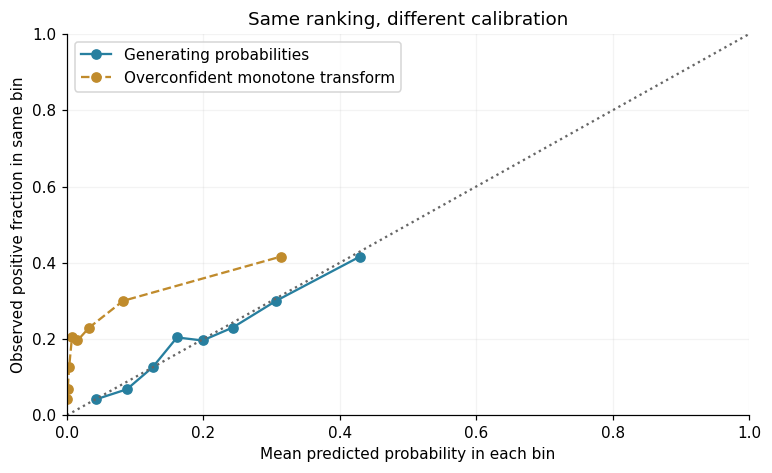

,threshold,precision,recall,FP,FN,cost FP+5FN
0,0.500000,0.579710,0.050569,29,751,3784
1,0.166667,0.281437,0.772440,1560,180,2460


**تفسیر خروجی اجرای حاضر:** AUC دو مدل=0.7039 و 0.7039؛ Brier=0.1452 و 0.1700. یکسانی AUC، کالیبراسیون یکسان را تضمین نکرد. هزینهٔ۱ و۵ صرفاً سناریوی آموزشی است.

In [27]:
rng=np.random.default_rng(202626)
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss,roc_auc_score,precision_score,recall_score
prob=rng.beta(2,8,4000); truth=rng.binomial(1,prob); over=1/(1+np.exp(-3*np.log(prob/(1-prob))))
fig,ax=plt.subplots()
for name,pred,style in [('Generating probabilities',prob,'-'),('Overconfident monotone transform',over,'--')]:
    fraction,mean_pred=calibration_curve(truth,pred,n_bins=8,strategy='quantile'); ax.plot(mean_pred,fraction,marker='o',ls=style,label=name)
ax.plot([0,1],[0,1],color='0.4',ls=':'); ax.set(xlabel='Mean predicted probability in each bin',ylabel='Observed positive fraction in same bin',xlim=(0,1),ylim=(0,1),title='Same ranking, different calibration'); ax.legend(); show()
rows=[]
for threshold in [.5,1/6]:
    pred=prob>threshold; fp=np.sum(pred&(truth==0)); fn=np.sum((~pred)&(truth==1)); rows.append([threshold,precision_score(truth,pred,zero_division=0),recall_score(truth,pred),fp,fn,fp+5*fn])
display(pd.DataFrame(rows,columns=['threshold','precision','recall','FP','FN','cost FP+5FN']))
say(f'AUC دو مدل={roc_auc_score(truth,prob):.4f} و {roc_auc_score(truth,over):.4f}؛ Brier={brier_score_loss(truth,prob):.4f} و {brier_score_loss(truth,over):.4f}. یکسانی AUC، کالیبراسیون یکسان را تضمین نکرد. هزینهٔ۱ و۵ صرفاً سناریوی آموزشی است.')

#### راهنمای خواندن نمودار و نتیجه

محور افقیِ reliability میانگین احتمال پیش‌بینی‌شدهٔ هر بازه و عمودی سهم مثبت واقعی همان بازه است. خط قطر، کالیبراسیون ایدئال است؛ تعداد محدود هر بازه نوسان ایجاد می‌کند. جدول هزینه برای دو آستانه با همان احتمالِ کالیبره محاسبه شده است، نه با احتمالات بیش‌اطمینان. این یک نمایش با مدلِ سازندهٔ معلوم است؛ در کار واقعی کالیبراسیون باید با دادهٔ جدا از آموزش تنظیم و آزمون شود.

#### دام رایج

AUC بالا به معنی احتمال درست یا بهترین آستانه نیست. یک عدد accuracy نیز خطاهای پرهزینهٔ کلاس نادر را پنهان می‌کند.

#### تمرین

اگر تبدیل یکنواخت امتیاز، AUC را ثابت نگه دارد، آیا می‌توان هر امتیازی را احتمال نامید؟

#### پاسخ تشریحی

خیر. رتبه ممکن است درست بماند، ولی معنای احتمالات و تصمیم هزینه‌محور خراب شود. باید کالیبراسیون، عدم‌قطعیت و نرخ پایه را بررسی کرد.

### درس 27. پیش‌بینی Conformal و ضمانتی که باید درست خوانده شود

**پرسش شروع:** مدل یک عدد پیش‌بینی می‌کند؛ چطور یک بازهٔ همراه با پوششِ قابل‌تعریف بسازیم؟

#### مفهوم، دقیق اما ساده

در split conformal، داده را به آموزش، کالیبراسیون و آزمون تقسیم می‌کنیم. مدل فقط با آموزش fit می‌شود؛ خطاهای مطلقِ کالیبراسیون امتیاز عدم‌انطباق‌اند. یک صدک با تصحیح نمونهٔ محدود انتخاب می‌کنیم و به پیش‌بینی نقطه‌ای کم و زیاد می‌کنیم. با تبادل‌پذیری دادهٔ کالیبراسیون و مشاهدهٔ آینده و رعایت استقلال نقش‌ها، پوشش حاشیه‌ای حداقل۱−α به دست می‌آید؛ این به معنی پوششِ شرطیِ هر x یا هر گروه نیست. مدل لازم نیست درست باشد، اما بازهٔ مدل بد معمولاً پهن و کم‌فایده می‌شود. تغییر توزیع، وابستگی زمانی و مصرف آزمون در تنظیم، ضمانت ساده را مخدوش می‌کنند.

#### فرمول و قرارداد

```text
k=ceil((n_cal+1)(1−α)); q=the k-th smallest calibration score
Prediction set: [f(x)−q,f(x)+q]; requires k≤n_cal or an infinite-bound convention.
```

#### مثال حل‌شده

۶۰۰ نقطه با رابطهٔ y=۲x+نویز و نویزی که با |x| بزرگ‌تر می‌شود بسازید. ۳۰۰ آموزش،۱۵۰ کالیبراسیون و۱۵۰ آزمون مستقلِ همان فرایند کنار می‌گذاریم. α=۰٫۱ یعنی هدف پوشش حاشیه‌ای۹۰٪. k=ceil(۱۵۱×۰٫۹)=۱۳۶ و q خطای۱۳۶ام مرتب‌شده است. بازهٔ ساده پهنای ثابت دارد، درحالی‌که نویز در انتهای محور بیشتر است؛ پس پوشش در بخش مرکزی و انتهایی می‌تواند متفاوت باشد، حتی اگر پوشش کل مناسب باشد.

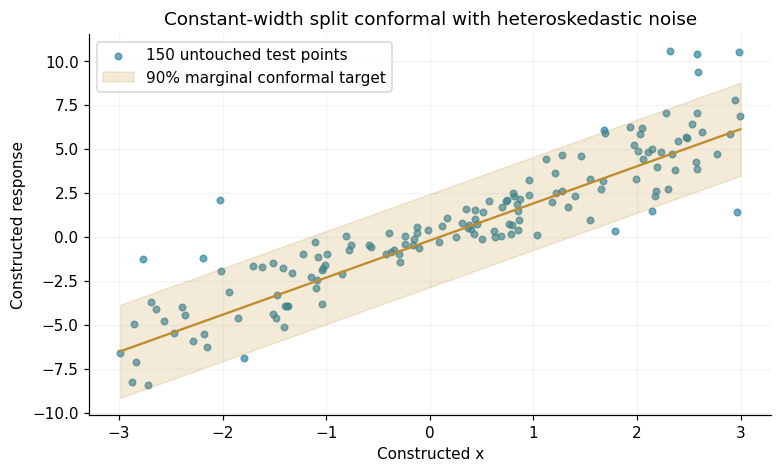

**تفسیر خروجی اجرای حاضر:** n کالیبراسیون=150، رتبهٔ تصحیح‌شده=136، نیم‌عرض q=2.650. پوشش آزمون این اجرا=92.0%؛ مرکز=100.0% و انتها=82.1%. ضمانت حاشیه‌ای، پوشش برابر همهٔ xها یا گروه‌ها نیست.

In [28]:
rng=np.random.default_rng(202627)
from sklearn.linear_model import LinearRegression
cx=rng.uniform(-3,3,(600,1)); cy=2*cx[:,0]+rng.normal(size=600)*(.3+.8*np.abs(cx[:,0])); model=LinearRegression().fit(cx[:300],cy[:300]); alpha=.1
scores=np.abs(cy[300:450]-model.predict(cx[300:450])); rank=int(np.ceil((len(scores)+1)*(1-alpha))); assert rank<=len(scores); q=np.sort(scores)[rank-1]
test_x=cx[450:]; test_y=cy[450:]; pred=model.predict(test_x); hits=np.abs(test_y-pred)<=q; order=np.argsort(test_x[:,0]); central=np.abs(test_x[:,0])<1.5
fig,ax=plt.subplots(); ax.scatter(test_x[:,0],test_y,color=BLUE,s=18,alpha=.65,label='150 untouched test points'); ax.plot(test_x[order,0],pred[order],color=GOLD); ax.fill_between(test_x[order,0],pred[order]-q,pred[order]+q,color=GOLD,alpha=.18,label='90% marginal conformal target'); ax.set(xlabel='Constructed x',ylabel='Constructed response',title='Constant-width split conformal with heteroskedastic noise'); ax.legend(); show()
say(f'n کالیبراسیون={len(scores)}، رتبهٔ تصحیح‌شده={rank}، نیم‌عرض q={q:.3f}. پوشش آزمون این اجرا={hits.mean():.1%}؛ مرکز={hits[central].mean():.1%} و انتها={hits[~central].mean():.1%}. ضمانت حاشیه‌ای، پوشش برابر همهٔ xها یا گروه‌ها نیست.')

#### راهنمای خواندن نمودار و نتیجه

نقاط آزمون و نوار بازه را ببینید؛ برای مرتب‌سازی نمودار فقط x مرتب می‌شود و هیچ نقطه‌ای از محاسبهٔ پوشش حذف نشده است. نرخ پوشش مشاهده‌شدهٔ۱۵۰ آزمون لزوماً دقیقاً۹۰٪ یا بالاتر نیست؛ ضمانت دربارهٔ احتمال حاشیه‌ای تحت فرض‌هاست، نه حد قطعیِ درصد هر مجموعهٔ محدود. دو زیرگروه را هم گزارش می‌کنیم تا پنهان‌شدن نابرابریِ پوشش معلوم شود.

#### دام رایج

عبارت «distribution-free» به معنی «بی‌نیاز از فرض و معتبر تحت هر تغییر توزیع» نیست. تبادل‌پذیری و تعریف نوع پوشش ضروری‌اند.

#### تمرین

اگر بازه در مجموع۹۰٪ پوشش دهد، آیا برای کاربران یک گروه کوچک هم خودکار۹۰٪ است؟

#### پاسخ تشریحی

خیر؛ پوشش حاشیه‌ای گروه‌ها را تضمین نمی‌کند. روش‌های گروه‌شرطی یا کالیبراسیون مناسب، حجم داده و مصالحهٔ پهنا/پوشش را باید جدا بررسی کرد.

### درس 28. خودهمبستگی، اعتبارسنجی زمانی و تغییر توزیع

**پرسش شروع:** صد مقدار پشت‌سرهم که تقریباً شبیه هم‌اند، چقدر اطلاعات تازه دارند؟

#### مفهوم، دقیق اما ساده

در سری زمانی، ترتیب داده بخشی از مسئله است. خودهمبستگی یعنی مقدارها با گذشتهٔ خود رابطه دارند؛ در AR(1) پایای ساده، اثر یک شوک با توان‌های φ کم می‌شود. وقتی φ مثبت و بزرگ است، میانگین صد روز به اندازهٔ صد مشاهدهٔ مستقل دقیق نیست. تقریب n_eff≈n(1−φ)/(1+φ) برای شرایط خاصِ AR(1) و طول کافی است؛ برای سری فصلی، غیرپایا یا وابستگی پیچیده قانون عمومی نیست. تقسیم تصادفی سطرها می‌تواند آینده را به آموزش بیاورد. اعتبارسنجی مبدأهای متحرک، gap مناسب و ویژگی‌هایی که فقط در لحظهٔ پیش‌بینی در دسترس‌اند مهم‌اند. Drift ممکن است توزیع X، شیوع Y یا خود رابطهٔ P(Y|X) را عوض کند.

#### فرمول و قرارداد

```text
AR(1): y_t=φy_(t−1)+ε_t, |φ|<1
Under suitable stationary AR(1) conditions: n_eff≈n(1−φ)/(1+φ).
```

#### مثال حل‌شده

با φ=۰٫۸، n=۴۰۰ و پس از burn-in، سری ساخته می‌شود. تقریب n مؤثر فقط۴۴٫۴ است. می‌توان هر۴۰۰ سطر را داشت اما اطلاعات تازهٔ میانگین کمتر باشد. در مثال پیش‌بینی، میانگین متحرکِ centered از آیندهٔ نقطه استفاده می‌کند؛ trailing فقط از گذشته و جاری استفاده می‌کند. حتی trailing اگر هدف همان y جاری باشد، ممکن است خود y را داخل ویژگی گذاشته و نشت کند؛ برای پیش‌بینی گام بعد باید جابه‌جایی و زمان دسترسی را دقیق تعریف کرد.

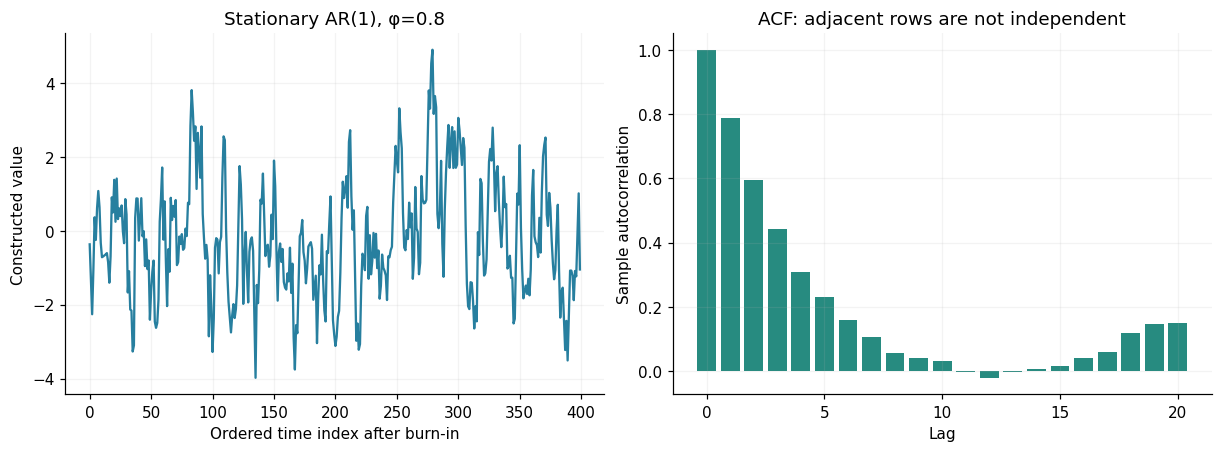

**تفسیر خروجی اجرای حاضر:** n=400 ولی تقریب n مؤثرِ AR(1) با φ معلوم=44.4 است؛ ACF نمونه در lag۱=0.787. این فرمول برای وابستگی یا drift دلخواه معتبر نیست.

In [29]:
rng=np.random.default_rng(202628)
from statsmodels.tsa.stattools import acf
phi=.8; eps=rng.normal(size=700); series=np.zeros(700)
for i in range(1,len(series)): series[i]=phi*series[i-1]+eps[i]
series=series[300:]; coefficients=acf(series,nlags=20,fft=True)
fig,axes=plt.subplots(1,2,figsize=(11,4),layout='constrained'); axes[0].plot(np.arange(len(series)),series,color=BLUE); axes[0].set(xlabel='Ordered time index after burn-in',ylabel='Constructed value',title='Stationary AR(1), φ=0.8'); axes[1].bar(np.arange(21),coefficients,color=TEAL); axes[1].set(xlabel='Lag',ylabel='Sample autocorrelation',title='ACF: adjacent rows are not independent'); show()
say(f'n={len(series)} ولی تقریب n مؤثرِ AR(1) با φ معلوم={len(series)*(1-phi)/(1+phi):.1f} است؛ ACF نمونه در lag۱={coefficients[1]:.3f}. این فرمول برای وابستگی یا drift دلخواه معتبر نیست.')

#### راهنمای خواندن نمودار و نتیجه

پنل اول ترتیب نوسان‌ها و پنل دوم ACF را نشان می‌دهد. میلهٔ lag=۰ تعریفاً۱ است و رابطهٔ علمی تازه‌ای نیست. ACF نمونه از φ^lag دقیقاً پیروی نمی‌کند. ناحیه‌های اطمینان تقریبیِ ACF در مدل‌های مختلف فرض‌های متفاوت دارند؛ اینجا عمداً فقط ضرایب بدون نوار قطعیت رسم می‌شوند. روند یا فصل قوی هم می‌تواند همبستگی ظاهری بسازد.

#### دام رایج

ارزیابی تصادفی زمانی را فقط به دلیل راحتی اجرا انتخاب نکنید. زنجیرهٔ ویژگی→زمان دسترسی→افق پیش‌بینی باید قابل ممیزی باشد.

#### تمرین

چرا مدلی که در۲۰۱۱ عالی بوده ممکن است در۲۰۱۲ افت کند، حتی با کد بدون اشکال؟

#### پاسخ تشریحی

تغییر کاربران، نرخ پایه، سیاست، سنجه‌گیری یا رابطهٔ ورودی و پاسخ ممکن است رخ داده باشد. باید دادهٔ تازه، خط پایه و انواع drift را بررسی کرد؛ افت خودکار علت خاصی را اثبات نمی‌کند.

## فصل ۸ · دادهٔ قابل اعتماد و تصمیم مسئولانه

### درس 29. مهندسی داده برای تحلیل: Grain، Join، Schema و آزمون

**پرسش شروع:** چرا فقط با اضافه‌کردن جدول کاربران، جمع فروش ناگهان زیاد شد؟

#### مفهوم، دقیق اما ساده

Grain یعنی هر سطر دقیقاً نمایندهٔ چیست. جدول سفارش، سفارش‌قلم و شخص، grain یکسان ندارند. در join، تکرار کلید در سمت بُعد می‌تواند هر سطر واقعیت را چند بار تکثیر کند؛ جمع‌ها دیگر به سؤال اولیه پاسخ نمی‌دهند. پیش از ادغام، یکتایی، نوع رابطهٔ یک‌به‌یک/چندبه‌یک، کلیدهای بی‌تطابق و زمان اعتبار رکورد را بررسی کنید. حذف تکرار با keep=first بدون منطق کسب‌وکار فقط خطا را پنهان می‌کند. Schema شامل نوع، کران، مجازبودن null، واحد و قرارداد معنایی است. آزمون داده فقط syntax نیست: جمع مبلغ، تعداد سفارش یکتا و مقدارهای شناخته‌شده باید قبل و بعد reconcile شوند.

#### فرمول و قرارداد

```text
Fact grain: one row per order
Many-to-one join requires unique dimension keys.
Assertions: unique keys + reconciliation + unmatched-key audit.
```

#### مثال حل‌شده

سه سفارش با user_idهای۱،۲،۲ و مبلغ‌های۱۰۰،۲۰۰،۳۰۰ داریم؛ جمع۶۰۰. در بُعد کاربر، شناسه۲ به اشتباه دو سطر دارد. join خام دو سفارش مربوط به۲ را دو بار می‌شمارد و جمع۱٬۱۰۰ می‌شود. validate="many_to_one" ادغام را متوقف می‌کند. نسخهٔ معتبرِ بُعد با قاعدهٔ اعلام‌شدهٔ «یک رکورد جاری تأییدشده برای هر شخص» جدا ساخته می‌شود. در مثال واقعی، رکورد تاریخی باید با تاریخ مؤثر join شود، نه حذف دلخواه یک سطر.

Expected quality guard caught duplicate dimension keys: Merge keys are not unique in right dataset; not a many-to-one merge


,order_id,user_id,amount,group,_merge
0,1,1,100,A,both
1,2,2,200,B,both
2,3,2,300,B,both


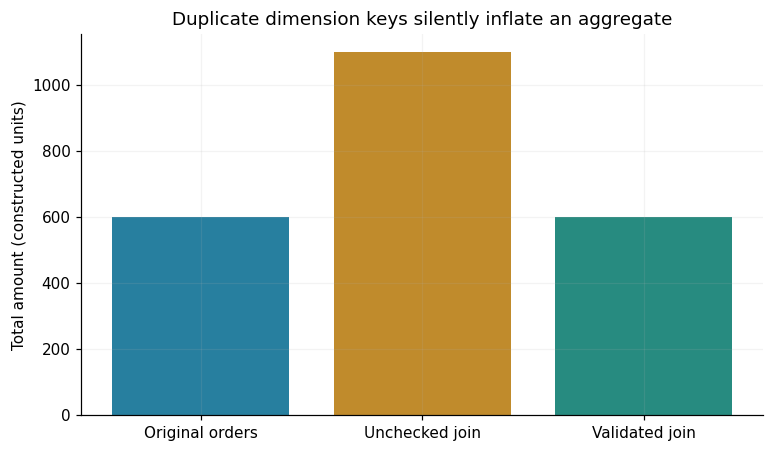

**تفسیر خروجی اجرای حاضر:** جمع پایه=600، join غلط=1100 و join معتبر=600. کنترل یکتایی، شمارش کلید و تطبیق جمع جلوی یک نتیجهٔ عددیِ ظاهراً معتبر را گرفت.

In [30]:
rng=np.random.default_rng(202629)
orders=pd.DataFrame({'order_id':[1,2,3],'user_id':[1,2,2],'amount':[100,200,300]}); bad_users=pd.DataFrame({'user_id':[1,2,2],'group':['A','B','B']})
inflated=orders.merge(bad_users,on='user_id')
try:
    orders.merge(bad_users,on='user_id',validate='many_to_one')
except pd.errors.MergeError as exc:
    print('Expected quality guard caught duplicate dimension keys:',str(exc))
confirmed_users=pd.DataFrame({'user_id':[1,2],'group':['A','B']}); valid=orders.merge(confirmed_users,on='user_id',validate='many_to_one',indicator=True)
assert valid.order_id.is_unique and valid.amount.sum()==orders.amount.sum() and valid['_merge'].eq('both').all()
display(valid); fig,ax=plt.subplots(); ax.bar(['Original orders','Unchecked join','Validated join'],[orders.amount.sum(),inflated.amount.sum(),valid.amount.sum()],color=[BLUE,GOLD,TEAL]); ax.set(ylabel='Total amount (constructed units)',title='Duplicate dimension keys silently inflate an aggregate'); show()
say(f'جمع پایه={orders.amount.sum()}، join غلط={inflated.amount.sum()} و join معتبر={valid.amount.sum()}. کنترل یکتایی، شمارش کلید و تطبیق جمع جلوی یک نتیجهٔ عددیِ ظاهراً معتبر را گرفت.')

#### راهنمای خواندن نمودار و نتیجه

جدول قبل و بعد تعداد سطر و جمع را با هم نشان می‌دهد. یک ردیف بیشتر ممکن است مشروع باشد، مثلاً تبدیل سفارش به قلم؛ اما در آن صورت جمع مبلغ سطح سفارش دیگر بدون اصلاح قابل جمع‌زدن نیست. پیام خطای validate در این درس خروجیِ مورد انتظارِ کنترل کیفیت است و با try/except محدود ثبت می‌شود، نه خطای پنهان‌شدهٔ تحلیل.

#### دام رایج

COUNT(*) و COUNT(DISTINCT order_id) یک چیز نیستند. DISTINCT پس از join همیشه درمان نیست؛ ممکن است رکوردهای واقعیِ هم‌مقدار را حذف کند.

#### تمرین

اگر دو کاربر نام یکسان داشته باشند، آیا نام می‌تواند کلید یکتای join باشد؟

#### پاسخ تشریحی

معمولاً نه؛ کلید پایدار و تعریف‌شده لازم است. یکتایی اتفاقی در فایل کوچک، قرارداد پایدار داده محسوب نمی‌شود. کیفیت کلید و رکوردهای بی‌تطابق را کنترل کنید.

### درس 30. خطای اندازه‌گیری، Reliability و توافق ابزارها

**پرسش شروع:** دو خط‌کش همیشه یک سانتی‌متر اختلاف دارند ولی همبستگی‌شان نزدیک یک است؛ آیا توافق دارند؟

#### مفهوم، دقیق اما ساده

همبستگی شدت همراهی را می‌سنجد، نه توافق عددی دو ابزار. یک خطای ثابت می‌تواند همبستگی را دست‌نخورده بگذارد و همهٔ اندازه‌ها را جابه‌جا کند. در Bland–Altman، اختلاف دو ابزار در برابر میانگین آن‌ها رسم می‌شود تا سوگیری ثابت، وابستگی اختلاف به اندازه و پراکندگی دیده شود. حدود توافقِ ساده میانگین اختلاف±۱٫۹۶SD اختلاف‌اند و CI برای میانگین اختلاف نیستند؛ این تعبیر به فرض‌های توزیع و استقلال وابسته است و در دادهٔ تکراری باید اصلاح شود. خطای تصادفی کلاسیکِ مستقل در پیش‌بین، شیب رگرسیون ساده را معمولاً به صفر می‌کشد؛ در خطاهای افتراقی یا پیچیده چنین قاعدهٔ ساده‌ای نداریم.

#### فرمول و قرارداد

```text
Agreement bias=mean(A−B)
Approx. limits of agreement=mean difference±1.96 SD(differences)
Correlation is invariant to an additive constant.
```

#### مثال حل‌شده

۲۰۰ طول واقعیِ ساخته‌شده را حول۲۰ بسازید. ابزار A نویز۰٫۲ و ابزار B علاوه بر نویز۰٫۲، سوگیری۱ واحد دارد. همبستگی می‌تواند بسیار بالا بماند اما اختلاف A−B نزدیک−۱ است. اگر تلرانسِ کاربرد ±۰٫۳ باشد، همبستگی بالا کافی نیست. در مثال مستقلِ خطای پیش‌بین، افزودن نویز به X ممکن است شیب پیش‌بینی y را کم کند؛ آن را با خطای ثبت y یا خطای واحد یکی ندانید.

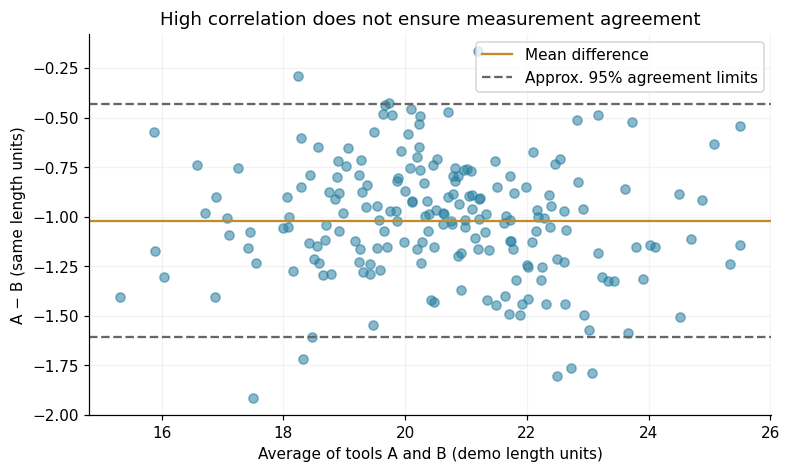

**تفسیر خروجی اجرای حاضر:** r=0.9888 ولی سوگیری A−B=-1.018 است؛ حدود توافق تقریبی [-1.605,-0.431]. این‌ها CI میانگین یا حدود مشخصات ابزار نیستند.

In [31]:
rng=np.random.default_rng(202630)
latent=rng.normal(20,2,200); tool_a=latent+rng.normal(scale=.2,size=200); tool_b=latent+1+rng.normal(scale=.2,size=200); differences=tool_a-tool_b; center=differences.mean(); sd=differences.std(ddof=1)
fig,ax=plt.subplots(); ax.scatter((tool_a+tool_b)/2,differences,color=BLUE,alpha=.55); ax.axhline(center,color=GOLD,label='Mean difference'); ax.axhline(center-1.96*sd,color='0.4',ls='--',label='Approx. 95% agreement limits'); ax.axhline(center+1.96*sd,color='0.4',ls='--'); ax.set(xlabel='Average of tools A and B (demo length units)',ylabel='A − B (same length units)',title='High correlation does not ensure measurement agreement'); ax.legend(); show()
say(f'r={np.corrcoef(tool_a,tool_b)[0,1]:.4f} ولی سوگیری A−B={center:.3f} است؛ حدود توافق تقریبی [{center-1.96*sd:.3f},{center+1.96*sd:.3f}]. این‌ها CI میانگین یا حدود مشخصات ابزار نیستند.')

#### راهنمای خواندن نمودار و نتیجه

محور افقی میانگین دو اندازه و عمودی اختلاف A−B در همان واحد است. خط وسط میانگین اختلاف و دو خط بیرونی حدود توافق تقریبی‌اند. این خط‌ها حدود مجاز مهندسی نیستند و برای قضاوت کفایت ابزار باید با نیاز عملیِ ازپیش‌تعریف‌شده مقایسه شوند. تعداد محدود مشاهده، برای خود حدود توافق نیز عدم‌قطعیت ایجاد می‌کند که در این نمایش برآورد نشده است.

#### دام رایج

Pearson r بالا یا R² بالا را به‌جای توافق و کالیبراسیون ابزار گزارش نکنید. تغییر واحد یا سوگیری ثابت را با «پرت» رفع نکنید.

#### تمرین

اگر B=A+۱ دقیقاً باشد، همبستگی چند و میانگین اختلاف A−B چند است؟

#### پاسخ تشریحی

با واریانس غیرصفر A، همبستگی دقیقاً۱ و میانگین اختلاف−۱ است. همراهی کامل می‌تواند با عدم توافق ثابت همراه باشد.

### درس 31. آنتروپی، Cross-entropy و اطلاعات متقابل

**پرسش شروع:** پیش‌بینیِ غلط با اطمینان۹۹٫۹٪ چرا از غلط با احتمال۵۱٪ پرهزینه‌تر است؟

#### مفهوم، دقیق اما ساده

آنتروپی میزان عدم‌قطعیت یک توزیع را با واحد تعریف‌شده می‌سنجد؛ برای سکهٔ منصفانه با لگاریتم پایه۲، یک بیت است. آنتروپی برنولی در p=۰٫۵ بیشینه و در دو انتهای قطعی صفر است. Cross-entropy یا log loss، توزیع پیش‌بینی را با پیامد می‌سنجد و به پیش‌بینیِ بسیار مطمئنِ نادرست جریمهٔ بزرگ می‌دهد. این را با «درصد خطا» یکی ندانید؛ واحد log طبیعی nat و پایه۲ bit است. اطلاعات متقابل می‌تواند وابستگی غیرخطیِ فراتر از پیرسون را ببیند، ولی برآورد آن برای پیوسته‌ها، تعداد داده و شیوهٔ binning حساس است و اثبات علّیت نیست. اطلاعات بیشتر دربارهٔ یک برچسب لزوماً اطلاعات اخلاقاً مجاز برای تصمیم‌گیری نیست.

#### فرمول و قرارداد

```text
H(p)=−p log₂p−(1−p)log₂(1−p)
Binary log loss=−[y ln(q)+(1−y)ln(1−q)]
MI(X;Y)=Σp(x,y)log[p(x,y)/(p(x)p(y))].
```

#### مثال حل‌شده

اگر نتیجه واقعاً۱ شود، پیش‌بینی q=۰٫۹۹ زیان−ln(۰٫۹۹)≈۰٫۰۱ دارد، q=۰٫۵ حدود۰٫۶۹۳ و q=۰٫۰۰۱ حدود۶٫۹۰۸. با این حال، قضاوت کالیبراسیون از یک مشاهده ممکن نیست؛ زیان باید روی مجموعهٔ ارزیابی مناسب گزارش شود. در مثال Uشکل، پیرسون ممکن است صفر باشد ولی وابستگی واقعی وجود داشته باشد؛ MI مناسب می‌تواند آن را نشان دهد، با توجه به محدودیت تخمین. منحنی آنتروپی را هم به‌عنوان کیفیت پیش‌بینی یک مدل اشتباه نخوانید؛ توزیع و مدل پیش‌بینی دو نقش متفاوت دارند.

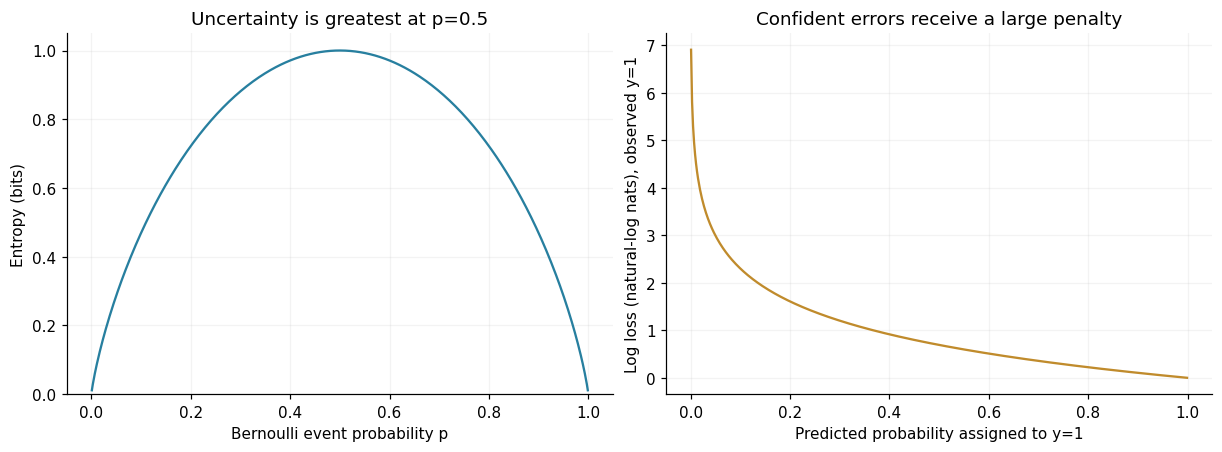

**تفسیر خروجی اجرای حاضر:** برای یک نتیجهٔ درستِ۱: log loss با q=.99 برابر 0.010 و با q=.001 برابر 6.908 nat است. این مقایسهٔ یک پیامد است؛ کالیبراسیون و کیفیت کل مدل از یک مشاهده نتیجه نمی‌شود.

In [32]:
rng=np.random.default_rng(202631)
p=np.linspace(.001,.999,500); entropy=-(p*np.log2(p)+(1-p)*np.log2(1-p)); loss=-np.log(p)
fig,axes=plt.subplots(1,2,figsize=(11,4),layout='constrained'); axes[0].plot(p,entropy,color=BLUE); axes[0].set(xlabel='Bernoulli event probability p',ylabel='Entropy (bits)',ylim=(0,1.05),title='Uncertainty is greatest at p=0.5'); axes[1].plot(p,loss,color=GOLD); axes[1].set(xlabel='Predicted probability assigned to y=1',ylabel='Log loss (natural-log nats), observed y=1',title='Confident errors receive a large penalty'); show()
say(f'برای یک نتیجهٔ درستِ۱: log loss با q=.99 برابر {-np.log(.99):.3f} و با q=.001 برابر {-np.log(.001):.3f} nat است. این مقایسهٔ یک پیامد است؛ کالیبراسیون و کیفیت کل مدل از یک مشاهده نتیجه نمی‌شود.')

#### راهنمای خواندن نمودار و نتیجه

پنل آنتروپی حول۰٫۵ متقارن است و نقطه‌های قطعی کم‌عدم‌قطعیت‌اند؛ این به معنای خوب‌بودن هر پیش‌بینیِ مطمئن نیست. پنل log loss برای یک y=۱ ثابت، هرچه احتمالِ داده‌شده به نتیجهٔ درست کمتر شود زیان بیشتر می‌شود. پایهٔ لگاریتم‌ها در دو پنل متفاوت و روی محور اعلام شده است.

#### دام رایج

حداقل‌کردن entropy خروجی، بدون توجه به درست‌بودن پیش‌بینی، می‌تواند فقط مدل را بیش‌اطمینان کند. برای log loss، clipکردن احتمال برای پایداری عددی باید روشن باشد.

#### تمرین

آیا مدلی که همیشه۰ یا۱ می‌گوید به دلیل آنتروپی کم حتماً بهتر است؟

#### پاسخ تشریحی

خیر. اگر با اطمینان غلط باشد، log loss بسیار بزرگ می‌شود. کالیبراسیون، قدرت تفکیک و هزینهٔ تصمیم باید با دادهٔ آزمون مناسب سنجیده شوند.

### درس 32. آمار مسئولانه: زیرگروه، حریم خصوصی و دفتر تصمیم

**پرسش شروع:** دقت کل۹۰٪ است؛ آیا مدل برای همه خوب است و می‌توان دادهٔ ریز را منتشر کرد؟

#### مفهوم، دقیق اما ساده

میانگین خوب می‌تواند عملکرد بدِ یک زیرگروه کوچک را پنهان کند. ارزیابی مسئولانه باید نرخ پایه، معیارهای متناسب با خطا، حجم هر گروه، عدم‌قطعیت و زمینهٔ استفاده را کنار هم بگذارد. معیارهای عدالت مانند برابری نرخ مثبت یا برابری خطای شرطی یک مفهوم واحد نیستند و گاهی با نرخ‌های پایهٔ متفاوت در تعارض‌اند؛ انتخاب باید مسئله‌محور و با مشارکت ذی‌نفعان باشد. حذف نام افراد به‌تنهایی ناشناس‌سازی نیست؛ ترکیب چند ویژگی یا اتصال به فایل دیگر می‌تواند بازشناسایی کند. تجمیع، حداقل‌سازی داده، کنترل دسترسی و روش‌های رسمیِ حریم خصوصی نقش‌های متفاوت دارند. هیچ‌کدام از یک مثال کوچک مجوز تصمیم پرخطر دربارهٔ فرد نمی‌سازد.

#### فرمول و قرارداد

```text
Aggregate performance = weighted subgroup performance
Responsible record: intended use + evidence + uncertainty + harm + privacy + monitoring + owner.
```

#### مثال حل‌شده

۹۰۰ مورد گروهA با۹۵٪ صحت و۱۰۰ مورد گروهB با۴۵٪ صحت، دقت کلی۹۰٪ می‌سازند: (۸۵۵+۴۵)/۱۰۰۰. اعلام فقط۹۰٪ شکست در گروهB را پنهان می‌کند. این دو گروه، برچسب مصنوعی‌اند و ویژگی حساس واقعی افراد نیستند. مثال دوم: جدول بدون نامی که سن دقیق، محل دقیق و زمان دقیق دارد ممکن است هنوز قابل اتصال به افراد باشد؛ «اسم را پاک کردم» تضمین محرمانگی نمی‌دهد. پیش از انتشار باید ضرورت هر فیلد و خطر ترکیب را بررسی کرد.

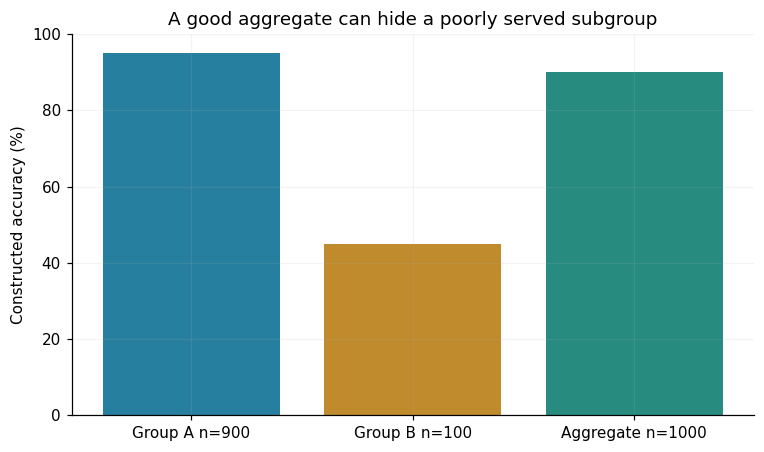

,review,required evidence
0,Target & intended use,"Population, unit, estimand"
1,Sampling & measurement,"Source, missingness, grain, units"
2,Held-out and subgroup evidence,"Metric, n, uncertainty, error costs"
3,Privacy & data minimization,"Necessity, access, re-identification review"
4,Monitoring & accountable owner,"Drift checks, failure threshold, review date"


**تفسیر خروجی اجرای حاضر:** دقت کل=90% از گروه‌های 95% و 45% به دست آمد. میانگین مناسب، عملکرد برابر یا محرمانگی داده را تضمین نمی‌کند؛ این مثال صرفاً ساختگی و آموزشی است.

In [33]:
rng=np.random.default_rng(202632)
correct=np.array([855,45]); totals=np.array([900,100]); rates=correct/totals; pooled=correct.sum()/totals.sum()
fig,ax=plt.subplots(); ax.bar(['Group A n=900','Group B n=100','Aggregate n=1000'],100*np.r_[rates,pooled],color=[BLUE,GOLD,TEAL]); ax.set(ylabel='Constructed accuracy (%)',ylim=(0,100),title='A good aggregate can hide a poorly served subgroup'); show()
checklist=pd.DataFrame({'review':['Target & intended use','Sampling & measurement','Held-out and subgroup evidence','Privacy & data minimization','Monitoring & accountable owner'],'required evidence':['Population, unit, estimand','Source, missingness, grain, units','Metric, n, uncertainty, error costs','Necessity, access, re-identification review','Drift checks, failure threshold, review date']}); display(checklist)
say(f'دقت کل={pooled:.0%} از گروه‌های {rates[0]:.0%} و {rates[1]:.0%} به دست آمد. میانگین مناسب، عملکرد برابر یا محرمانگی داده را تضمین نمی‌کند؛ این مثال صرفاً ساختگی و آموزشی است.')

#### راهنمای خواندن نمودار و نتیجه

هر میله نرخ صحت را با مخرج همان گروه نشان می‌دهد. گروه کوچک‌تر سهم کمتری در عدد کل دارد، ولی اهمیت تجربهٔ افرادش کمتر نیست. برای مقایسهٔ علمی واقعی به CI، تعریف برچسب و ماتریس خطا نیاز داریم؛ accuracy نمونهٔ این درس فقط برای آشکارکردن پنهان‌سازی در تجمیع است. از تفاوت این نرخ‌ها به‌تنهایی علت، تبعیض عمدی یا راه‌حل حقوقی نتیجه نمی‌گیریم.

#### دام رایج

عدد کلی، تعهد اخلاقی یا حقوقی را ثابت نمی‌کند. یک روش fairness یا چند نویز تصادفی نیز به‌تنهایی تضمین عدالت یا حریم خصوصی رسمی نیست.

#### تمرین

پیش از انتشار تحلیل برای تصمیم واقعی، چه پنج پرسشی می‌پرسید؟

#### پاسخ تشریحی

کمیت هدف و جمعیت چیست؟ منبع و کیفیت داده چگونه کنترل شد؟ عدم‌قطعیت و عملکرد زیرگروه‌ها چیست؟ چه آسیب یا بازشناسایی ممکن است؟ چه کسی پایش تغییر توزیع و اصلاح تصمیم را بر عهده دارد؟ پاسخ‌ها را همراه معیار توقف و بازبینی ثبت کنید.

## کنترل‌ها و گام بعدی

پس از مطالعه، برای یک مسئلهٔ خودتان جمعیت، واحد مشاهده، کمیت هدف، نمودار مناسب، عدم‌قطعیت، خطر سوگیری و معیار تصمیم را بنویسید. مدلی که در یک شبیه‌سازی برنده شد، به‌طور خودکار برای دادهٔ شما بهترین نیست. برای مطالعهٔ دقیق‌تر از منابع اصلی زیر استفاده کنید.
- [مدل‌های تعمیم‌یافته در statsmodels](https://www.statsmodels.org/stable/glm.html)
- [اصلاح چندآزمونی و BH](https://www.statsmodels.org/stable/generated/statsmodels.stats.multitest.multipletests.html)
- [نشت داده و Pipeline](https://scikit-learn.org/stable/common_pitfalls.html)
- [کالیبراسیون احتمال](https://scikit-learn.org/stable/modules/calibration.html)
- [مقدمهٔ پژوهشگران Conformal](https://arxiv.org/abs/2107.07511)
- [کتاب علّیت Hernán و Robins](https://www.hsph.harvard.edu/miguel-hernan/causal-inference-book/)
- [توابع توزیع و آزمون‌ها در SciPy](https://docs.scipy.org/doc/scipy/reference/stats.html)
- [اعتبارسنجی رابطهٔ Join در pandas](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.merge.html)

In [34]:
assert np.isclose((9+50)/(10+100),59/110)
assert np.isclose(.9*.01/(.9*.01+.05*.99),90/585)
assert np.all(group_rates[1]>group_rates[0]) and overall[0]>overall[1]
assert np.isclose(orders.amount.sum(),valid.amount.sum())
assert len(scores)==150 and rank==136
assert len(truth)==4000
say('کنترل‌های عددیِ سناریوهای مخرج، بیز، سیمپسون، join و رتبهٔ Conformal گذشتند. این کنترل‌ها برای مثال مرجع‌اند؛ با تغییر عمدی داده، انتظار تطابق با همین اعداد نداشته باشید.')

**تفسیر خروجی اجرای حاضر:** کنترل‌های عددیِ سناریوهای مخرج، بیز، سیمپسون، join و رتبهٔ Conformal گذشتند. این کنترل‌ها برای مثال مرجع‌اند؛ با تغییر عمدی داده، انتظار تطابق با همین اعداد نداشته باشید.